In [3]:
import os
print(os.getcwd())

/Users/helensoane/Desktop/Uni/QCES/Part III Project/Paper submission



──────────────────────────────────────────────────────────────────────────────────────────────────────────────
Shelf                 N pts  Thresh  CDW Top     Base    Thick      Max T     Mean T
──────────────────────────────────────────────────────────────────────────────────────────────────────────────
  *** Thwaites: fallback — no point exceeded 0.5°C ***
Thwaites                  7     0.5      350m      450m      100m     -1.04°C     -1.04°C
Ross                      9    -2.0        0m      800m      800m      1.24°C     -0.44°C
Dotson                    9     0.5      425m      800m      375m      0.88°C      0.67°C


/var/folders/dp/bxjb_th907g0tlby49jsjkhr0000gn/T/ipykernel_45175/252138462.py:104: RuntimeWarning: Mean of empty slice
  profile_mean = np.nanmean(profiles, axis=0)
/Users/helensoane/miniforge3/envs/CDA/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


Fimbul                    9     0.0      350m      800m      450m      0.73°C      0.63°C
PineIsland_West           9     0.5      300m      800m      500m      1.36°C      1.16°C
PineIsland_East           9     0.5      300m      800m      500m      1.36°C      1.16°C
  *** Crosson: fallback — no point exceeded 0.5°C ***
Crosson                   9     0.5      550m      750m      200m     -0.14°C     -0.14°C
Moscow_University         9     0.0      450m      700m      250m      0.25°C      0.20°C
Cook                      9     0.0      350m      475m      125m      0.07°C      0.03°C


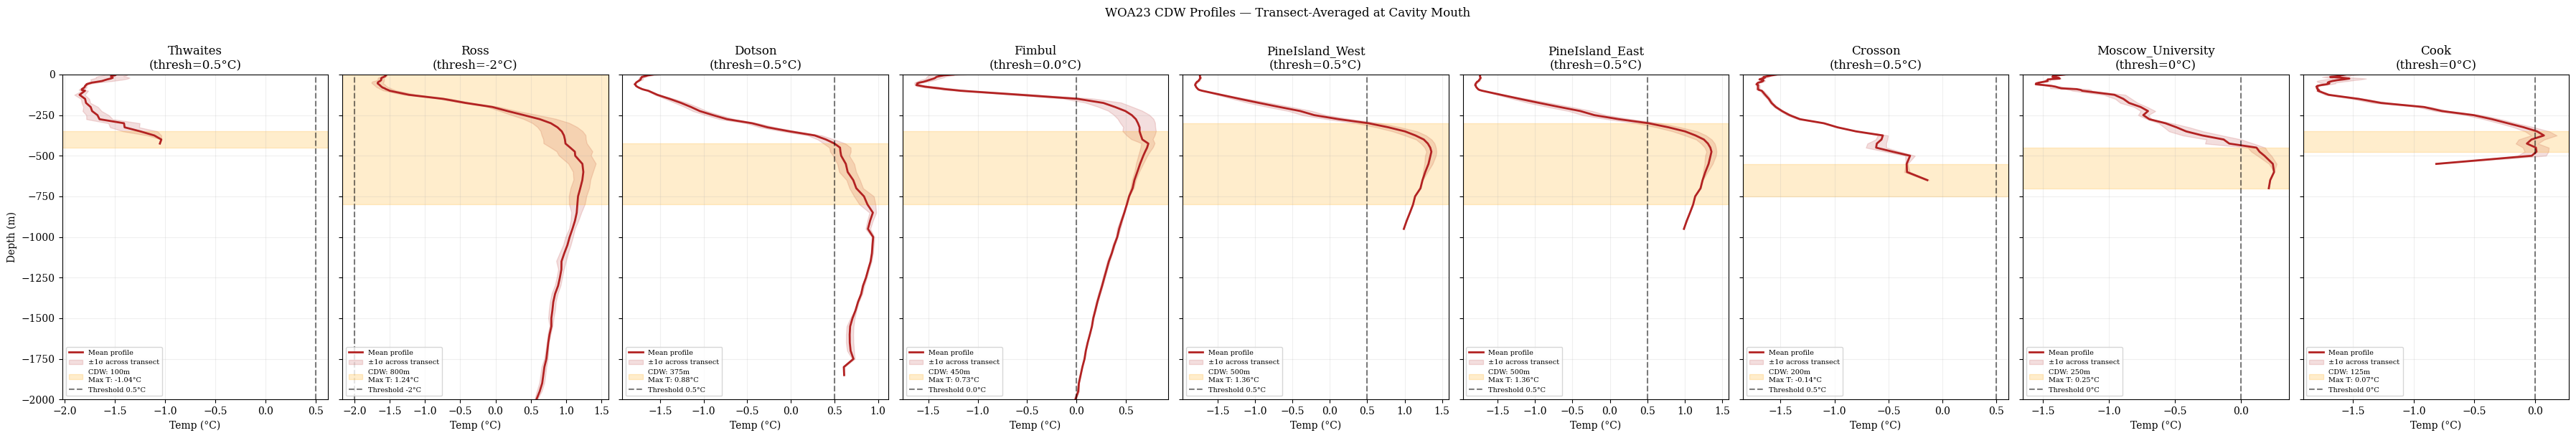


──────────────────────────────────────────────────
  cdw_top_obs (for sill analysis):
  'Thwaites': 350,
  'Ross': 0,
  'Dotson': 425,
  'Fimbul': 350,
  'PineIsland_West': 300,
  'PineIsland_East': 300,
  'Crosson': 550,
  'Moscow_University': 450,
  'Cook': 350,

  cdw_mean_obs (for melt rate):
  'Thwaites': -1.04,
  'Ross': -0.44,
  'Dotson': 0.67,
  'Fimbul': 0.63,
  'PineIsland_West': 1.16,
  'PineIsland_East': 1.16,
  'Crosson': -0.14,
  'Moscow_University': 0.20,
  'Cook': 0.03,
──────────────────────────────────────────────────


In [4]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'serif'

plt.rcParams['mathtext.fontset'] = 'cm'

ds    = xr.open_dataset('woa23_decav81B0_t00_04.nc', decode_times=False)
temp  = ds['t_an'].squeeze()
depth = ds['depth'].values
lat   = ds['lat'].values
lon   = ds['lon'].values

CDW_DEPTH_MIN = 0
CDW_DEPTH_MAX = 800

# ── Per-shelf mCDW thresholds ─────────────────────────────────────────────────
# Temperature-only threshold (salinity omitted). Thresholds as cited in paper (Supplementary Material)
cdw_threshold = {
    'Thwaites':          0.5,
    'PineIsland_West':   0.5,
    'PineIsland_East':   0.5,
    'Dotson':            0.5,
    'Crosson':           0.5,
    'Fimbul':            0.0,   
    'Moscow_University': 0,   
    'Cook':              0,
    'Ross':             -2
}
cdw_min= {
    'Thwaites':          200,
    'PineIsland_West':   200,
    'PineIsland_East':   200,
    'Dotson':            200,
    'Crosson':           200,
    'Fimbul':            345,   
    'Moscow_University': 200,   
    'Cook':              200,
    'Ross':             0
}

# ── Cavity mouth transect locations ──────────────────────────────────────────
# All transects at the ice shelf cavity mouth (ice front).
# Both mCDW thickness and depth-averaged mCDW temperature extracted here.
# Flow directions reflect the principal inflow direction at each cavity mouth.
# References: Biddle et al. (2017); Lauber et al. (2023); Jourdain et al. (2020)
shelf_config = {
   'Thwaites':          {'loc': (-73, -106.0), 'flow_az': 0,    'width_km': 40},
   'Ross':              {'loc': (-74.0, -173.0), 'flow_az': 0,    'width_km': 100},
   'Dotson':            {'loc': (-72.0, -112.7), 'flow_az': 10,  'width_km': 30},
   'Fimbul':            {'loc': (-69,   -1.5),  'flow_az': 0,    'width_km': 180},
   'PineIsland_West':        {'loc': (-71.5, -104.0), 'flow_az': 315,  'width_km': 25},
   'PineIsland_East':        {'loc': (-71.5, -104.0), 'flow_az': 315,  'width_km': 25},
   'Crosson':           {'loc': (-73.5, -109.5), 'flow_az': 45,    'width_km': 25},
   'Moscow_University': {'loc': (-65.5,  125.0), 'flow_az': 180,  'width_km': 40},
   'Cook':              {'loc': (-67.5,  153.0), 'flow_az': 180,  'width_km': 40},
}

def transect_points(centre_lat, centre_lon, flow_az_deg, half_width_km, n=9):
    perp_az  = (flow_az_deg + 90) % 360
    perp_rad = np.deg2rad(perp_az)
    km_per_lat = 111.0
    km_per_lon = 111.0 * np.cos(np.deg2rad(centre_lat))
    offsets_km = np.linspace(-half_width_km, half_width_km, n)
    dlat_per_km =  np.cos(perp_rad) / km_per_lat
    dlon_per_km =  np.sin(perp_rad) / km_per_lon
    lats = centre_lat + offsets_km * dlat_per_km
    lons = centre_lon + offsets_km * dlon_per_km
    return lats, lons

fig, axes = plt.subplots(1, len(shelf_config), figsize=(36, 6), sharey=True)

print(f"\n{'─'*110}")
print(f"{'Shelf':<20} {'N pts':>6} {'Thresh':>7} {'CDW Top':>8} {'Base':>8} "
      f"{'Thick':>8} {'Max T':>10} {'Mean T':>10}")
print(f"{'─'*110}")

cdw_top_obs    = {}   
cdw_mean_obs   = {}

for ax, (name, cfg) in zip(axes, shelf_config.items()):
    la, lo   = cfg['loc']
    flow_az  = cfg['flow_az']
    width_km = cfg['width_km']
    thresh   = cdw_threshold[name]

    # ── Transect profiles ─────────────────────────────────────────────────────
    t_lats, t_lons = transect_points(la, lo, flow_az, width_km, n=9)

    profiles = []
    for tla, tlo in zip(t_lats, t_lons):
        li  = np.argmin(np.abs(lat - tla))
        loi = np.argmin(np.abs(lon - tlo))
        p   = temp[:, li, loi].values.copy()
        if np.any(~np.isnan(p)):
            profiles.append(p)

    if len(profiles) == 0:
        ax.set_title(f'{name}\nNo Data')
        continue

    profiles     = np.array(profiles)
    profile_mean = np.nanmean(profiles, axis=0)
    profile_std  = np.nanstd(profiles,  axis=0)
    valid_full   = ~np.isnan(profile_mean)

    
    # ── CDW detection ─────────────────────────────────────────────────────────
    depth_min_shelf = cdw_min[name]  
    deep_idx     = (depth >= depth_min_shelf) & (depth <= CDW_DEPTH_MAX)
    depth_deep   = depth[deep_idx]
    profile_deep = profile_mean[deep_idx]
    std_deep     = profile_std[deep_idx]
    valid_deep   = ~np.isnan(profile_deep)

    cdw_mask = (profile_deep > thresh) & valid_deep

    if np.any(cdw_mask):
        cdw_depths    = depth_deep[cdw_mask]
        cdw_top       = cdw_depths.min()
        cdw_base      = cdw_depths.max()
        cdw_thickness = cdw_base - cdw_top
        cdw_max_temp  = np.nanmax(profile_deep[cdw_mask])
        cdw_mean_temp = np.nanmean(profile_deep[cdw_mask])
    else:
        # Fallback: T-max core
        valid_indices = np.where(valid_deep)[0]
        if len(valid_indices) == 0:
            ax.set_title(f'{name}\nNo Data'); continue
        core_idx      = valid_indices[np.argmax(profile_deep[valid_deep])]
        cdw_max_temp  = float(profile_deep[core_idx])
        cdw_mean_temp = cdw_max_temp
        cdw_top       = float(depth_deep[max(0, core_idx - 2)])
        cdw_base      = float(depth_deep[min(len(depth_deep)-1, core_idx + 2)])
        cdw_thickness = cdw_base - cdw_top
        print(f"  *** {name}: fallback — no point exceeded {thresh}°C ***")

    # ── Store for downstream use ──────────────────────────────────────────────
    cdw_top_obs[name]  = cdw_top
    cdw_mean_obs[name] = cdw_mean_temp

    print(f"{name:<20} {len(profiles):>6} {thresh:>7.1f} {cdw_top:>8.0f}m "
          f"{cdw_base:>8.0f}m {cdw_thickness:>8.0f}m "
          f"{cdw_max_temp:>9.2f}°C {cdw_mean_temp:>9.2f}°C")

    # ── Plot ──────────────────────────────────────────────────────────────────
    ax.plot(profile_mean[valid_full], -depth[valid_full],
            color='firebrick', lw=2, label='Mean profile')
    ax.fill_betweenx(-depth[valid_full],
                     (profile_mean - profile_std)[valid_full],
                     (profile_mean + profile_std)[valid_full],
                     color='firebrick', alpha=0.15, label='±1σ across transect')
    ax.axhspan(-cdw_base, -cdw_top, color='orange', alpha=0.2,
               label=f'CDW: {cdw_thickness:.0f}m\nMax T: {cdw_max_temp:.2f}°C')
    ax.axvline(thresh, color='black', ls='--', alpha=0.5,
               label=f'Threshold {thresh}°C')
    ax.set_title(f'{name}\n(thresh={thresh}°C)')
    ax.set_xlabel('Temp (°C)')
    ax.set_ylim(-2000, 0)
    ax.grid(True, alpha=0.2)
    ax.legend(loc='lower left', fontsize=7)

axes[0].set_ylabel('Depth (m)')
plt.suptitle('WOA23 CDW Profiles — Transect-Averaged at Cavity Mouth', y=1.01)
plt.tight_layout()
plt.show()

print(f"\n{'─'*50}")
print("  cdw_top_obs (for sill analysis):")
for name, val in cdw_top_obs.items():
    print(f"  '{name}': {val:.0f},")
print(f"\n  cdw_mean_obs (for melt rate):")
for name, val in cdw_mean_obs.items():
    print(f"  '{name}': {val:.2f},")
print(f"{'─'*50}")

In [5]:
cdw_top_obs={
  
  'Thwaites': 400,
  'Ross': 100,
  'Dotson': 425,
  'Fimbul': 345,
  'PineIsland_East': 300,
  'PineIsland_West': 300,
  'Crosson': 425,
  'Moscow_University': 450,
  'Cook': 350,
}
cdw_mean_obs={
  
  
  'Thwaites':1,
  'Ross':0,
  'Dotson': 0.67,
  'Fimbul': 0.63,
  'PineIsland_East': 1.16,
  'PineIsland_West': 1.16,
  'Crosson': 0.67,
  'Moscow_University': 0.2,
  'Cook': 0.03 #from the CDW data, Cook seems to be cooler...
  ,}

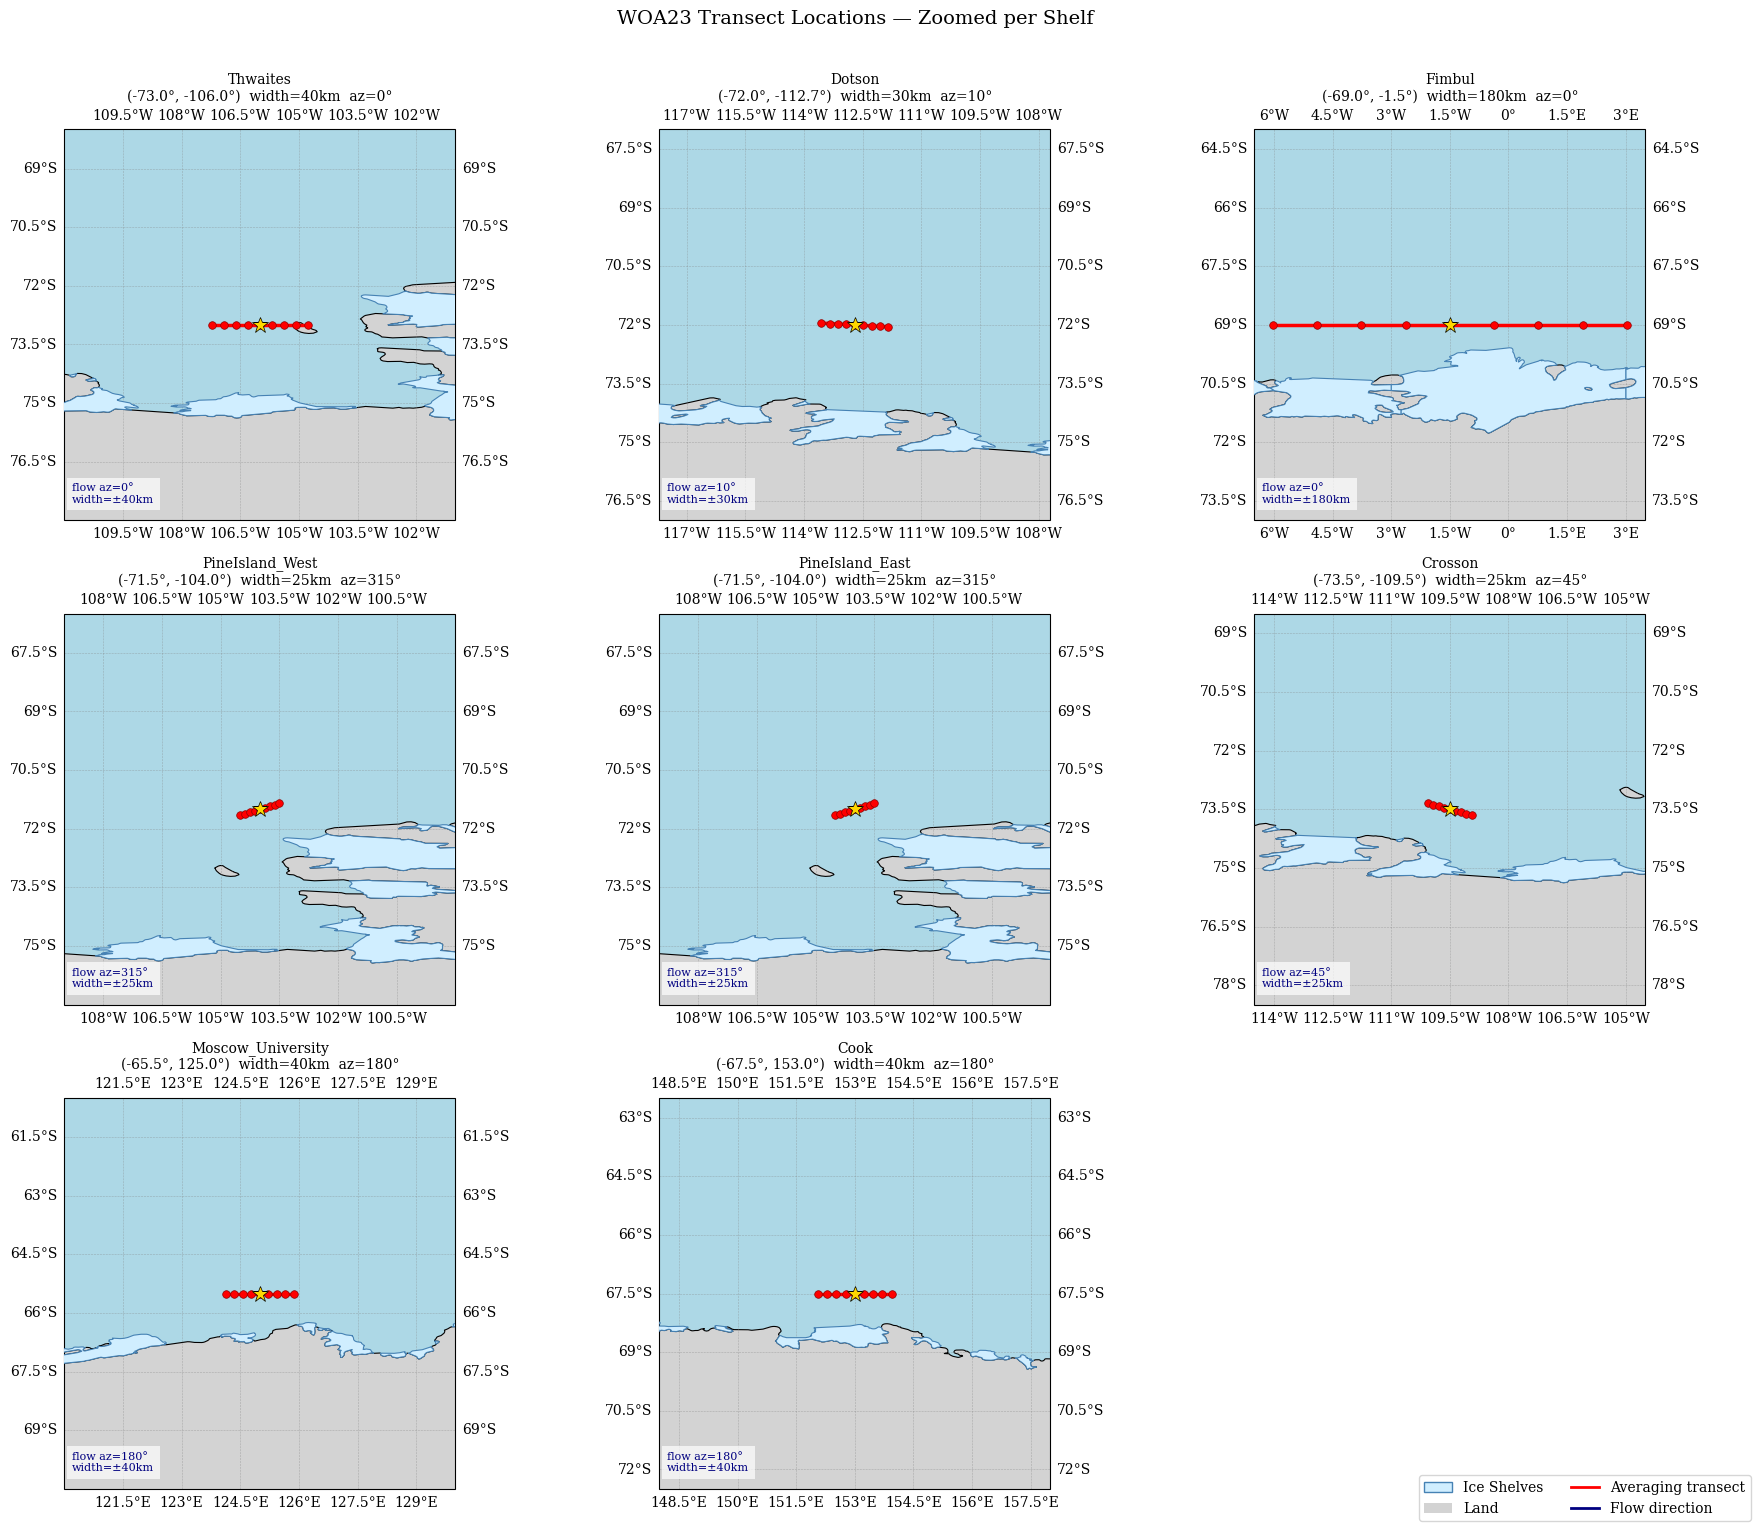

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.feature import NaturalEarthFeature
import matplotlib.patheffects as path_effects
shelf_config = {
   'Thwaites':          {'loc': (-73, -106.0), 'flow_az': 0,    'width_km': 40},
   #'Ross':              {'loc': (-74.0, -173.0), 'flow_az': 0,    'width_km': 100},
   'Dotson':            {'loc': (-72.0, -112.7), 'flow_az': 10,  'width_km': 30},
   'Fimbul':            {'loc': (-69,   -1.5),  'flow_az': 0,    'width_km': 180},
   'PineIsland_West':        {'loc': (-71.5, -104.0), 'flow_az': 315,  'width_km': 25},
   'PineIsland_East':        {'loc': (-71.5, -104.0), 'flow_az': 315,  'width_km': 25},
   'Crosson':           {'loc': (-73.5, -109.5), 'flow_az': 45,    'width_km': 25},
   'Moscow_University': {'loc': (-65.5,  125.0), 'flow_az': 180,  'width_km': 40},
   'Cook':              {'loc': (-67.5,  153.0), 'flow_az': 180,  'width_km': 40},
}


zoom_pad = {
    'Thwaites':          5.0,
    #'Ross':              5.0,
    'Dotson':            5.0,
    'Fimbul':            5.0,
    'PineIsland_West':              5.0,
    'PineIsland_East':        5.0,
    'Crosson':           5.0,
    'Moscow_University': 5.0,
    'Cook':              5.0,
}

def transect_points(centre_lat, centre_lon, flow_az_deg, half_width_km, n=9):
    perp_az     = (flow_az_deg + 90) % 360
    perp_rad    = np.deg2rad(perp_az)
    km_per_lat  = 111.0
    km_per_lon  = 111.0 * np.cos(np.deg2rad(centre_lat))
    offsets_km  = np.linspace(-half_width_km, half_width_km, n)
    dlat_per_km =  np.cos(perp_rad) / km_per_lat
    dlon_per_km =  np.sin(perp_rad) / km_per_lon
    lats = centre_lat + offsets_km * dlat_per_km
    lons = centre_lon + offsets_km * dlon_per_km
    return lats, lons

# ── Plot ──────────────────────────────────────────────────────────────────────
n     = len(shelf_config)
ncols = 3
nrows = int(np.ceil(n / ncols))

fig, axes = plt.subplots(nrows, ncols,
                          figsize=(6 * ncols, 5 * nrows),
                          subplot_kw={'projection': ccrs.PlateCarree()})
axes = axes.flatten()

ice_shelf_feature = NaturalEarthFeature(
    category='physical', name='antarctic_ice_shelves_polys',
    scale='10m', facecolor='#d0eeff', edgecolor='steelblue', linewidth=0.8
)

for i, (name, cfg) in enumerate(shelf_config.items()):
    ax  = axes[i]
    la, lo   = cfg['loc']
    flow_az  = cfg['flow_az']
    width_km = cfg['width_km']
    pad      = zoom_pad[name]

    # ── Base map ──────────────────────────────────────────────────────────────
    ax.set_extent([lo - pad, lo + pad, la - pad, la + pad],
                  crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.LAND,      facecolor='lightgray',  zorder=1)
    ax.add_feature(cfeature.OCEAN,     facecolor='lightblue',  zorder=0)
    ax.add_feature(cfeature.COASTLINE, linewidth=0.8,          zorder=2)
    ax.add_feature(ice_shelf_feature,                          zorder=3)
    ax.gridlines(draw_labels=True, linewidth=0.4, color='gray',
                 alpha=0.5, linestyle='--', x_inline=False, y_inline=False)

    # ── Transect line ─────────────────────────────────────────────────────────
    t_lats, t_lons = transect_points(la, lo, flow_az, width_km, n=9)

    # Plot transect as a line
    ax.plot(t_lons, t_lats, color='red', lw=2.5, zorder=6,
            transform=ccrs.PlateCarree(), label='Averaging transect')

    # Plot individual sample points
    ax.scatter(t_lons, t_lats, color='red', s=30, zorder=7,
               transform=ccrs.PlateCarree(), edgecolors='darkred', linewidths=0.5)

   
    # ── Centre point ───────────────────────────────────────────────────
    ax.plot(lo, la, marker='*', markersize=12, color='gold',
            transform=ccrs.PlateCarree(), zorder=9,
            markeredgecolor='black', markeredgewidth=0.5)

    # ── Labels ─────────────────────────────────────────────────────────────
    ax.set_title(f'{name}\n({la:.1f}°, {lo:.1f}°)  width={width_km}km  az={flow_az}°',
                 fontsize=10)

    ax.text(0.02, 0.04,
            f'flow az={flow_az}°\nwidth=±{width_km}km',
            transform=ax.transAxes, fontsize=8, color='navy',
            va='bottom',
            bbox=dict(facecolor='white', alpha=0.7, edgecolor='none'))

# ── Hide unused subplots ──────────────────────────────────────────────────────
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

# ── Legend ────────────────────────────────────────────────────────────────────
legend_handles = [
    mpatches.Patch(facecolor='#d0eeff', edgecolor='steelblue', label='Ice Shelves'),
    mpatches.Patch(facecolor='lightgray', label='Land'),
    plt.Line2D([0], [0], color='red',  lw=2, label='Averaging transect'),
    plt.Line2D([0], [0], color='navy', lw=2, label='Flow direction'),
]
fig.legend(handles=legend_handles, loc='lower right',
           fontsize=10, frameon=True, ncol=2)

plt.suptitle('WOA23 Transect Locations — Zoomed per Shelf', fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig('woa23_transect_locations.png', dpi=150, bbox_inches='tight')
plt.show()

In [7]:
from scipy.integrate import quad


def compute_m(coeffs, H_f, delta_H, y_f, y_start, A, T2, l, beta):
    """
    y_start, y_f : GL-relative distances (km)
    coeffs       : seabed polynomial in d' = y - y_start
    H(y)         : ice base in GL-relative coords
    p2(y)        : seabed in GL-relative coords (via d' = y - y_start)
    """
    def H(y):       return H_f + delta_H * np.exp(-y / l)
    def H_prime(y): return -(delta_H / l) * np.exp(-y / l)
    def p2(y):      return np.polyval(coeffs, y - y_start)  # d' = y - y_start

    def integrand(y):
        wc    = H(y) - p2(y)          # water column (m)
        slope = H_prime(y)  # |dH/dy| in m/km
        return max(wc, 0.0) * slope   # water column must be positive

    integral, _ = quad(integrand, y_start, y_f)  

    Tf    = -1.9
    g     = 9.8
    rho_1 = 1027.55
    rho_2 = 1027.75
    rho_i = 917
    L     = 3.34e5
    f     = 1e-4
    C_p   = 3974
    a = 0.094
    k = a*(T2 - Tf) * g * (rho_2 - rho_1) * C_p / (rho_i * L * f * (beta + 1))

   
  
    A_m2 = A * 1e6   # km² → m²

    m_per_sec = k * integral / A_m2
    return m_per_sec * 31536000   # m/yr


Thwaites: fitting ice base up to 80.0 km from GL 
  ss_res = 27985.92
  ss_tot = 705237.11
  r2_ice = 0.9603
  z_ice range: -994.3 to -331.7
  z_ice mean:  -511.7
  n points:    17
dist_ice[0]=0.00, dist_ice[-1]=80.00
  RMSE_ice = 40.57 m
  H_f=-330.2m, delta_H=-702.6m, l=19.6km
  slope at GL (d=0):            -35.781 m/km
 Thwaites
  slope at cavity start (d=15km): -16.669 m/km
  mean slope over cavity:       4.852 m/km

  Thwaites
  GL → ice front:     80 km
  Ice base at d=0:    -994 m  (should be deepest)
  Ice base at end:    -378 m  (should be shallowest)
  Exponential parameters (for melt model):
     H_f      = -330.239 m
     delta_H  = -702.609 m
     l        = 19.636 km
     R²       = 0.9603
  Cavity start:       8.5 km
  Ice depth @ start:  -786 m
  Bed depth @ start:  -786 m
  Cavity extent:      65 km
  Max cavity height:  896 m at 75 km

  Seabed polynomial (d' = dist from cavity start, km):
  Best degree: 2  R² = 0.9683
  -1.94e-01*d'^2 + 5.70e+00*d' + -741.35
  Vali

/var/folders/dp/bxjb_th907g0tlby49jsjkhr0000gn/T/ipykernel_45175/3120246214.py:258: RuntimeWarning: Mean of empty slice
  wav_ice = np.nanmean(ib_cavity, axis=1)



Cook: fitting ice base up to 105.0 km from GL 
  ss_res = 163277.75
  ss_tot = 217704.18
  r2_ice = 0.2500
  z_ice range: -514.4 to -104.8
  z_ice mean:  -349.2
  n points:    22
dist_ice[0]=0.00, dist_ice[-1]=105.00
  RMSE_ice = 86.15 m
  H_f=1145588.0m, delta_H=-1146019.5m, l=730867.3km
  slope at GL (d=0):            -1.568 m/km
 Cook
  slope at cavity start (d=0km): -1.568 m/km
  mean slope over cavity:       1.568 m/km
Cook: no intersection found, falling back to raw method

  Cook
  GL → ice front:     105 km
  Ice base at d=0:    -226 m  (should be deepest)
  Ice base at end:    -105 m  (should be shallowest)
  Exponential parameters (for melt model):
     H_f      = 1145587.984 m
     delta_H  = -1146019.501 m
     l        = 730867.252 km
     R²       = 0.2500
  Cavity start:       0.0 km
  Ice depth @ start:  -226 m
  Bed depth @ start:  -680 m
  Cavity extent:      105 km
  Max cavity height:  504 m at 105 km

  Seabed polynomial (d' = dist from cavity start, km):
  Best d

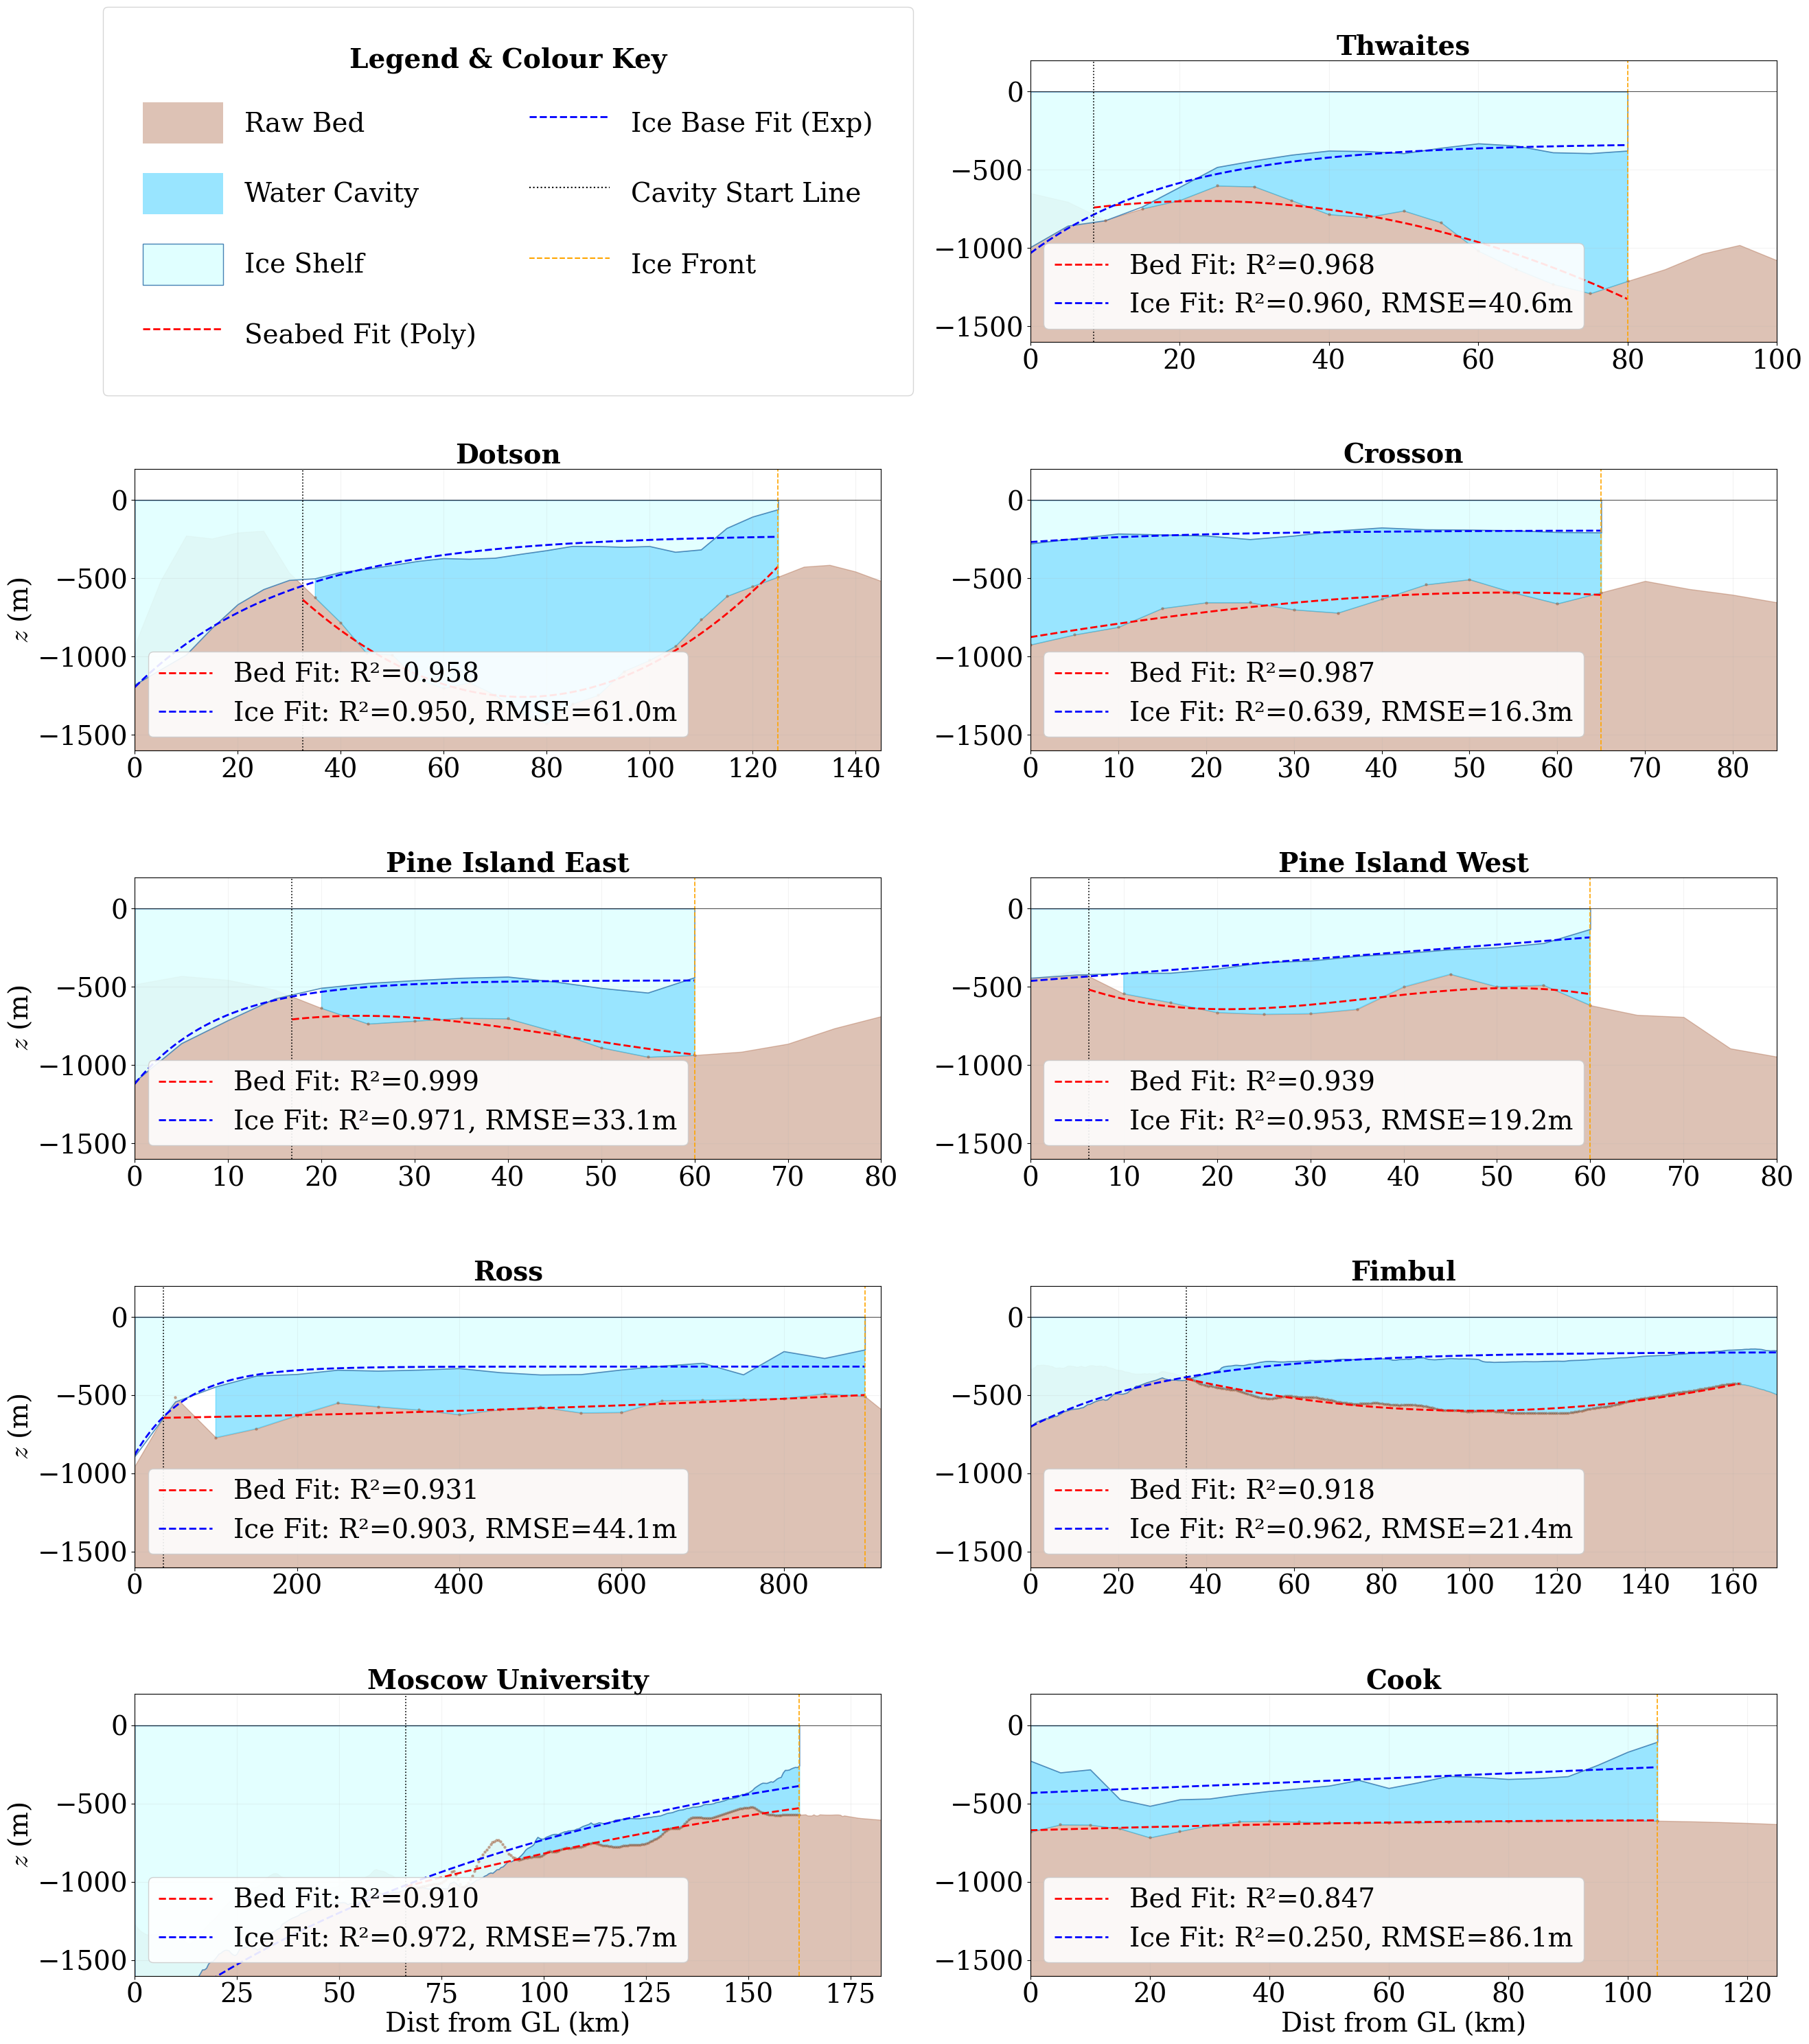


────────────────────────────────────────────────────────────────────────────────
Shelf          GL→Front   e-fold   R²ice  Cav start  Cav extent  Max cav H  BedDeg   R²bed
────────────────────────────────────────────────────────────────────────────────
Thwaites            80km    19.6m   0.960       8.5m         65m       896m       2   0.968
Dotson             125km    29.9m   0.950      32.6m         90m      1106m       2   0.958
Crosson             65km    18.8m   0.639       0.0m         65m       646m       3   0.987
PineIsland_East        60km     9.1m   0.971      16.9m         40m       497m       3   0.999
PineIsland_West        60km 317831.3m   0.953       6.3m         60m       487m       3   0.939
Ross               900km    63.1m   0.903      35.8m        900m       338m       2   0.931
Fimbul             240km    32.6m   0.962      35.5m        203m      2107m       2   0.918
Moscow_University       162km   105.4m   0.972      66.2m         69m       314m       2    0.9

In [8]:
import numpy as np
import rioxarray as rxr
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# ── Exponential ice-base model ───────────────────────────────────────────────
def exp_model(d, a, b, c):
    """
    Exponential ice-base profile.

    d : distance from grounding line (km)
    a : amplitude (difference between GL depth and asymptote)
    b : exponential rate parameter
    c : asymptotic ice-base depth toward the ice front

    Returns ice-base elevation (m).
    """
    return a * np.exp(b * d) + c

# ── 1. Load GeoTIFFs ──────────────────────────────────────────────────────────
surface   = rxr.open_rasterio('bm3_surface.tif',   masked=True).squeeze()
thickness = rxr.open_rasterio('bm3_thickness.tif', masked=True).squeeze()
mask_r    = rxr.open_rasterio('bm3_masks.tif',     masked=True).squeeze()
bed       = rxr.open_rasterio('bm3_bed.tif',       masked=True).squeeze()

mask_arr_full  = mask_r.values.astype(float).squeeze()
surf_arr_full  = surface.values.astype(float).squeeze()
thick_arr_full = thickness.values.astype(float).squeeze()
bed_arr_full   = bed.values.astype(float).squeeze()
x_all = mask_r.x.values
y_all = mask_r.y.values

# ── 2. Shelf definitions ──────────────────────────────────────────────────────
# 'Thwaites': {'x': (-1650e3, -1500e3), 'y': (-460e3, -375e3), 'flow_angle_deg':-185,  # flows roughly northwest 'bin_width_km': 5, 'gl_percentile': 5},'Thwaites_TWIT': {'x': (-1550e3, -1475e3), 'y': (-480e3, -450e3), 'flow_angle_deg': -140,  # flows roughly west'bin_width_km': 5, 'gl_percentile': 5},
shelves = {


    'Thwaites': {
    'x': (-1650e3, -1475e3),  # wider x to capture TWIT
    'y': (-480e3, -375e3),    # wider y to capture both
    'flow_angle_deg': -185,
    'bin_width_km': 5, 
    'gl_percentile': 5
    },

   'Dotson':      {'x': (-1720e3, -1300e3), 'y': (-710e3,  -600e3), 'flow_angle_deg': -180,  # flows roughly west
                  'bin_width_km': 5, 'gl_percentile': 5},

   'Crosson':     {'x': (-1600e3, -1475e3), 'y': (-575e3, -525e3),

                   'flow_angle_deg': 315-180, 'bin_width_km': 5, 'gl_percentile': 5},

   'PineIsland_East':  {'x': (-1625e3, -1550e3), 'y': (-375e3,  -250e3),

                   
                   'flow_angle_deg': 315-90, 'bin_width_km': 5, 'gl_percentile': 5},

   'PineIsland_West':  {'x': (-1700e3, -1625e3), 'y': (-375e3,  -250e3),

                   'flow_angle_deg': 315, 'bin_width_km': 5, 'gl_percentile': 5},

   'Ross':        {'x': (-600e3,   400e3),  'y': (-1400e3, -400e3),  'flow_angle_deg': 245, 'bin_width_km': 50, 'gl_percentile': 5},

   'Fimbul':      {'x': (-120e3,   265e3),  'y': (2010e3,  2250e3), 'flow': 'y', 'gl_side':'min'
   },

   'Moscow_University': {'x': (2150e3, 2190e3), 'y': (-1380e3,-1200e3),'flow': 'y', 'gl_side':'max'},

   'Cook':        {'x': (1000e3,   1180e3),  'y': (-2180e3,-2030e3),

                   'flow_angle_deg': 320, 'bin_width_km': 5, 'gl_percentile': 5},

}

display_names = {
    'PineIsland_East': 'Pine Island East',
    'PineIsland_West': 'Pine Island West',
    'Moscow_University': 'Moscow University',
}

def analyse_shelf(name, config):
    xmin, xmax = config['x']
    ymin, ymax = config['y']


    xi = np.where((x_all >= xmin) & (x_all <= xmax))[0]
    yi = np.where((y_all >= ymin) & (y_all <= ymax))[0]

    surf_r  = surf_arr_full[np.ix_(yi, xi)]
    thick_r = thick_arr_full[np.ix_(yi, xi)]
    mask_r2 = mask_arr_full[np.ix_(yi, xi)]
    bed_r   = bed_arr_full[np.ix_(yi, xi)]
    x_r     = x_all[xi]
    y_r     = y_all[yi]

    ib_r        = surf_r - thick_r
    cavity_mask = ((mask_r2 == 3) | (mask_r2 == 2)) & (ib_r < 0) & (thick_r > 10)
    ib_cavity   = np.where(cavity_mask, ib_r, np.nan)
    bed_below   = np.where(bed_r < 0, bed_r, np.nan)

    # ── Angled binning ────────────────────────────────────────────────────────
    if 'flow_angle_deg' in config:
        angle_deg    = config['flow_angle_deg']
        bin_width_km = config.get('bin_width_km', 10)
        angle_rad    = np.deg2rad(angle_deg)
        ux, uy       = np.cos(angle_rad), np.sin(angle_rad)

        XX, YY  = np.meshgrid(x_r, y_r)
        d_flow  = (XX * ux + YY * uy) / 1e3
        
        # GL = where ice is thickest (deepest ice base)
        ib_flat    = ib_cavity.flatten()
        dflow_flat = d_flow.flatten()
        valid      = np.isfinite(ib_flat)
        thresh     = np.nanpercentile(ib_flat[valid], 5)
        gl_dflow   = np.mean(dflow_flat[valid & (ib_flat <= thresh)])
        dist_2d    = d_flow - gl_dflow   # 0 at GL, positive toward ice front

        # ── Ice bins — original bounding box only ─────────────────────────────
        d_min = np.nanmin(dist_2d[cavity_mask])
        d_max = np.nanmax(dist_2d[cavity_mask])
        bins  = np.arange(d_min, d_max + bin_width_km, bin_width_km)
        bin_centres = 0.5 * (bins[:-1] + bins[1:])

        wav_ice = np.full(len(bin_centres), np.nan)
        wav_bed = np.full(len(bin_centres), np.nan)  # plotting only, aligned with dist_all
        n_ice   = np.zeros(len(bin_centres))

        for j, (b0, b1) in enumerate(zip(bins[:-1], bins[1:])):
            in_bin   = (dist_2d >= b0) & (dist_2d < b1)
            ice_vals = ib_cavity[in_bin]
            ice_vals = ice_vals[np.isfinite(ice_vals)]
            bed_vals_orig = bed_below[in_bin]
            bed_vals_orig = bed_vals_orig[np.isfinite(bed_vals_orig)]
            min_pts = 1 if name in ('Thwaites', 'Thwaites_TWIT') else 3  # ADD
            if len(ice_vals) >= min_pts:
                wav_ice[j] = np.mean(ice_vals)
                n_ice[j]   = len(ice_vals)
            if len(bed_vals_orig) >= 3:
                wav_bed[j] = np.mean(bed_vals_orig)

        wav_ice = np.where(n_ice >= 3, wav_ice, np.nan)
        good    = np.isfinite(wav_ice) & (n_ice >= 3)
        dist_ice = bin_centres[good]
        z_ice    = wav_ice[good]

        # ── Bed bins — extended 100km past ice front ──────────────────────────
        # Use full BedMachine grid projected onto flow direction
        ext_km       = 100
        px, py       = -uy, ux   # perpendicular unit vector

        # ── Only mesh a buffered region, not the full grid ────────────────────
        ext_km   = 100
        buffer_m = max(xmax - xmin, ymax - ymin) + (ext_km + 50) * 1e3

        xi_ext = np.where((x_all >= xmin - buffer_m) &
                          (x_all <= xmax + buffer_m))[0]
        yi_ext = np.where((y_all >= ymin - buffer_m) &
                          (y_all <= ymax + buffer_m))[0]

        x_ext2   = x_all[xi_ext]
        y_ext2   = y_all[yi_ext]
        bed_ext2 = bed_arr_full[np.ix_(yi_ext, xi_ext)]

        X_all2D, Y_all2D = np.meshgrid(x_ext2, y_ext2)
        d_all  = (X_all2D * ux + Y_all2D * uy) / 1e3 - gl_dflow
        dp_all = (X_all2D * px + Y_all2D * py) / 1e3

        # Cross-flow centre of shelf
        px_shelf = np.mean((XX * px + YY * py)[cavity_mask] / 1e3)
        half_width = bin_width_km * 1.5   # wider for bed

        d_max_ext    = d_max + ext_km
        bins_ext     = np.arange(d_min, d_max_ext + bin_width_km, bin_width_km)
        bin_centres_ext = 0.5 * (bins_ext[:-1] + bins_ext[1:])

        wav_bed_ext = np.full(len(bin_centres_ext), np.nan)

        for j, (b0, b1) in enumerate(zip(bins_ext[:-1], bins_ext[1:])):
            slab = (d_all >= b0) & (d_all < b1) & \
                   (np.abs(dp_all - px_shelf) <= half_width)
            bed_vals = bed_ext2[slab]
            bed_vals = bed_vals[np.isfinite(bed_vals) & (bed_vals < 0)]
            if len(bed_vals) >= 3:
                wav_bed_ext[j] = np.mean(bed_vals)

        good_bed = np.isfinite(wav_bed_ext)
        dist_bed = bin_centres_ext[good_bed]
        z_bed    = wav_bed_ext[good_bed]

        # ── Ensure GL at d=0, ice shallower toward front ──────────────────────
        if len(dist_ice) > 1 and z_ice[-1] < z_ice[0]:
            print(f"  {name}: flipping orientation")
            dist_ice = dist_ice[-1] - dist_ice[::-1]
            z_ice    = z_ice[::-1]
            dist_bed = dist_bed[-1] - dist_bed[::-1]
            z_bed    = z_bed[::-1]

        dist_ice -= dist_ice[0]
        dist_bed -= dist_bed[0]
        d_front   = dist_ice[-1]
        dist_all  = bin_centres - bin_centres[good][0]   # for plotting

    # ── Standard x/y averaging ────────────────────────────────────────────────
    else:
        flow    = config['flow']
        gl_side = config['gl_side']
        coord_r = x_r if flow == 'x' else y_r

        # ── Extended bed: sample 100km beyond ice front ───────────────────────
        ext_km = 100
        if flow == 'x':
            if gl_side == 'max':
                x_ext_min = xmin - ext_km * 1e3
                x_ext_max = xmax
            else:
                x_ext_min = xmin
                x_ext_max = xmax + ext_km * 1e3
            xi_ext = np.where((x_all >= x_ext_min) & (x_all <= x_ext_max))[0]
            yi_ext = np.where((y_all >= ymin) & (y_all <= ymax))[0]
            bed_ext   = bed_arr_full[np.ix_(yi_ext, xi_ext)]
            x_ext     = x_all[xi_ext]
            bed_ext_masked = bed_ext.copy().astype(float)
            bed_ext_masked[~np.isfinite(bed_ext_masked)] = np.nan
            bed_ext_masked[bed_ext_masked >= 0] = np.nan
            ax = 0 if flow == 'x' else 1
            wav_bed_ext = np.nanmean(bed_ext_masked, axis=ax)
            n_bed_ext   = np.sum(np.isfinite(bed_ext_masked), axis=ax)
            wav_bed_ext = np.where(n_bed_ext >= 5, wav_bed_ext, np.nan)
            coord_ext   = x_ext
        else:  # flow == 'y'
            if gl_side == 'max':
                y_ext_min = ymin - ext_km * 1e3
                y_ext_max = ymax
            else:
                y_ext_min = ymin
                y_ext_max = ymax + ext_km * 1e3
            xi_ext = np.where((x_all >= xmin) & (x_all <= xmax))[0]
            yi_ext = np.where((y_all >= y_ext_min) & (y_all <= y_ext_max))[0]
            bed_ext   = bed_arr_full[np.ix_(yi_ext, xi_ext)]
            y_ext     = y_all[yi_ext]
            bed_ext_masked = bed_ext.copy().astype(float)
            bed_ext_masked[~np.isfinite(bed_ext_masked)] = np.nan
            bed_ext_masked[bed_ext_masked >= 0] = np.nan
            ax = 0 if flow == 'x' else 1
            wav_bed_ext = np.nanmean(bed_ext_masked, axis=ax)
            n_bed_ext   = np.sum(np.isfinite(bed_ext_masked), axis=ax)
            wav_bed_ext = np.where(n_bed_ext >= 5, wav_bed_ext, np.nan)
            coord_ext   = y_ext

        # ── Ice averaging (original bounds only) ─────────────────────────────
        if flow == 'x':
            wav_ice = np.nanmean(ib_cavity, axis=0)
            wav_bed = np.nanmean(bed_below, axis=0)
            n_ice   = np.sum(~np.isnan(ib_cavity), axis=0)
            n_bed   = np.sum(~np.isnan(bed_below), axis=0)
        else:
            wav_ice = np.nanmean(ib_cavity, axis=1)
            wav_bed = np.nanmean(bed_below, axis=1)
            n_ice   = np.sum(~np.isnan(ib_cavity), axis=1)
            n_bed   = np.sum(~np.isnan(bed_below), axis=1)

        min_ice = config.get('min_ice', 20)
        wav_ice = np.where(n_ice >= min_ice, wav_ice, np.nan)

        ice_cols = np.where(n_ice >= min_ice)[0]
        if len(ice_cols) == 0:
            print(f"{name}: no ice found"); return None

        if gl_side == 'max':
            x_gl    = coord_r[ice_cols].max()
            x_front = coord_r[ice_cols].min()
            dist_all     = (x_gl - coord_r) / 1e3
            dist_bed_all = (x_gl - coord_ext) / 1e3   # extended
        else:
            x_gl    = coord_r[ice_cols].min()
            x_front = coord_r[ice_cols].max()
            dist_all     = (coord_r - x_gl) / 1e3
            dist_bed_all = (coord_ext - x_gl) / 1e3   # extended

        d_front = abs((x_front - x_gl) / 1e3)

        ice_valid = np.isfinite(wav_ice)
        dist_ice  = dist_all[ice_valid]; z_ice = wav_ice[ice_valid]
        o = np.argsort(dist_ice); dist_ice, z_ice = dist_ice[o], z_ice[o]

        # Extended bed — keep only d >= 0 and finite
        bed_valid = np.isfinite(wav_bed_ext) & (dist_bed_all >= 0)
        dist_bed  = dist_bed_all[bed_valid]; z_bed = wav_bed_ext[bed_valid]
        o = np.argsort(dist_bed); dist_bed, z_bed = dist_bed[o], z_bed[o]

    if len(dist_ice) < 5:
        print(f"{name}: too few profile points"); return None

    # ── Cavity start ──────────────────────────────────────────────────────────
    z_bed_interp  = np.interp(dist_ice, dist_bed, z_bed)
    cavity_height = z_ice - z_bed_interp
    cavity_exists = cavity_height > 0

    if np.any(cavity_exists):
        idx_start      = np.argmax(cavity_exists)
        d_cavity_start = dist_ice[idx_start]
        z_ice_at_start = z_ice[idx_start]
        z_bed_at_start = z_bed_interp[idx_start]
        max_cav_height = cavity_height.max()
        d_max_cav      = dist_ice[np.argmax(cavity_height)]
        cavity_extent  = d_front - d_cavity_start
    else:
        d_cavity_start = z_ice_at_start = z_bed_at_start = None
        max_cav_height = cavity_extent = d_max_cav = None

    fit_limit = d_front
    if name == 'Fimbul':
       fit_limit = d_cavity_start + 125.0
    print(f"\n{name}: fitting ice base up to {fit_limit:.1f} km from GL ")    
    # ── Exponential fit — ice base over FULL profile from GL ─────────────────
    p0 = [z_ice[0] - z_ice[-1], -0.02, z_ice[-1]]
    try:
        popt, _ = curve_fit(exp_model, dist_ice, z_ice, p0=p0, maxfev=30000)
    except RuntimeError:
        try:
            popt, _ = curve_fit(exp_model, dist_ice, z_ice,
                                p0=[-500, -0.05, -300], maxfev=30000)
        except RuntimeError:
            print(f"{name}: fit failed"); return None
    residuals = z_ice - exp_model(dist_ice, *popt)
    ss_res = np.sum(residuals**2)
    ss_tot = np.sum((z_ice - np.mean(z_ice))**2)
    print(f"  ss_res = {ss_res:.2f}")
    print(f"  ss_tot = {ss_tot:.2f}")
    print(f"  r2_ice = {1 - ss_res/ss_tot:.4f}")
    print(f"  z_ice range: {z_ice.min():.1f} to {z_ice.max():.1f}")
    print(f"  z_ice mean:  {z_ice.mean():.1f}")
    print(f"  n points:    {len(z_ice)}")
    a_fit, b_fit, c_fit = popt
    H_f     = c_fit            # ice base asymptote (toward ice front)
    delta_H = a_fit            # amplitude of drop from front to GL
    l       = -1.0 / b_fit    # decay length scale in km

    r2_ice = 1 - np.sum((z_ice - exp_model(dist_ice, *popt))**2) / \
                 np.sum((z_ice - np.mean(z_ice))**2)
    print(f"dist_ice[0]={dist_ice[0]:.2f}, dist_ice[-1]={dist_ice[-1]:.2f}")
    rmse_ice = np.sqrt(np.mean((z_ice - exp_model(dist_ice, *popt))**2))
    print(f"  RMSE_ice = {rmse_ice:.2f} m")

    print(f"  H_f={H_f:.1f}m, delta_H={delta_H:.1f}m, l={l:.1f}km")
    print(f"  slope at GL (d=0):            {delta_H/l:.3f} m/km")
    print(f" {name}")
    if d_cavity_start is not None:
        print(f"  slope at cavity start (d={d_cavity_start:.0f}km): "
            f"{delta_H/l*np.exp(-d_cavity_start/l):.3f} m/km")
        print(f"  mean slope over cavity:       "
            f"{abs(exp_model(d_cavity_start,*popt) - exp_model(d_front,*popt))/max(cavity_extent,1):.3f} m/km")


    # After computing popt and best_coeffs, find where exp ice fit crosses bed polynomial
    d_search = np.linspace(0, d_front, 10000)

    # Ice base from exponential fit
    z_ice_fit_search = exp_model(d_search, *popt)

    # Bed from polynomial fit — need cavity start guess first, use raw method as p0
    # Shift d_search relative to a trial cavity start
    z_bed_fit_search = np.interp(d_search, dist_bed, z_bed)

    # Find sign changes in (ice - bed)
    diff = z_ice_fit_search - z_bed_fit_search
    sign_changes = np.where(np.diff(np.sign(diff)))[0]

    if len(sign_changes) > 0:
        # Take the first crossing
        idx = sign_changes[0]
        # Linear interpolation to refine
        d0, d1 = d_search[idx], d_search[idx+1]
        f0, f1 = diff[idx], diff[idx+1]
        d_cavity_start = d0 - f0 * (d1 - d0) / (f1 - f0)
        z_ice_at_start = exp_model(d_cavity_start, *popt)
        z_bed_at_start = np.interp(d_cavity_start, dist_bed, z_bed)
    else:
        print(f"{name}: no intersection found, falling back to raw method")
        # keep original d_cavity_start
    # ── MANDATORY QUADRATIC SEABED FIT (AIC REMOVED) ─────────────────────────
    # ── SEABED FIT ────────────────────────────────────────────────────────────
    from scipy.ndimage import uniform_filter1d as _ufi

    cav_mask_bed = (dist_bed >= d_cavity_start) & (dist_bed <= fit_limit)
    d_bed_cav    = dist_bed[cav_mask_bed]
    z_bed_cav    = z_bed[cav_mask_bed]

    if len(d_bed_cav) >= 3:
        # Smooth before fitting to reduce noise influence
        
        smooth_size = 5
        z_bed_smooth_fit = _ufi(z_bed_cav, size=smooth_size)

        d_prime      = d_bed_cav - d_cavity_start
        # In your Seabed Fit section:
        best_deg = 3 if name == 'Crosson' or name =='PineIsland_West' or name =='PineIsland_West' else 2
        best_coeffs = np.polyfit(d_prime, z_bed_smooth_fit, best_deg)

        # ── R² against SMOOTHED seabed (consistent with fit target) ──
        y_fit  = np.polyval(best_coeffs, d_prime)
        y_true = z_bed_smooth_fit

        ss_res = np.sum((y_true - y_fit)**2)
        ss_tot = np.sum((y_true - np.mean(y_true))**2)

        r2_bed = 1 - ss_res / ss_tot
        poly_str = (f"{best_coeffs[0]:.2e}*d'^2 + "
                    f"{best_coeffs[1]:.2e}*d' + "
                    f"{best_coeffs[2]:.2f}")

        # Store both raw and smoothed for diagnostics
        z_bed_cav_raw    = z_bed_cav.copy()
        z_bed_cav        = z_bed_smooth_fit   # smoothed version stored
    else:
        best_deg = best_coeffs = r2_bed = poly_str = d_prime = None
        z_bed_cav_raw = z_bed_cav if len(d_bed_cav) > 0 else None
    # ── Print ─────────────────────────────────────────────────────────────────
    print(f"\n{'='*60}")
    print(f"  {name}")
    print(f"{'='*60}")
    print(f"  GL → ice front:     {d_front:.0f} km")
    print(f"  Ice base at d=0:    {z_ice[0]:.0f} m  (should be deepest)")
    print(f"  Ice base at end:    {z_ice[-1]:.0f} m  (should be shallowest)")
    

    print(f"  Exponential parameters (for melt model):")
    print(f"     H_f      = {H_f:.3f} m")
    print(f"     delta_H  = {delta_H:.3f} m")
    print(f"     l        = {l:.3f} km")
    print(f"     R²       = {r2_ice:.4f}")
    if d_cavity_start is not None:
        print(f"  Cavity start:       {d_cavity_start:.1f} km")
        print(f"  Ice depth @ start:  {z_ice_at_start:.0f} m")
        print(f"  Bed depth @ start:  {z_bed_at_start:.0f} m")
        print(f"  Cavity extent:      {cavity_extent:.0f} km")
        print(f"  Max cavity height:  {max_cav_height:.0f} m at {d_max_cav:.0f} km")
    if best_deg is not None:
        print(f"\n  Seabed polynomial (d' = dist from cavity start, km):")
        print(f"  Best degree: {best_deg}  R² = {r2_bed:.4f}")
        print(f"  {poly_str}")
        print(f"  Valid for d' ∈ [0, {cavity_extent:.1f}] km")
        print(f"  coeffs = {np.array2string(best_coeffs, precision=6)}")

        return dict(
        name=name, 
        dist_all=dist_all,
        dist_ice=dist_ice,
        z_ice=z_ice,            
        dist_bed=dist_bed,
        z_bed=z_bed,            
        wav_ice=wav_ice, 
        wav_bed=wav_bed,
        popt=popt, 
        r2_ice=r2_ice, 
        d_front=d_front,
        d_cavity_start=d_cavity_start,
        z_ice_at_start=z_ice_at_start,  
        z_bed_at_start=z_bed_at_start,  # already in meters, no change
        cavity_height=cavity_height,  # already in meters, no change
        cavity_exists=cavity_exists, 
        max_cav_height=max_cav_height,  # already in meters, no change
        cavity_extent=cavity_extent,
        fit_limit=fit_limit,
        d_max_cav=d_max_cav,
        ib_cavity=ib_cavity, 
        bed_below=bed_below,
        best_deg=best_deg, 
        best_coeffs=best_coeffs, 
        r2_bed=r2_bed,
        poly_str=poly_str, 
        z_bed_cav_raw=z_bed_cav_raw,
        d_prime=d_prime,
        d_bed_cav=d_bed_cav,
        z_bed_cav=z_bed_cav, 
        H_f=H_f, 
        delta_H=delta_H,
        l=l,
        z_bed_smooth_fit = z_bed_cav,
        rmse_ice = rmse_ice,
    )
    print(f"dist_ice[0]={dist_ice[0]:.1f}, dist_bed[0]={dist_bed[0]:.1f}")
    print(f"z_ice[0]={z_ice[0]:.1f}, z_bed_interp[0]={z_bed_interp[0]:.1f}")
    raw = z_bed_smooth_fit[0]          # first bed point used in the fit
    fit = np.polyval(best_coeffs, 0)

    print(f"Raw: {raw}, Fit: {fit}, Difference: {fit - raw}")
    

# ── 3. Run ────────────────────────────────────────────────────────────────────
results = {}
for name, config in shelves.items():
    res = analyse_shelf(name, config)
    if res:
        results[name] = res

# ── 4. Plot ───────────────────────────────────────────────────────────────────
from scipy.ndimage import uniform_filter1d
import matplotlib.pyplot as plt

def set_size(width_pt, fraction=1):
    """
    Set figure dimensions to sit perfectly in LaTeX.
    """
    # Width of figure (in pts)
    fig_width_pt = width_pt * fraction
    # Convert pt to inches
    inches_per_pt = 1 / 72.27

    # Figure width in inches
    fig_width_in = fig_width_pt * inches_per_pt
    
    # For a 5x2 grid, a taller figure is usually better. 
    # Here we make it 1.2 times taller than it is wide.
    # Adjust this 1.2 multiplier if you want it taller or shorter!
    fig_height_in = fig_width_in * 1.2

    return (fig_width_in, fig_height_in)

# --- 1. SET YOUR EXACT SIZE ---
# Using your exact LaTeX width
latex_width_pt = 345.0 
fig_size = set_size(latex_width_pt)

# --- 2. MATCH YOUR FONTS ---
# NOTE: If your LaTeX document is 10pt or 12pt, change the '11's below to match!


# 1. Update Pine Island to Cubic (Degree 3) for better bed tracking
for shelf_name in ['PineIsland_East', 'PineIsland_West']:
    if shelf_name in results:
        res = results[shelf_name]
        d_prime = res['d_prime']
        z_smooth = res['z_bed_smooth_fit']
        if d_prime is not None and len(d_prime) >= 4:
            new_coeffs = np.polyfit(d_prime, z_smooth, 3)
            res['best_deg'] = 3
            res['best_coeffs'] = new_coeffs
            y_fit = np.polyval(new_coeffs, d_prime)
            res['r2_bed'] = 1 - np.sum((z_smooth - y_fit)**2) / np.sum((z_smooth - np.mean(z_smooth))**2)

# 2. Setup Figure
nrows, ncols = 5, 2
fig, axes = plt.subplots(nrows, ncols, figsize=(26, 30),  # reduce height slightly
                         gridspec_kw={'hspace': 0.45, 'wspace': 0.2})
axes_flat = axes.flatten()

# 3. Dedicated Legend in Top-Left (Box 0)
legend_ax = axes_flat[0]
legend_ax.axis('off')

# 4. Loop through and plot data
for i, (name, res) in enumerate(results.items()):
    ax = axes_flat[i + 1] # Start plotting from the second box
    
    # --- Background Data (No labels here to keep them out of individual legends) ---
    ax.fill_between(res['dist_bed'], res['z_bed'], -1600, color='sienna', alpha=0.35)
    ax.fill_between(res['dist_ice'], res['z_ice'], 
                    np.interp(res['dist_ice'], res['dist_bed'], res['z_bed']),
                    where=res['cavity_exists'], color='deepskyblue', alpha=0.4)
    ax.fill_between(res['dist_all'], np.where(np.isfinite(res['wav_ice']), res['wav_ice'], np.nan), 
                    0, color='lightcyan', alpha=0.9, edgecolor='steelblue', lw=1.2)

    # --- Statistical Fits (These get the labels) ---
    if res['best_coeffs'] is not None:
        bed_fit_extent = res['fit_limit'] - res['d_cavity_start']
        d_prime_dense = np.linspace(0, bed_fit_extent, 300)
        z_bed_fit = np.polyval(res['best_coeffs'], d_prime_dense)
        d_plot = d_prime_dense + res['d_cavity_start']
        
        ax.plot(d_plot, z_bed_fit, 'r--', lw=2, 
                label=f'Bed Fit: R²={res["r2_bed"]:.3f}')
        ax.scatter(res['d_bed_cav'], res['z_bed_cav_raw'], s=5, color='sienna', alpha=0.4)

    if res['popt'] is not None:
        d_plot_exp = np.linspace(0, res['d_front'], 500)
        ice_fit = exp_model(d_plot_exp, *res['popt'])
        ax.plot(d_plot_exp, ice_fit, 'b--', lw=2, 
                label=f'Ice Fit: R²={res["r2_ice"]:.3f}, RMSE={res["rmse_ice"]:.1f}m')

    # --- Vertical Reference Lines ---
    if res['d_cavity_start'] is not None:
        ax.axvline(res['d_cavity_start'], color='k', lw=1.2, ls=':')
    ax.axvline(res['d_front'], color='orange', lw=1.2, ls='--')
    ax.axhline(0, color='k', lw=0.5)
    
    # --- Formatting ---
    xlim = 170 if name == 'Fimbul' else res['d_front'] + 20
    ax.set_xlim(0, xlim)
    ax.set_ylim(-1600, 200)
    ax.set_ylabel('$z$ (m)', fontsize=28)
    ax.set_title(display_names.get(name, name), fontsize=28, fontweight='bold')
    ax.grid(True, alpha=0.15)

    ax.tick_params(axis='both', labelsize=28)

    # Add local legend containing ONLY the stats and vertical lines
    ax.legend(fontsize=28, loc='lower left', frameon=True, facecolor='white', framealpha=0.9)
    # Y-label only on left column
    if i % 2 == 1:
        ax.set_ylabel('$z$ (m)', fontsize=28)
    else:
        ax.set_ylabel('')
    
    
    if i >= 7: ax.set_xlabel('Dist from GL (km)', fontsize=28)
    
    

# 5. Create the Master Color Legend in the first box
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

master_elements = [
    Patch(facecolor='sienna', alpha=0.35, label='Raw Bed'),
    Patch(facecolor='deepskyblue', alpha=0.4, label='Water Cavity'),
    Patch(facecolor='lightcyan', edgecolor='steelblue', label='Ice Shelf'),
    Line2D([0], [0], color='red', linestyle='--', lw=2, label='Seabed Fit (Poly)'),
    Line2D([0], [0], color='blue', linestyle='--', lw=2, label='Ice Base Fit (Exp)'),
    Line2D([0], [0], color='black', linestyle=':', lw=1.5, label='Cavity Start Line'),
    Line2D([0], [0], color='orange', linestyle='--', lw=1.5, label='Ice Front')
]
leg = legend_ax.legend(
    handles=master_elements,
    loc='center',
    ncol=2,              
    fontsize=28,          
    title="Legend & Colour Key",
    title_fontsize=28,    
    markerscale=2,        
    handlelength=3,       
    handleheight=2,       
    labelspacing=1.1,     
    borderpad=1.5,        
)

# Make the title bold
leg.get_title().set_fontweight('bold')
plt.subplots_adjust(left=0.06, right=0.98, top=0.97, bottom=0.04)
plt.savefig("Cavity_with_functions.pdf", bbox_inches='tight')


plt.show()
# ── 5. Summary table ──────────────────────────────────────────────────────────
print(f"\n{'─'*80}")
print(f"{'Shelf':<12} {'GL→Front':>10} {'e-fold':>8} {'R²ice':>7} "
      f"{'Cav start':>10} {'Cav extent':>11} {'Max cav H':>10} "
      f"{'BedDeg':>7} {'R²bed':>7}")
print(f"{'─'*80}")
for name, res in results.items():
    a, b, c = res['popt']
    print(f"{name:<12} {res['d_front']:>9.0f}km {abs(1/b):>7.1f}m "
          f"{res['r2_ice']:>7.3f} {res['d_cavity_start']:>9.1f}m "
          f"{res['cavity_extent']:>10.0f}m {res['max_cav_height']:>9.0f}m "
          f"{str(res['best_deg']):>7} {str(round(res['r2_bed'],3)) if res['r2_bed'] else 'N/A':>7}")
print(f"{'─'*80}")

# ── 6. Seabed polynomial summary for melt rate computation ───────────────────
print(f"\n{'═'*65}")
print("  SEABED POLYNOMIALS FOR MELT RATE COMPUTATION")
print(f"  (d' = distance from cavity start in km, z_bed in metres)")
print(f"{'═'*65}")
for name, res in results.items():
    print(f"\n  {name}:")
    if res['poly_str'] is not None:
        print(f"  {res['poly_str']}")
        print(f"  Valid for d' ∈ [0, {res['cavity_extent']:.1f}] km")
        print(f"  R² = {res['r2_bed']:.4f},  degree = {res['best_deg']}")
        # Also print numpy-ready coefficients
        print(f"  coeffs (highest degree first) = {np.array2string(res['best_coeffs'], precision=6)}")
    else:
        print(f"  No fit available")
print(f"{'═'*65}")

In [9]:
rmse_vals = [r['rmse_ice'] for r in results.values()]
r2_ice_vals = [r['r2_ice'] for r in results.values()]
r2_bed_vals = [r['r2_bed'] for r in results.values() if r['r2_bed'] is not None]

rmse_vals_no_cook = [r['rmse_ice'] for k, r in results.items() if k != 'Cook']
r2_ice_vals_no_cook = [r['r2_ice'] for k, r in results.items() if k != 'Cook']
r2_bed_vals_no_cook = [r['r2_bed'] for k, r in results.items() if k != 'Cook' and r['r2_bed'] is not None]

print("Including Cook:")
print(f"  Min RMSE:     {np.min(rmse_vals):.2f} m")
print(f"  Max RMSE:     {np.max(rmse_vals):.2f} m")
print(f"  Mean RMSE:    {np.mean(rmse_vals):.2f} m")
print(f"  Average R² ice:  {np.mean(r2_ice_vals):.4f}")
print(f"  Average R² bed:  {np.mean(r2_bed_vals):.4f}")

print("\nExcluding Cook:")
print(f"  Min RMSE:     {np.min(rmse_vals_no_cook):.2f} m")
print(f"  Max RMSE:     {np.max(rmse_vals_no_cook):.2f} m")
print(f"  Mean RMSE:    {np.mean(rmse_vals_no_cook):.2f} m")
print(f"  Average R² ice:  {np.mean(r2_ice_vals_no_cook):.4f}")
print(f"  Average R² bed:  {np.mean(r2_bed_vals_no_cook):.4f}")

Including Cook:
  Min RMSE:     16.33 m
  Max RMSE:     86.15 m
  Mean RMSE:    44.17 m
  Average R² ice:  0.8400
  Average R² bed:  0.9399

Excluding Cook:
  Min RMSE:     16.33 m
  Max RMSE:     75.73 m
  Mean RMSE:    38.92 m
  Average R² ice:  0.9138
  Average R² bed:  0.9515


In [10]:
res = results['Crosson']
print("z_bed at start:", res['z_bed_cav'][0])
print("z_bed at end:  ", res['z_bed_cav'][-1])
print("best_coeffs[-2]:", res['best_coeffs'][-2])

z_bed at start: -876.4521995464853
z_bed at end:   -619.2632653061224
best_coeffs[-2]: 9.074161804359925


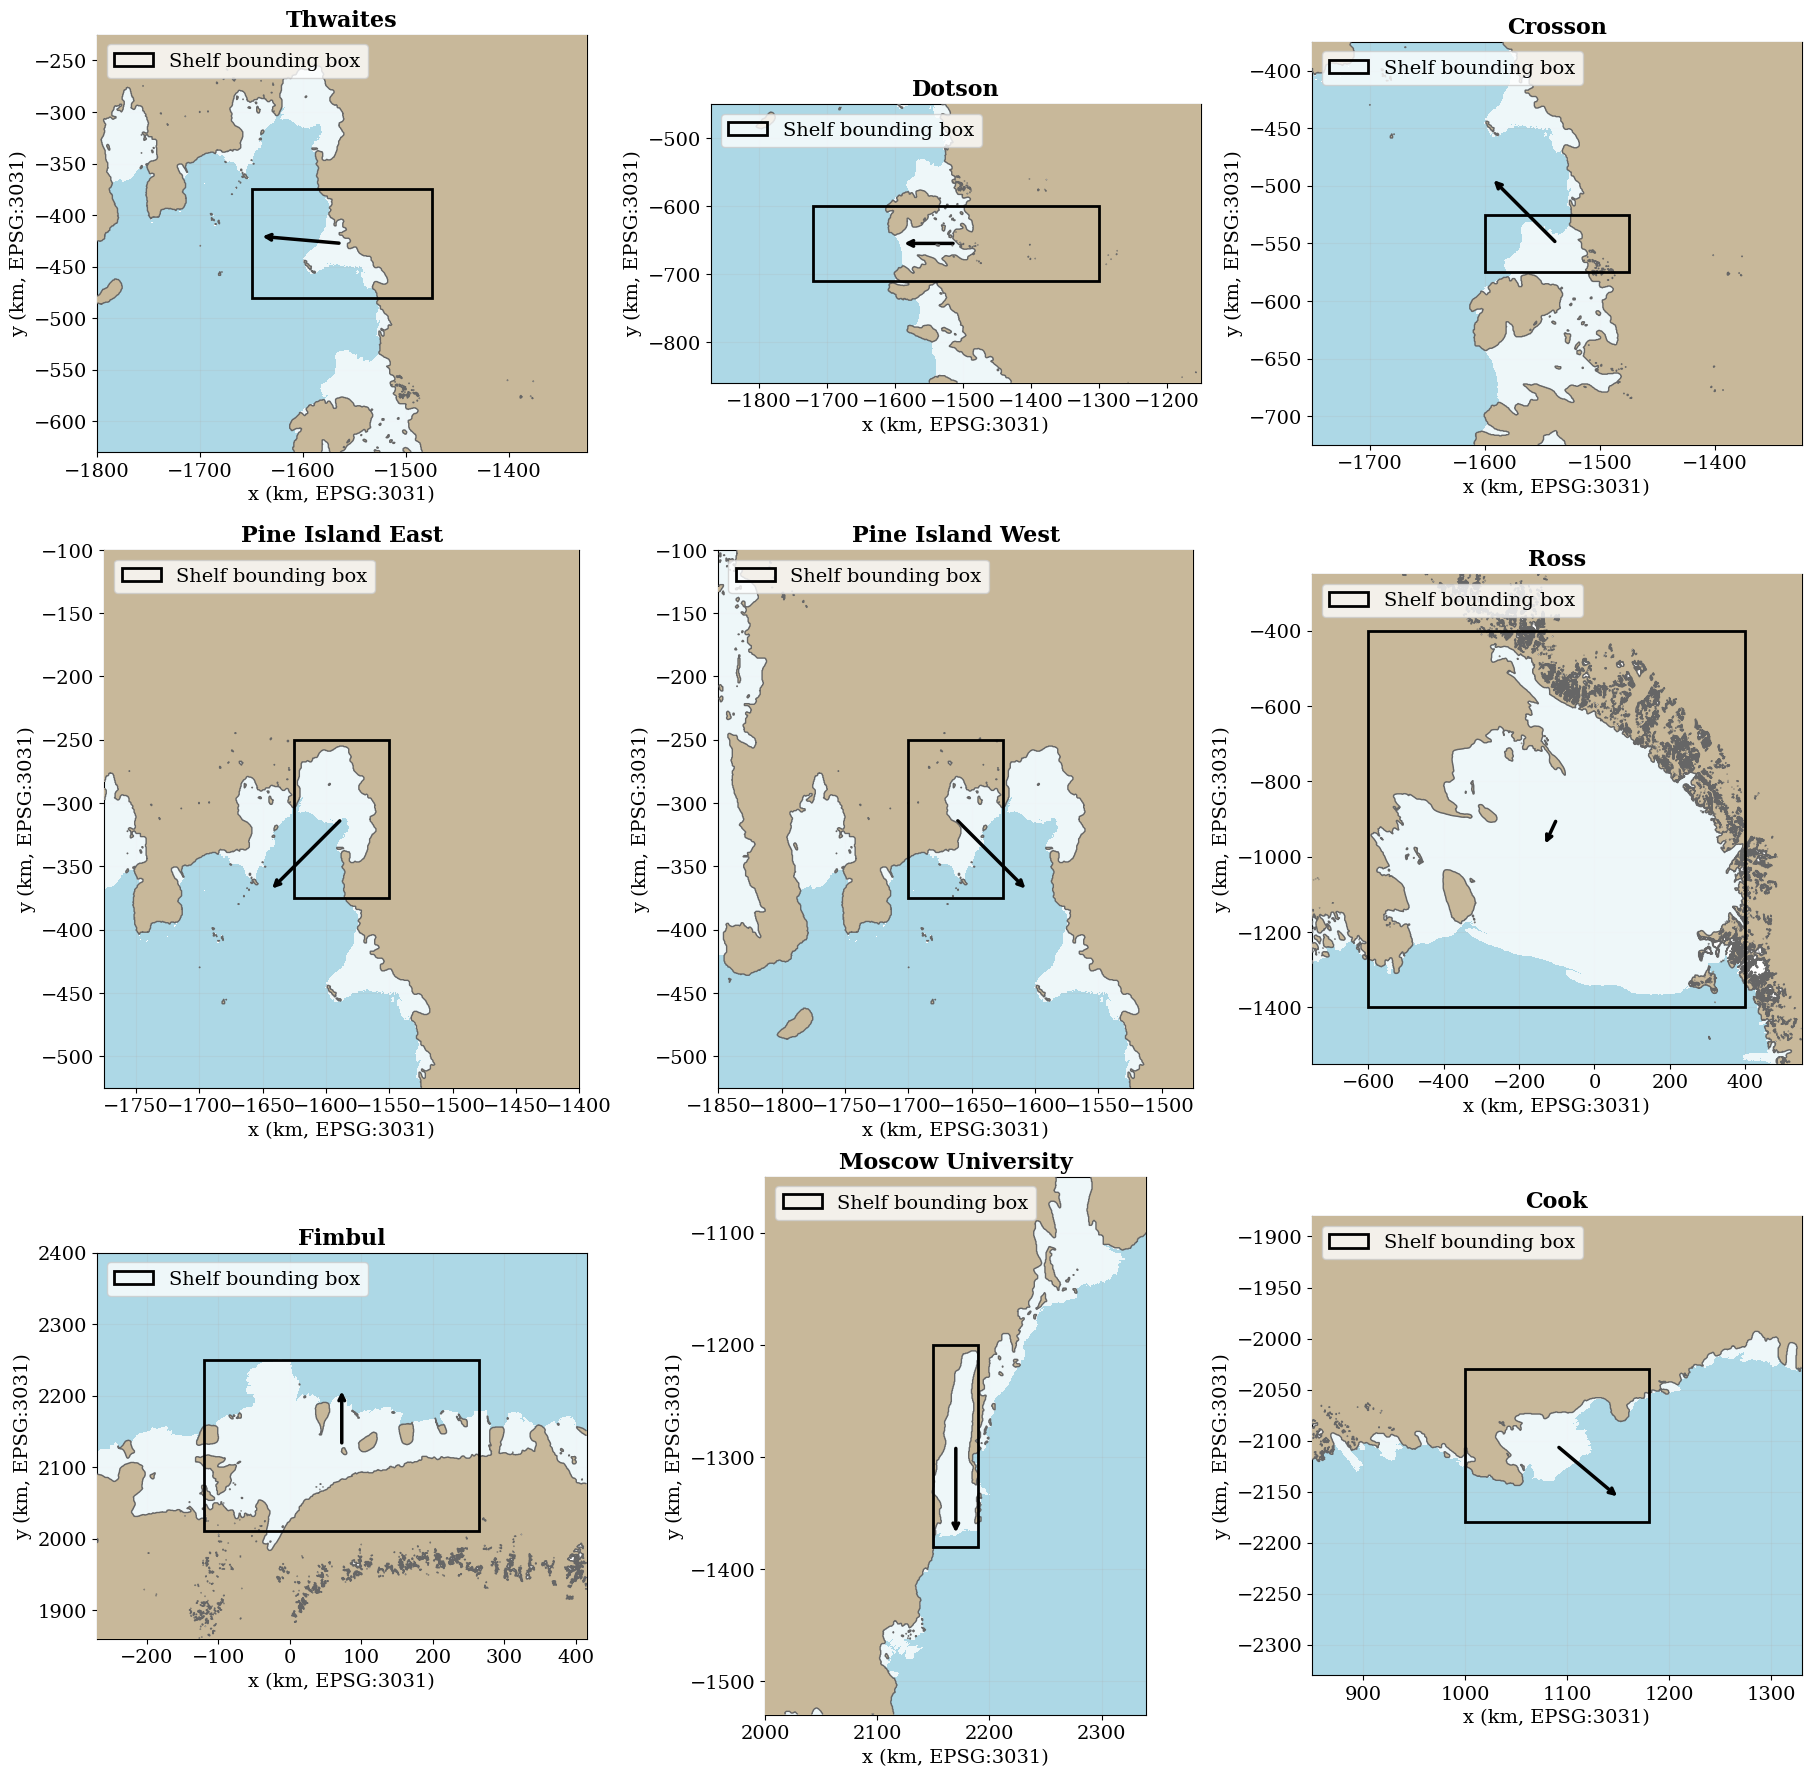

In [11]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
from scipy.ndimage import uniform_filter1d

# ── Plot bounding boxes on bed map for each shelf ─────────────────────────────
shelf_names = [n for n in shelves if n not in ('Totten', 'Holmes')]
ncols = 3
nrows = int(np.ceil(len(shelf_names) / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(18, 6 * nrows),
                         constrained_layout=True)
axes = axes.flatten()

for idx, name in enumerate(shelf_names):
    ax = axes[idx]
    config = shelves[name]
    xmin, xmax = config['x']
    ymin, ymax = config['y']
    ext_km = 100
    names_no_underscore = name.replace('_', ' ')
    display_name = display_names.get(name, names_no_underscore)
    # ── Zoom region─────────────────────────────────
    pad = 150e3
    x_lo = xmin - pad;  x_hi = xmax + pad
    y_lo = ymin - pad;  y_hi = ymax + pad

    xi_plot = np.where((x_all >= x_lo) & (x_all <= x_hi))[0]
    yi_plot = np.where((y_all >= y_lo) & (y_all <= y_hi))[0]

    bed_plot = bed_arr_full[np.ix_(yi_plot, xi_plot)]
    x_plot   = x_all[xi_plot] / 1e3
    y_plot   = y_all[yi_plot] / 1e3

    # ── Plot bed (ocean) ──────────────────────────────────────────────
    bed_masked = np.where(bed_plot < 0, bed_plot, np.nan)
    im = ax.pcolormesh(x_plot, y_plot, bed_masked,
                    
                cmap=plt.cm.colors.ListedColormap(['lightblue']), vmin=-2000, vmax=0,
                    shading='auto', zorder=1)

    # ── Ice shelf  ───────────────────────
    mask_plot = mask_arr_full[np.ix_(yi_plot, xi_plot)]
    ice_shelf = np.where((mask_plot == 3) | (mask_plot == 2), 1.0, np.nan)
    ax.pcolormesh(x_plot, y_plot, ice_shelf,
              cmap=plt.cm.colors.ListedColormap(['white']),
              shading='auto', alpha=0.8, zorder=2)

    # ── Land / grounded ice (mask == 1) ──────────────────────────────────────────
    grounded_mask = np.where(mask_plot == 1, 1.0, np.nan)
    ax.pcolormesh(x_plot, y_plot, grounded_mask,
                cmap=plt.cm.colors.ListedColormap(['#c8b89a']), vmin=0, vmax=1,
                shading='auto', zorder=3)

    # ── Coastline ─────────────────────────────────────────────────────────────────
    ax.contour(x_plot, y_plot, (mask_plot == 1).astype(float),
           levels=[0.5], colors='#666666', linewidths=1.0, zorder=4)
    # ── Shelf bounding box (cavity extraction) ────────────────────────────────
    rect_shelf = mpatches.Rectangle(
        (xmin/1e3, ymin/1e3), (xmax-xmin)/1e3, (ymax-ymin)/1e3,
        linewidth=2, edgecolor='black', facecolor='none',
        label='Shelf bounding box', zorder=5)
    ax.add_patch(rect_shelf)

    

    # ── Flow direction arrow ──────────────────────────────────────────────────
    cx = (xmin+xmax)/2e3;  cy = (ymin+ymax)/2e3
    if 'flow_angle_deg' in config:
        angle_rad = np.deg2rad(config['flow_angle_deg'])
        dx = np.cos(angle_rad)*80;  dy = np.sin(angle_rad)*80
    elif config['flow'] == 'x':
        dx = -80 if config['gl_side']=='max' else 80;  dy = 0
    else:
        dx = 0;  dy = -80 if config['gl_side']=='max' else 80
    ax.annotate('', xy=(cx+dx, cy+dy), xytext=(cx, cy),
                arrowprops=dict(arrowstyle='->', color='black', lw=2.5))

    ax.set_xlim(x_lo/1e3, x_hi/1e3)
    ax.set_ylim(y_lo/1e3, y_hi/1e3)
    ax.set_xlabel('x (km, EPSG:3031)', fontsize=14)
    ax.set_ylabel('y (km, EPSG:3031)', fontsize=14)
    ax.set_title(f'{display_name}', fontsize=16, fontweight='bold')
    ax.legend(fontsize=14, loc='upper left')
    ax.tick_params(axis='both', labelsize=14)
    ax.set_aspect('equal')
    ax.grid(True, alpha=0.2)
    

# Hide unused subplots
for idx in range(len(shelf_names), len(axes)):
    axes[idx].set_visible(False)

plt.savefig('shelf_bbox_map.png',  dpi=300)
plt.show()

TWIT could not be fully characterised using BedMachine v3 due to sparse daga. The profile shown represents only the upstream portion of the cavity. Therefore, Thwaites is combined into one shelf

In [12]:
# ── CDW Cavity Access Analysis ────────────────────────────────────────────────


print(f"\n{'═'*85}")
print(f"  CDW CAVITY ACCESS ANALYSIS")
print(f"  H_CDW = depth of seabed at front - CDW_top (positive = CDW can enter)")
print(f"{'═'*85}")
print(f"{'Shelf':<12} {'CDW top':>9} {'Bed@front':>10} {'H_CDW':>8} "
      f"{'Sill depth':>11} {'Access?':>9} {'Sill loc':>10}")
print(f"{'─'*85}")

cdw_results = {}
for name, res in results.items():
    if name in ('Totten', 'Holmes'):
        continue
    if name not in cdw_top_obs:
        print(f"  {name}: no CDW obs available, skipping")
        continue
    cdw_top = cdw_top_obs[name]

    # ── Ice base depth at the ice front ──────────────────────────────────────
    # ── H_CDW: seabed depth at front minus CDW top ────────────────────────────
    # Positive means CDW layer reaches the seabed at the front 
    z_bed_at_front = float(np.interp(res['d_front'], res['dist_bed'], res['z_bed']))
    bed_depth_at_front = -z_bed_at_front      # positive depth below surface

    H_CDW = bed_depth_at_front - cdw_top    

    # ── Sill: shallowest seabed point within the cavity ────────────
    cav_mask = (res['dist_bed'] >= res['d_cavity_start']) & \
               (res['dist_bed'] <= res['d_front'])
    
    if np.any(cav_mask):
        d_bed_cav  = res['dist_bed'][cav_mask]
        z_bed_cav  = res['z_bed'][cav_mask]
        sill_idx   = np.argmax(z_bed_cav)         
        sill_depth = -z_bed_cav[sill_idx]          # convert to positive depth
        sill_loc   = d_bed_cav[sill_idx]
    else:
        sill_depth = np.nan
        sill_loc   = np.nan

    cdw_enters_front = H_CDW > 0
    cdw_clears_sill  = cdw_top < sill_depth        # CDW shallower than sill crest
    cdw_accesses_gl  = cdw_enters_front and cdw_clears_sill

    access_str = ('✓ FULL'    if cdw_accesses_gl else
                  '~ PARTIAL' if cdw_enters_front else
                  '✗ BLOCKED')

    print(f"{name:<12} {cdw_top:>8.0f}m {bed_depth_at_front:>9.0f}m "
          f"{H_CDW:>+8.0f}m {sill_depth:>10.0f}m {access_str:>10} "
          f"{sill_loc:>9.0f}km")

    cdw_results[name] = dict(
        cdw_top=cdw_top,
        bed_depth_at_front=bed_depth_at_front,
        H_CDW=H_CDW,
        sill_depth=sill_depth,
        sill_loc=sill_loc,
        cdw_clears_sill=cdw_clears_sill,
        
    )

print(f"{'═'*85}")
print(f"\n  Note: H_CDW > 0 means CDW layer reaches below the ice base at the front.")
print(f"  CDW must also be shallower than the sill to access the grounding line.")



═════════════════════════════════════════════════════════════════════════════════════
  CDW CAVITY ACCESS ANALYSIS
  H_CDW = depth of seabed at front - CDW_top (positive = CDW can enter)
═════════════════════════════════════════════════════════════════════════════════════
Shelf          CDW top  Bed@front    H_CDW  Sill depth   Access?   Sill loc
─────────────────────────────────────────────────────────────────────────────────────
Thwaites          400m      1211m     +811m        602m     ✓ FULL        25km
Dotson            425m       491m      +66m        491m     ✓ FULL       125km
Crosson           425m       591m     +166m        507m     ✓ FULL        50km
PineIsland_East      300m       937m     +637m        636m     ✓ FULL        20km
PineIsland_West      300m       618m     +318m        420m     ✓ FULL        45km
Ross              100m       507m     +407m        490m     ✓ FULL       850km
Fimbul            345m      2302m    +1957m        385m     ✓ FULL        36km
Mosco


═══════════════════════════════════════════════════════════════════════════════════════════════
  CDW CAVITY ACCESS ANALYSIS
  H_CDW = sill_depth - CDW_top  (positive = CDW can clear sill → access cavity)
═══════════════════════════════════════════════════════════════════════════════════════════════
Shelf          CDW top  Sill depth   Sill loc    H_CDW    Sill type    Access?
───────────────────────────────────────────────────────────────────────────────────────────────
═══════════════════════════════════════════════════════════════════════════════════════════════

  H_CDW > 0 → CDW layer (top at CDW_top) is shallower than sill crest → can pass.
  Entrance sill: shallowest bed between WOA23 point and ice front.
  Internal sill: shallowest bed between GL and ice front (Getz only).


/var/folders/dp/bxjb_th907g0tlby49jsjkhr0000gn/T/ipykernel_45175/2005564576.py:185: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) DejaVu Serif.
  plt.savefig('cdw_access_profiles.png', dpi=150, bbox_inches='tight')
/Users/helensoane/miniforge3/envs/CDA/lib/python3.14/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) DejaVu Serif.
  fig.canvas.print_figure(bytes_io, **kw)


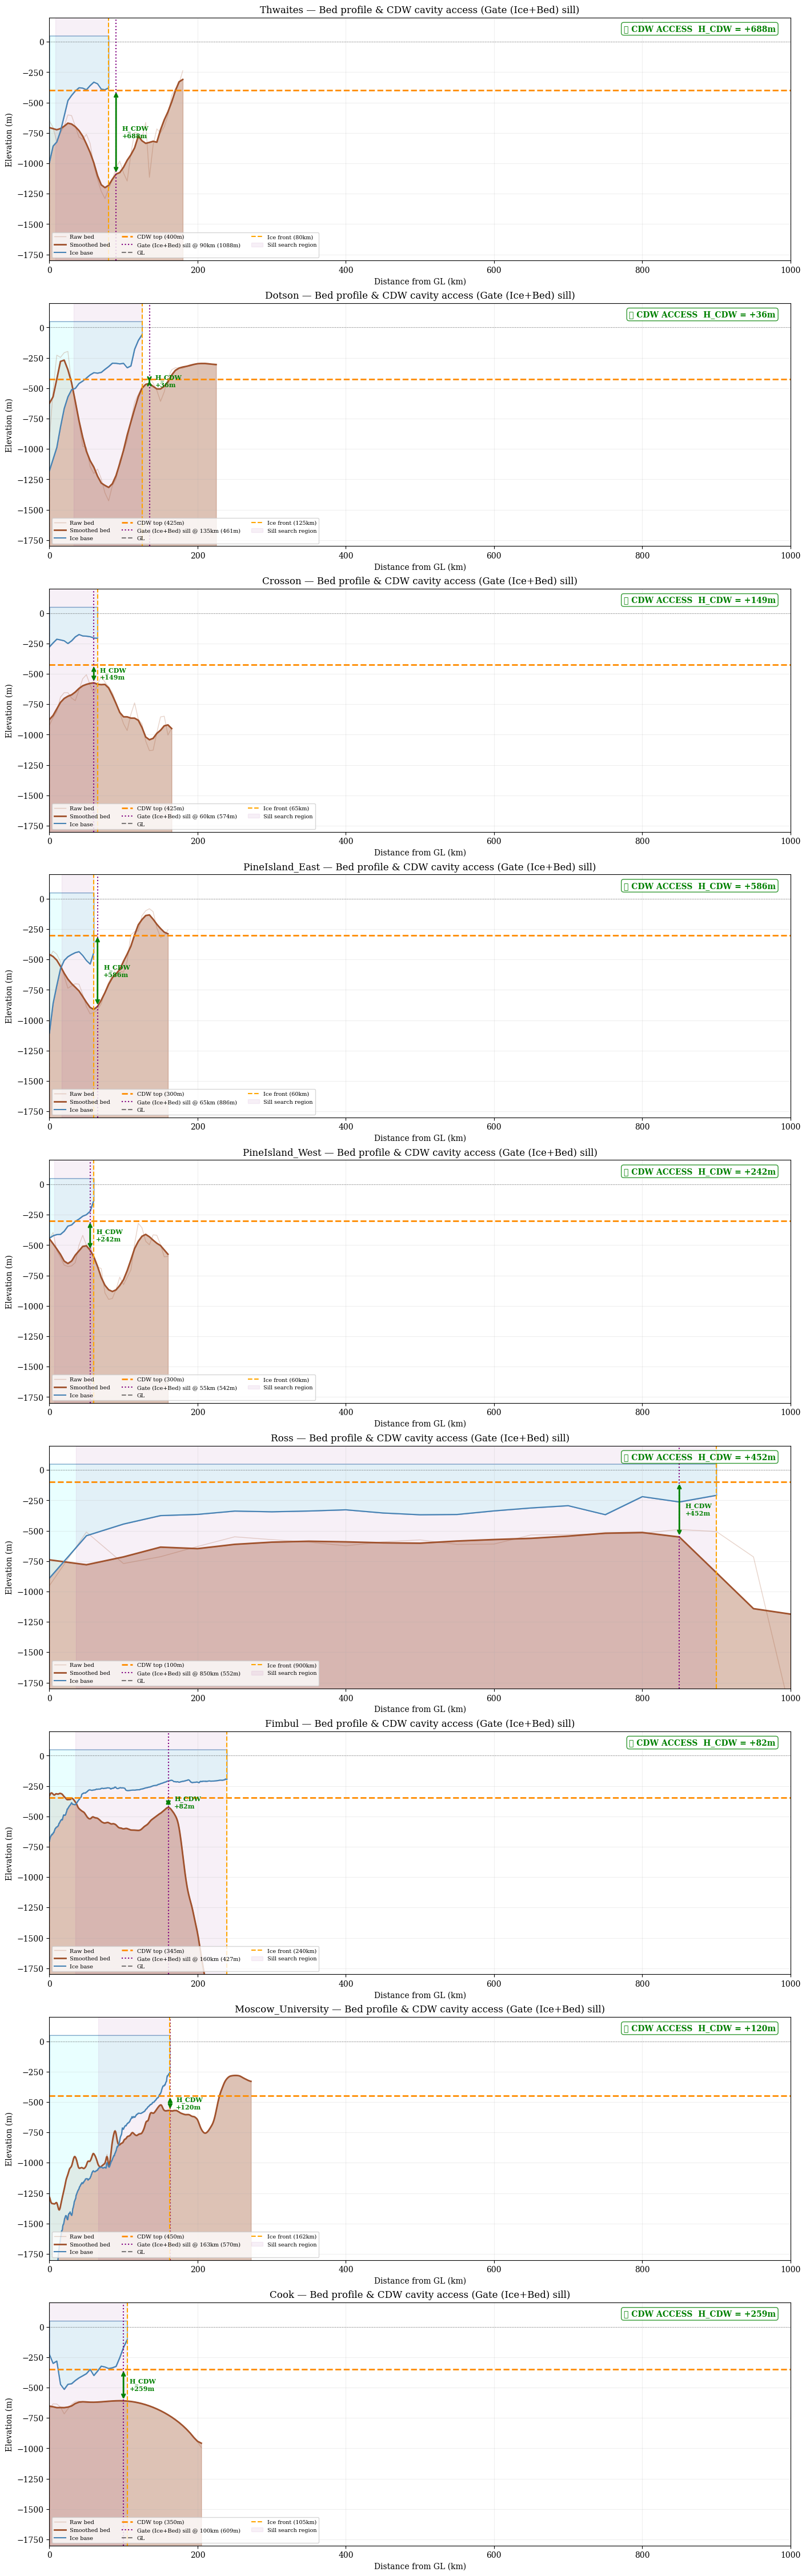

In [13]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from scipy.ndimage import uniform_filter1d


#'Thwaites':     {'region': 'entrance', 'search_km': 50},'Thwaites_TWIT':     {'region': 'entrance', 'search_km': 50},
# ── Sill definitions ─────────────────────────────────────────────────────
sill_config = {
    
    'Thwaites':     {'region': 'entrance', 'search_km': 50},
    'Ross':              {'region': 'full_cavity'},
    'Dotson':            {'region': 'entrance', 'search_km': 50},
    'Fimbul':            {'region': 'full_cavity'},
    'Getz':              {'region': 'entrance', 'search_km': 50},
    'PineIsland_East':        {'region': 'entrance', 'search_km': 50},
    'PineIsland_West':        {'region': 'entrance', 'search_km': 50},
    'Crosson':           {'region': 'entrance', 'search_km': 50},
    'Moscow_University': {'region': 'entrance', 'search_km': 50},
    'Cook':              {'region': 'entrance', 'search_km': 50},
}

# ── Smoothing window (grid cells) for bed profile ────────────────────────────
SMOOTH_SIZE = 5

# ── Run analysis ──────────────────────────────────────────────────────────────
cdw_results = {}

print(f"\n{'═'*95}")
print(f"  CDW CAVITY ACCESS ANALYSIS")
print(f"  H_CDW = sill_depth - CDW_top  (positive = CDW can clear sill → access cavity)")
print(f"{'═'*95}")
print(f"{'Shelf':<12} {'CDW top':>9} {'Sill depth':>11} {'Sill loc':>10} "
      f"{'H_CDW':>8} {'Sill type':>12} {'Access?':>10}")
print(f"{'─'*95}")

# ── Run analysis with updated Gate Logic ──────────────────────────────────────
cdw_results = {}

for name, res in results.items():
    if name in ('Totten', 'Holmes'): continue
    if name not in cdw_top_obs: continue
    
    cdw_top = cdw_top_obs[name]        
    z_bed_smooth = uniform_filter1d(res['z_bed'], size=SMOOTH_SIZE)
    cfg = sill_config[name]

    # 1. Get Ice Depth at the Front
    # We interpolate to find the exact Z of the ice at the d_front distance
    z_ice_at_front = float(np.interp(res['d_front'], res['dist_ice'], res['z_ice']))
    ice_depth_at_front = -z_ice_at_front # Convert to positive depth

    # 2. Get Sill Depth (Bed)
    if name == 'Ross':
        d_min, d_max = res['d_front'] - 80, res['d_front']
    
    elif name == 'Fimbul':
        d_min, d_max = res['d_front'] - 125, res['d_front']
    elif name == 'PineIsland_East':
        d_min, d_max = res['d_front']-5, res['d_front']+5
    else:
        d_min, d_max = res['d_front'] - 5, res['d_front'] + 10

    sill_mask = (res['dist_bed'] >= d_min) & (res['dist_bed'] <= d_max)

    if np.any(sill_mask):
        z_sill = z_bed_smooth[sill_mask]
        d_sill = res['dist_bed'][sill_mask]
        sill_idx = np.argmax(z_sill) # Shallowest bed
        sill_depth = -z_sill[sill_idx]
        sill_loc = d_sill[sill_idx]
    else:
        sill_depth = ice_depth_at_front # Fallback to ice if no bed data
        sill_loc = res['d_front']

    # 3. ENFORCE GATE LOGIC: 
    cdw_entry_gap = max(cdw_top, ice_depth_at_front)
    # H_CDW is the thickness of the CDW layer that fits through the gate
    H_CDW = sill_depth - cdw_top
    
    cdw_accesses = H_CDW > 0
    access_str = '✓ ACCESS' if cdw_accesses else '✗ BLOCKED'
    sill_type = 'Gate (Ice+Bed)'


    cdw_results[name] = dict(
        cdw_top        = cdw_top,
        sill_depth     = sill_depth,
        sill_loc       = sill_loc,
        H_CDW          = H_CDW,
        sill_type      = sill_type,
        cdw_accesses   = cdw_accesses,
        z_bed_smooth   = z_bed_smooth,
        ice_depth_at_front = ice_depth_at_front,
        
    )

print(f"{'═'*95}")
print(f"\n  H_CDW > 0 → CDW layer (top at CDW_top) is shallower than sill crest → can pass.")
print(f"  Entrance sill: shallowest bed between WOA23 point and ice front.")
print(f"  Internal sill: shallowest bed between GL and ice front (Getz only).")

# ── Plot ──────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(len(results), 1,
                         figsize=(14, 5 * len(results)),
                         constrained_layout=True)

if len(results) == 1:
    axes = [axes]

for ax, (name, res) in zip(axes, results.items()):
    if name in ('Totten', 'Holmes'):
        ax.set_visible(False)
        continue
    cr           = cdw_results[name]
    z_bed_smooth = cr['z_bed_smooth']

    # ── Bed ───────────────────────────────────────────────────────────────────
    ax.plot(res['dist_bed'], res['z_bed'],
            color='sienna', alpha=0.25, lw=1, label='Raw bed')
    ax.plot(res['dist_bed'], z_bed_smooth,
            color='sienna', lw=2, label='Smoothed bed')
    ax.fill_between(res['dist_bed'], z_bed_smooth, -2000,
                    color='sienna', alpha=0.35)

    # ── Ice base ──────────────────────────────────────────────────────────────
    ax.plot(res['dist_ice'], res['z_ice'],
            color='steelblue', lw=1.5, label='Ice base')
    ax.fill_between(res['dist_ice'], res['z_ice'], 50,
                    color='lightcyan', alpha=0.7, edgecolor='steelblue', lw=1)

    # ── CDW top ───────────────────────────────────────────────────────────────
    ax.axhline(-cr['cdw_top'], color='darkorange', lw=2, ls='--',
               label=f'CDW top ({cr["cdw_top"]}m)')

    # ── Sill ──────────────────────────────────────────────────────────────────
    if not np.isnan(cr['sill_loc']):
        ax.axvline(cr['sill_loc'], color='purple', lw=1.5, ls=':',
                   label=f'{cr["sill_type"]} sill @ {cr["sill_loc"]:.0f}km '
                         f'({cr["sill_depth"]:.0f}m)')

        # Double-headed H_CDW arrow at sill location
        ax.annotate('', xy=(cr['sill_loc'], -cr['cdw_top']),
                    xytext=(cr['sill_loc'], -cr['sill_depth']),
                    arrowprops=dict(arrowstyle='<->', color='green', lw=2))
        ax.text(cr['sill_loc'] + 8,
                (-cr['cdw_top'] - cr['sill_depth']) / 2,
                f"H_CDW\n{cr['H_CDW']:+.0f}m",
                fontsize=8, color='green', fontweight='bold', va='center')

    # ── Reference lines ───────────────────────────────────────────────────────
    ax.axvline(0, color='black', lw=1.5, ls='--', alpha=0.5, label='GL')
    ax.axvline(res['d_front'], color='orange', lw=1.5, ls='--',
               label=f'Ice front ({res["d_front"]:.0f}km)')
    ax.axhline(0, color='k', lw=0.8, ls=':', alpha=0.5)

    # ── Shade sill search region ──────────────────────────────────────────────
    if cr['sill_type'] == 'Entrance':
        search_km = sill_config[name].get('search_km', 20)
        ax.axvspan(res['d_front'], res['d_front'] + search_km,
                color='purple', alpha=0.06, label='Sill search region')
    else:
        ax.axvspan(res['d_cavity_start'], res['d_front'],
                   color='purple', alpha=0.06, label='Sill search region')

    # ── Access label ──────────────────────────────────────────────────────────
    access_color = 'green' if cr['cdw_accesses'] else 'red'
    access_text  = f"{'✓ CDW ACCESS' if cr['cdw_accesses'] else '✗ CDW BLOCKED'}  "  \
                   f"H_CDW = {cr['H_CDW']:+.0f}m"
    ax.text(0.98, 0.97, access_text,
            transform=ax.transAxes, fontsize=10, fontweight='bold',
            color=access_color, ha='right', va='top',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white',
                      edgecolor=access_color, alpha=0.8))

    ax.set_xlim(0, max(res['dist_bed'].max(), 1000))
    ax.set_ylim(-1800, 200)
    ax.set_xlabel('Distance from GL (km)', fontsize=10)
    ax.set_ylabel('Elevation (m)', fontsize=10)
    ax.set_title(f'{name} — Bed profile & CDW cavity access '
                 f'({cr["sill_type"]} sill)', fontsize=12)
    ax.legend(fontsize=7, loc='lower left', ncol=3)
    ax.grid(True, alpha=0.2)

plt.savefig('cdw_access_profiles.png', dpi=150, bbox_inches='tight')
plt.show()

doesnt work for dotson as it has two large troughs so actually more water can get in

In [14]:
for name, cr in cdw_results.items():
    if cr['cdw_accesses']:
        numerator = cr['sill_depth'] - cr['ice_depth_at_front']
        beta_raw = numerator / cr['H_CDW'] - 1
        print(f"{name}: sill={cr['sill_depth']:.1f}, ice_front={cr['ice_depth_at_front']:.1f}, "
              f"H_CDW={cr['H_CDW']:.1f}, numerator={numerator:.1f}, "
              f"beta_raw={beta_raw:.3f}, beta_clipped={max(0, beta_raw):.3f}")

Thwaites: sill=1088.5, ice_front=378.1, H_CDW=688.5, numerator=710.4, beta_raw=0.032, beta_clipped=0.032
Dotson: sill=461.3, ice_front=59.5, H_CDW=36.3, numerator=401.9, beta_raw=10.064, beta_clipped=10.064
Crosson: sill=573.7, ice_front=207.6, H_CDW=148.7, numerator=366.1, beta_raw=1.462, beta_clipped=1.462
PineIsland_East: sill=886.2, ice_front=440.3, H_CDW=586.2, numerator=445.8, beta_raw=-0.239, beta_clipped=0.000
PineIsland_West: sill=541.7, ice_front=131.7, H_CDW=241.7, numerator=410.0, beta_raw=0.696, beta_clipped=0.696
Ross: sill=551.5, ice_front=208.6, H_CDW=451.5, numerator=342.9, beta_raw=-0.241, beta_clipped=0.000
Fimbul: sill=427.0, ice_front=195.1, H_CDW=82.0, numerator=232.0, beta_raw=1.828, beta_clipped=1.828
Moscow_University: sill=569.9, ice_front=256.6, H_CDW=119.9, numerator=313.3, beta_raw=1.613, beta_clipped=1.613
Cook: sill=608.7, ice_front=104.8, H_CDW=258.7, numerator=503.9, beta_raw=0.948, beta_clipped=0.948


In [15]:
for name, cr in cdw_results.items():
    beta=(cr['sill_depth']-cr['ice_depth_at_front'])/cr['H_CDW'] -1 if cr['cdw_accesses'] else np.nan

    if beta<0:
        beta = 0.0
    else:
        beta = beta
    if beta == 0.0:
        cr['H_CDW'] = cr['sill_depth']-cr['ice_depth_at_front']

        print(f"{name}: H_CDW = {cr['H_CDW']:+.0f}m"
          f"β = {beta:.2f}" if cr['cdw_accesses'] else "CDW blocked, no β")
        continue
    print(f"{name}: H_CDW = {cr['H_CDW']:+.0f}m, "
          f"β = {beta:.2f}" if cr['cdw_accesses'] else "CDW blocked, no β")

Thwaites: H_CDW = +688m, β = 0.03
Dotson: H_CDW = +36m, β = 10.06
Crosson: H_CDW = +149m, β = 1.46
PineIsland_East: H_CDW = +446mβ = 0.00
PineIsland_West: H_CDW = +242m, β = 0.70
Ross: H_CDW = +343mβ = 0.00
Fimbul: H_CDW = +82m, β = 1.83
Moscow_University: H_CDW = +120m, β = 1.61
Cook: H_CDW = +259m, β = 0.95


In [16]:
melt_parameters = {
    "Thwaites": {"A": 3352,   "T2": 1, "HCDW": 688, "obs_m": 26.7, "obs_err": 2.4},
    
    "Ross":     {"A": 358068, "T2": -0.44,  "HCDW": 343,  "obs_m": 0.4,  "obs_err": 0.3},
    "Dotson":   {"A": 5657,   "T2": 0.67,  "HCDW": 36, "obs_m": 5.4,  "obs_err": 1.6},
    "Fimbul":   {"A": 40600,  "T2": 0.61, "HCDW": 82,   "obs_m": 1.0,  "obs_err": 0.8},
    "PineIsland_East":   {"A": 5950/2,  "T2": 1.16, "HCDW": 446,   "obs_m": 14.0,  "obs_err": 1.6},

    "PineIsland_West":   {"A": 5950/2,  "T2": 1.16, "HCDW": 242,   "obs_m": 14.0,  "obs_err": 1.6},
    "Crosson":   {"A": 2932,  "T2": 0.67, "HCDW": 149,   "obs_m": 7.8,  "obs_err": 1.8},
    "Moscow_University":   {"A": 4145,  "T2": 0.25, "HCDW": 120,   "obs_m": 7.4,  "obs_err": 2.1},
    "Cook":   {"A": 3408,  "T2": 0.06, "HCDW": 259,   "obs_m": 1.3,  "obs_err": 1.6},}

#"Thwaites": {"A": 3352/2,   "T2": 1, "HCDW": 651, "obs_m": 26.7, "obs_err": 2.4}, "Thwaites_TWIT": {"A": 3352/2,   "T2": 1, "HCDW": 322, "obs_m": 26.7, "obs_err": 2.4},
cdw_mean_obs={
  
  
  'Thwaites':1,
  'Ross':0,
  'Dotson': 0.67,
  'Fimbul': 0.61,
  'PineIsland_East': 1.16,
  'PineIsland_West': 1.16,
  'Crosson': 0.67,
  'Moscow_University': 0.25,
  'Cook': 0.06 #from the CDW data, Cook seems to be cooler...
  ,}

In [17]:

y_f_dict = {}

for name, res in results.items():
    if name in ('Totten', 'Holmes'):
        continue
    y_f_dict[name] = res['d_front']   # km


# H' = mean cavity thickness = bed depth - ice base
# (positive thickness)


H_prime_dict = {}
for name, res in results.items():
    if name in ('Totten', 'Holmes'):
        continue
    
    cavity_mask = (res['dist_ice'] >= 0) & (res['dist_ice'] <= res['d_front'])
    dist_cavity = res['dist_ice'][cavity_mask]   # km
    z_ice_cavity = res['z_ice'][cavity_mask]     # m elevation
    
    dz = z_ice_cavity[-1] - z_ice_cavity[0]     # metres
    dy = (dist_cavity[-1] - dist_cavity[0]) * 1e3  # km → m
    
    H_prime_dict[name] = dz / dy   # m/m (dimensionless slope)

print(H_prime_dict)

{'Thwaites': np.float64(0.007702642706131078), 'Dotson': np.float64(0.00896178775510204), 'Crosson': np.float64(0.0010839645846015273), 'PineIsland_East': np.float64(0.011091675463288764), 'PineIsland_West': np.float64(0.005194601086048454), 'Ross': np.float64(0.0007571763422800615), 'Fimbul': np.float64(0.0021250521920668057), 'Moscow_University': np.float64(0.010724979020979021), 'Cook': np.float64(0.001155873015873016)}


In [18]:

# Merge PineIsland East + West: compute Pi separately, then average

pi1_key = "PineIsland_East"
pi2_key = "PineIsland_West"

Tf = -1.9
g = 9.8
rho_1 = 1027.55
rho_2 = 1027.75
rho_i = 917
Lf = 3.34e5
f = 1e-4
C_p = 3974   

sec_per_year = 60*60*24*365

if pi1_key in melt_parameters and pi2_key in melt_parameters:
    pi1 = melt_parameters[pi1_key]
    pi2 = melt_parameters[pi2_key]
    A1_pi, A2_pi = pi1["A"], pi2["A"]
    Atot_pi = A1_pi + A2_pi

    def compute_B_single(params, H_prime, yf_val):
        W_val  = (params["A"] * 1e6) / (yf_val * 1e3)          # m
        K_val  = (C_p * (params["T2"] - Tf)
                  * g * (rho_2 - rho_1) * rho_2
                  / (rho_i * Lf * f * rho_1))
        return abs(K_val * H_prime * params["HCDW"] / W_val *sec_per_year)

    H1_pi  = H_prime_dict.get(pi1_key, np.nan)
    print(H1_pi)
    H2_pi  = H_prime_dict.get(pi2_key, np.nan)
    yf1_pi = y_f_dict.get(pi1_key, np.nan)
    yf2_pi = y_f_dict.get(pi2_key, np.nan)

    B1_pi = compute_B_single(pi1, H1_pi, yf1_pi)
    B2_pi = compute_B_single(pi2, H2_pi, yf2_pi)

    # Area-weighted average of B 
    B_pi_comb = (A1_pi * B1_pi + A2_pi * B2_pi) / Atot_pi

    # Observed melt and error
    mobs_pi_comb = (A1_pi * pi1["obs_m"]   + A2_pi * pi2["obs_m"])   / Atot_pi
    err_pi_comb  = (A1_pi * pi1["obs_err"] + A2_pi * pi2["obs_err"]) / Atot_pi

    print(f"  B_East={B1_pi:.4f}, B_West={B2_pi:.4f}, B_combined={B_pi_comb:.4f}")

    for k in [pi1_key, pi2_key]:
        melt_parameters.pop(k, None)
        H_prime_dict.pop(k, None)
        y_f_dict.pop(k, None)

    melt_parameters["PineIsland"] = {
        "A":       Atot_pi,
        "T2":      np.nan,   
        "HCDW":    np.nan,
        "obs_m":   mobs_pi_comb,
        "obs_err": err_pi_comb,
        "_B_precomputed": B_pi_comb,   
    }
    
    H_prime_dict["PineIsland"] = np.nan
    y_f_dict["PineIsland"]     = np.nan

    print(f"PineIsland merged (Pi-first): A={Atot_pi:.0f} km², "
          f"obs_m={mobs_pi_comb:.1f} m/yr, B={B_pi_comb:.4f}")

0.011091675463288764
  B_East=2448.9334, B_West=622.3182, B_combined=1535.6258
PineIsland merged (Pi-first): A=5950 km², obs_m=14.0 m/yr, B=1535.6258


In [19]:
fs = {
    'Thwaites': 20,
    'Moscow_University': 6.5,
    'PineIsland': 9.5,
    'Dotson':8,
    'Crosson': 12,
    'Ross': 2,
    'Fimbul': 2.2
}

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def average_melt(y_max, W, area, T2, D,  H_f, l, beta):
    """Calculate average melt rate in m/year"""
    Tf = -1.9
    g = 9.8
    rho_1 = 1027.55
    rho_2 = 1027.75
    rho_i = 917
    L = 3.34e5
    f = 1e-4
    alpha = 0.094
    
    C_p = 3993 
    k = alpha*(T2-Tf)*g*(rho_2-rho_1)*C_p/(rho_i*L*f*(beta+1))
    H_max = D-(D-H_f)*(1-np.exp(-y_max/l))
    M_max = (H_max * (D - 0.5 * H_max) - 0.5 * D**2) * k  # m/s
    M_max_year = -M_max * (60 * 60 * 24 * 365)*917/10**12  # Gt/year
    average_M = M_max_year   # average over shelf area
    m_avg = average_M*10**12/917/area/10**6
    return average_M, m_avg

In [21]:
def compute_m_bedmap(coeffs, H_f, delta_H, y_start, y_f, A, T2, l, beta):
    """
    Generalisation of average_melt to non-flat seabed.
    
    H(y) = H_f + delta_H * exp(-y/l)   [ice base, GL-relative, metres, negative = below sea level]
    p2(y) = polyval(coeffs, y-y_start)  [seabed, metres, negative]
    water_column(y) = H(y) - p2(y)      [positive when cavity open]
    
    Integrand = water_column * |dH/dy|
    """
    from scipy.integrate import quad
    
    Tf    = -1.9
    g     = 9.8
    rho_1 = 1027.55
    rho_2 = 1027.75
    rho_i = 917
    L     = 3.34e5
    f     = 1e-4
    alpha = 0.094        
    C_p   = 3974          

    k = alpha * (T2 - Tf) * g * (rho_2 - rho_1) * C_p / (rho_i * L * f * (beta + 1))

    # ── Ice base and its derivative (GL-relative coords, km) ─────────────────
    def H(y):        return H_f + delta_H * np.exp(-y / l)
    def dHdy(y):     return -(delta_H / l) * np.exp(-y / l)   # m/km
    def p2(y):       return np.polyval(coeffs, y - y_start)    # seabed in m
    print(f"{H(y_start)=:.2f}, {p2(y_start)=:.2f}, {H(y_f)=:.2f}, {p2(y_f)=:.2f}")
    print(np.polyval(coeffs, 0))                  # bed at cavity start
    print(H(y_start))

    print(np.polyval(coeffs, y_f - y_start))      # bed at front
    print(H(y_f))
    from scipy.optimize import minimize_scalar

    def integrand(y):
        wc    = H(y) - p2(y)       # water column (m)
        slope = abs(dHdy(y))       # |dH/dy| (m/km)
        return max(wc, 0.0) * slope

    def m_local(y):
        max_m = max(np.abs(dHdy(y)*(H(y) - p2(y))), 0.0)/1000
                  
        seconds_per_yr = 60 * 60 * 24 * 365
        return k * max_m * seconds_per_yr
    
    res = minimize_scalar(
    lambda y: -m_local(y),
    bounds=(y_start, y_f),
    method="bounded"
    )

    loc_max = res.x - y_start
    m_max = m_local(res.x)/A*(y_f-y_start)/1000


    integral_m2_per_km, _ = quad(integrand, y_start, y_f)

    A_m2          = A * 1e6                    # km² → m²
    seconds_per_yr = 60 * 60 * 24 * 365

    M_gt_per_yr   = integral_m2_per_km * k * seconds_per_yr * rho_i / 1e12
    m_avg_per_yr  = M_gt_per_yr * 1e12 / rho_i / A_m2

    return M_gt_per_yr, m_avg_per_yr, m_max, loc_max


from scipy.integrate import quad

# ── Now run with actual Bedmap3 seabed ────────────────────────────────
print(f"\n{'─'*60}")
print("  MELT RATES WITH BEDMAP3 SEABED")
print(f"{'─'*60}")

# "Thwaites": {"A": 3352/2,   "T2": 1, "beta": 0.02, "obs_m": 26.7, "obs_err": 2.4}, "Thwaites_TWIT": {"A": 3352/2,   "T2": 1, "beta": 0.0, "obs_m": 26.7, "obs_err": 2.4},
melt_parameters = {

    "Thwaites": {"A": 3352,   "T2": 1, "beta": 0.03, "obs_m": 26.7, "obs_err": 2.4},

    "Ross":     {"A": 358068, "T2": -0.44,  "beta": 0.00,  "obs_m": 0.4,  "obs_err": 0.3},
    "Dotson":   {"A": 5657,   "T2": 0.67,  "beta": 10.06, "obs_m": 5.4,  "obs_err": 1.6},
    "Fimbul":   {"A": 40600,  "T2": 0.63, "beta": 1.83,   "obs_m": 1.0,  "obs_err": 0.8},
    "PineIsland_East":   {"A": 5950/2,  "T2": 1.16, "beta": 0,   "obs_m": 14.0,  "obs_err": 1.6},

    "PineIsland_West":   {"A": 5950/2,  "T2": 1.16, "beta": 0.70,   "obs_m": 14.0,  "obs_err": 1.6},
    "Crosson":   {"A": 2932,  "T2": 0.67, "beta": 1.46,   "obs_m": 7.8,  "obs_err": 1.8},
    "Moscow_University":   {"A": 4145,  "T2": 0.25, "beta": 3.48,   "obs_m": 7.4,  "obs_err": 2.1},
    "Cook":   {"A": 3408,  "T2": 0.03, "beta": 0.95,   "obs_m": 1.3,  "obs_err": 1.6},}


cdw_mean_obs={
  
  
  'Thwaites':1,
  'Ross':0,
  'Dotson': 0.67,
  'Fimbul': 0.61,
  'PineIsland_East': 1.16,
  'PineIsland_West': 1.16,
  'Crosson': 0.67,
  'Moscow_University': 0.25,
  'Cook': 0.06 #from the CDW data, Cook seems to be cooler...
  ,}
for name, res in results.items():
    if name not in melt_parameters:
        continue
    y_start = res['d_cavity_start']
    y_f     = res['d_front']
    coeffs  = res['best_coeffs']
    cavity_length = y_f - y_start
    
    # Average |dH/dy| (analytical)
    delta_H = res['delta_H']
    l = res['l']
    avg_Hprime = delta_H * (np.exp(-y_start/l) - np.exp(-y_f/l)) / cavity_length
    res['avg_Hprime'] = avg_Hprime
    
    # Average |dD/dy| 
    deriv_coeffs = np.polyder(coeffs)  # derivative of quadratic is linear
    def dDdy(y):
        return abs(np.polyval(deriv_coeffs, y - y_start))
    avg_Dprime, _ = quad(dDdy, y_start, y_f)
    avg_Dprime /= cavity_length
    res['avg_Dprime'] = avg_Dprime
    avg_water_prime = -avg_Hprime + avg_Dprime
    
    res['avg_water_prime'] = avg_water_prime
    def water_column(y):
        H = res['H_f'] + res['delta_H'] * np.exp(-y / l)
        D = np.polyval(coeffs, y - y_start)
        return max(H - D, 0.0)

    avg_wc, _ = quad(water_column, y_start, y_f)
    avg_wc /= cavity_length
    res['avg_wc'] = avg_wc
    # Second derivative of the seabed polynomial
    second_deriv_coeffs = np.polyder(coeffs, 2)  # differentiate twice

    def d2Ddy2(y):
        return abs(np.polyval(second_deriv_coeffs, y - y_start))

    avg_D_double_prime, _ = quad(d2Ddy2, y_start, y_f)
    avg_D_double_prime /= cavity_length
    res['avg_D_double_prime'] = avg_D_double_prime
    # Cavity length
    res['cavity_length'] = y_f - y_start

    # Ice draft at grounding line (most negative = deepest)
    res['H_at_GL'] = res['H_f'] + res['delta_H']  # H(y_start≈0)

    # Ice draft at front
    res['H_at_front'] = res['H_f'] + res['delta_H'] * np.exp(-y_f / res['l'])

    # Draft range across cavity
    res['delta_draft'] = res['H_at_GL'] - res['H_at_front']

    # Seabed depth at grounding line (polyval at y=y_start → offset=0)
    res['D_at_GL'] = np.polyval(coeffs, 0)

    # Seabed depth at front
    res['D_at_front'] = np.polyval(coeffs, y_f - y_start)

    # Seabed slope (linear, negative = deepening toward GL)
    res['seabed_slope'] = (res['D_at_GL'] - res['D_at_front']) / cavity_length

    # Water column at grounding line
    res['wc_at_GL'] = res['H_at_GL'] - res['D_at_GL']

    params = melt_parameters[name]

    # Use l from Bedmap3 fit (already in km)
    # delta_H and H_f from exponential fit to full profile
    M_calc, m_calc, m_max, loc_max = compute_m_bedmap(
        coeffs  = res['best_coeffs'],
        H_f     = res['H_f'],
        delta_H = res['delta_H'],
        y_start = res['d_cavity_start'],
        y_f     = res['d_front'],
        A       = params['A'],
        T2      = params['T2'],
        l       = res['l'],
        beta    = params['beta'],
    )
    res['m_calc'] = m_calc
    res['M_calc'] = M_calc
    res['m_max'] = m_max
    res['loc_max'] = loc_max

    print(f"\n{name}:")
    print(f"  H_f={res['H_f']:.1f}m, delta_H={res['delta_H']:.1f}m, l={res['l']:.1f}km")
    print(f"  Slope at cavity start: {abs(res['delta_H'])/res['l']*np.exp(-res['d_cavity_start']/res['l']):.2f} m/km")
    print(f"  M_calc={M_calc:.3f} Gt/yr,  m_calc={m_calc:.3f} m/yr")
    print(f"   m_obs ={params['obs_m']:.1f} m/yr")
    print(f"   m_max ={m_max:.3f} m/yr at y={loc_max:.1f} km")
    print(f" {y_f} km from grounding line to ice front, cavity length={res['cavity_length']:.1f} km")


────────────────────────────────────────────────────────────
  MELT RATES WITH BEDMAP3 SEABED
────────────────────────────────────────────────────────────
H(y_start)=-786.19, p2(y_start)=-741.35, H(y_f)=-342.19, p2(y_f)=-1325.96
-741.351526540553
-786.1942424657746
-1325.9624454090686
-342.18905026397687

Thwaites:
  H_f=-330.2m, delta_H=-702.6m, l=19.6km
  Slope at cavity start: 23.22 m/km
  M_calc=161.978 Gt/yr,  m_calc=52.697 m/yr
   m_obs =26.7 m/yr
   m_max =79.771 m/yr at y=19.6 km
 80.0 km from grounding line to ice front, cavity length=71.5 km
H(y_start)=-548.12, p2(y_start)=-637.11, H(y_f)=-235.07, p2(y_f)=-424.85
-637.1107471862875
-548.1218444607844
-424.8531469820816
-235.0667248645663

Dotson:
  H_f=-220.1m, delta_H=-976.4m, l=29.9km
  Slope at cavity start: 10.96 m/km
  M_calc=30.504 Gt/yr,  m_calc=5.880 m/yr
   m_obs =5.4 m/yr
   m_max =11.170 m/yr at y=18.7 km
 125.0 km from grounding line to ice front, cavity length=92.4 km
H(y_start)=-268.46, p2(y_start)=-876.11, H(y

H(y_start)=-786.19, p2(y_start)=-741.35, H(y_f)=-342.19, p2(y_f)=-1325.96
-741.351526540553
-786.1942424657746
-1325.9624454090686
-342.18905026397687

Thwaites:
  H_f=-330.2m, delta_H=-702.6m, l=19.6km
  M_calc=161.978 Gt/yr,  m_calc=52.697 m/yr
  m_obs =26.7 m/yr
H(y_start)=-548.12, p2(y_start)=-637.11, H(y_f)=-235.07, p2(y_f)=-424.85
-637.1107471862875
-548.1218444607844
-424.8531469820816
-235.0667248645663

Dotson:
  H_f=-220.1m, delta_H=-976.4m, l=29.9km
  M_calc=30.504 Gt/yr,  m_calc=5.880 m/yr
  m_obs =5.4 m/yr
H(y_start)=-268.46, p2(y_start)=-876.11, H(y_f)=-195.76, p2(y_f)=-606.41
-876.1100956573108
-268.45599941690864
-606.4106947540918
-195.76019908300705

Crosson:
  H_f=-193.4m, delta_H=-75.1m, l=18.8km
  M_calc=27.467 Gt/yr,  m_calc=10.216 m/yr
  m_obs =7.8 m/yr
H(y_start)=-562.86, p2(y_start)=-708.72, H(y_f)=-460.15, p2(y_f)=-933.45
-708.7176984442602
-562.862284236319
-933.4525825144875
-460.1479472633049

PineIsland_East:
  H_f=-459.2m, delta_H=-661.7m, l=9.1km
  M_cal

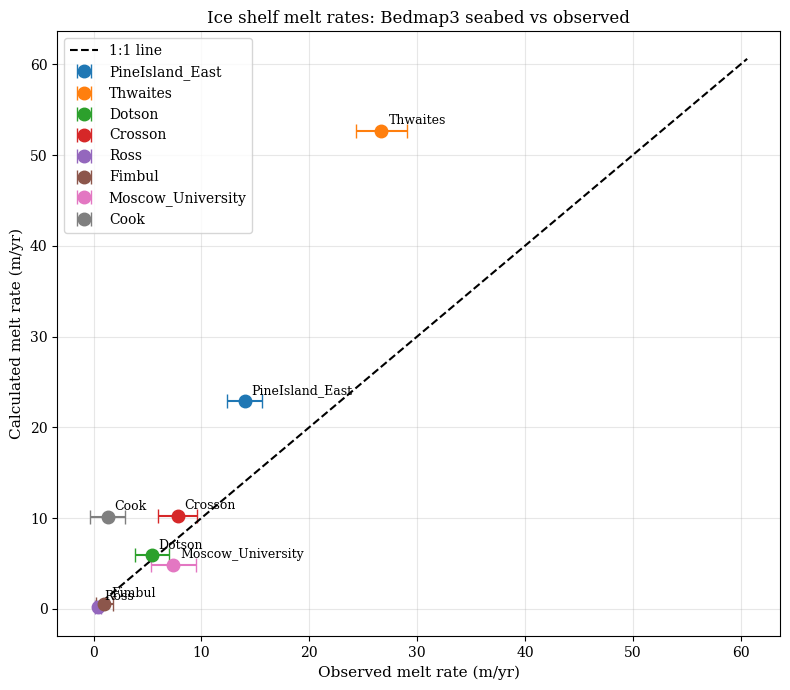

In [22]:
# ── For all except PI---------
for name, res in results.items():
    if name not in melt_parameters:
        continue
    if res['best_coeffs'] is None:
        continue

    y_start       = res['d_cavity_start']
    y_f_val       = res['d_front']
    cavity_length = y_f_val - y_start
    delta_H       = res['delta_H']
    l             = res['l']
    params        = melt_parameters[name]

    M_calc, m_calc, m_max, loc_max = compute_m_bedmap(
        coeffs  = res['best_coeffs'],
        H_f     = res['H_f'],
        delta_H = res['delta_H'],
        y_start = y_start,
        y_f     = y_f_val,
        A       = params['A'],
        T2      = params['T2'],
        l       = l,
        beta    = params['beta'],
    )
    res['m_calc'] = m_calc
    res['M_calc'] = M_calc
    res['cavity_length'] = cavity_length
    print(f"\n{name}:")
    print(f"  H_f={res['H_f']:.1f}m, delta_H={res['delta_H']:.1f}m, l={res['l']:.1f}km")
    print(f"  M_calc={M_calc:.3f} Gt/yr,  m_calc={m_calc:.3f} m/yr")
    print(f"  m_obs ={params['obs_m']:.1f} m/yr")

# ──For Pine island as a combined melt ────────────────────────
merged_shelves = {
    "PineIsland_East": ("PineIsland_East",    "PineIsland_West"),
}

print(f"\n{'─'*60}")
print("  COMBINED MELT RATES")
print(f"{'─'*60}")

plot_results = {}

for display_name, (k1, k2) in merged_shelves.items():
    res1   = results.get(k1)
    res2   = results.get(k2)

    if res1 is None or res2 is None:
        print(f"\n{display_name}: skipping — missing entries")
        continue

    M1 = res1.get('M_calc', np.nan)
    M2 = res2.get('M_calc', np.nan)
    m_max1 = res1.get('m_max', np.nan)
    m_max2 = res2.get('m_max', np.nan)

    if np.isnan(M1) or np.isnan(M2):
        print(f"\n{display_name}: skipping — one lobe has no M_calc")
        continue

    A_total = melt_parameters[k1]['A'] + melt_parameters[k2]['A']
    M_total = M1 + M2
    m_avg   = M_total * 1e12 / 917 / (A_total * 1e6)
    m_max_avg = (m_max1*melt_parameters[k1]['A'] + m_max2*melt_parameters[k2]['A']) / A_total
    loc_max_avg = (res1['loc_max']*melt_parameters[k1]['A'] + res2['loc_max']*melt_parameters[k2]['A']) / A_total

    plot_results[display_name] = {
        'm_calc': m_avg,
        'M_calc': M_total,
        'm_max': m_max_avg,
        'loc_max': loc_max_avg,
    }
    # Average geometry fields from both lobes
    for field in ['cavity_length', 'H_at_GL', 'H_at_front', 'delta_draft',
                  'D_at_GL', 'seabed_slope', 'wc_at_GL', 'avg_Hprime',
                  'avg_Dprime', 'avg_wc', 'avg_water_prime', 'avg_D_double_prime']:
        v1 = res1.get(field) or melt_parameters[k1].get(field)
        v2 = res2.get(field) or melt_parameters[k2].get(field)
        if v1 is not None and v2 is not None:
            plot_results[display_name][field] = (v1 + v2) / 2
        elif v1 is not None:
            plot_results[display_name][field] = v1
        elif v2 is not None:
            plot_results[display_name][field] = v2
    melt_parameters[display_name] = melt_parameters[k1].copy()
    print(f"\n{display_name}:")
    print(f"  {k1}: M={M1:.3f} Gt/yr")
    print(f"  {k2}: M={M2:.3f} Gt/yr")
    print(f"  Combined: M={M_total:.3f} Gt/yr,  m={m_avg:.3f} m/yr")
    print(f"  Your formula check: {(M1+M2)/A_total*1000/0.917:.3f} m/yr")

    # Look up obs_m from one of the lobes, or skip if unavailable
    params1 = melt_parameters.get(k1)
    if params1 and 'obs_m' in params1:
        print(f"  m_obs = {params1['obs_m']:.1f} m/yr")
    else:
        print(f"  m_obs = (not available)")

# Add single shelves to plot_results
handled = {k for keys in merged_shelves.values() for k in keys}
for name, res in results.items():
    if name in handled:
        continue
    if name not in melt_parameters or 'm_calc' not in res:
        continue
    plot_results[name] = res
print("plot_results keys:", list(plot_results.keys()))
print("Thwaites in plot_results:", 'Thwaites' in plot_results)
# ── Plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 7))

for name, res in plot_results.items():
    params = melt_parameters.get(name)
    if params is None:
        continue
    ax.errorbar(params['obs_m'], res['m_calc'],
                xerr=params['obs_err'],
                fmt='o', capsize=5, markersize=9, label=name)
    ax.annotate(name, (params['obs_m'], res['m_calc']),
                xytext=(5, 5), textcoords='offset points', fontsize=9)

all_vals = ([melt_parameters[n]['obs_m'] for n in plot_results if n in melt_parameters] +
            [plot_results[n]['m_calc'] for n in plot_results if n in melt_parameters])
lim = max(all_vals) * 1.15
ax.plot([0, lim], [0, lim], 'k--', lw=1.5, label='1:1 line')
#ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.set_xlabel('Observed melt rate (m/yr)', fontsize=11)
ax.set_ylabel('Calculated melt rate (m/yr)', fontsize=11)
ax.set_title('Ice shelf melt rates: Bedmap3 seabed vs observed', fontsize=12)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('melt_rates_bedmap3.png', dpi=150)
plt.show()

Optimal alpha = 0.0509
α=0.0509,  r=0.984,  R²(1:1)=0.920,  RMSE=2.37 m/yr,  bias=-1.44 m/yr


/var/folders/dp/bxjb_th907g0tlby49jsjkhr0000gn/T/ipykernel_45175/3830711869.py:110: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


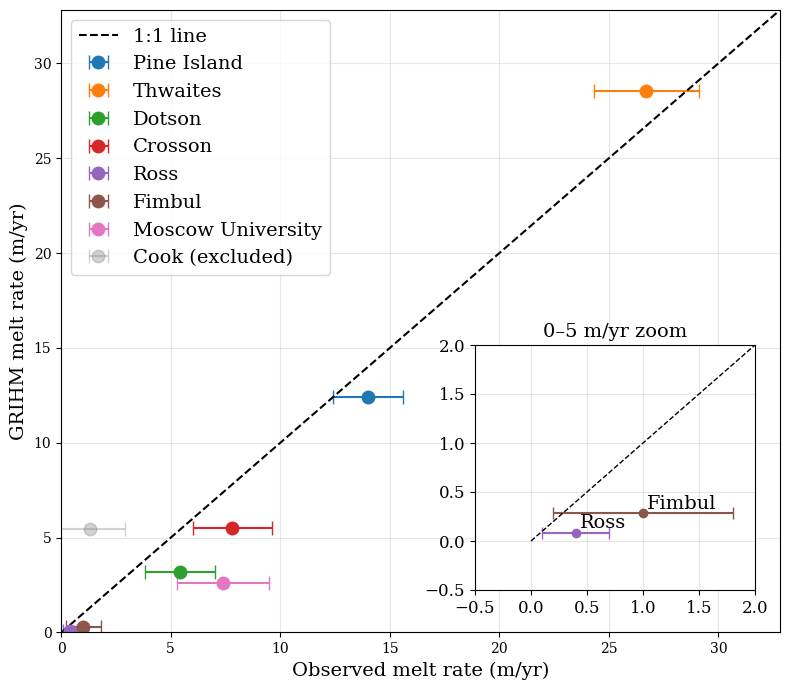

Optimal alpha = 0.0509
RMSE          = 2.374 m/yr
Pearson r     = 0.9839,  p = 6.2229e-05
R² (vs 1:1)   = 0.9200


In [24]:
from scipy import stats
# ------------------------------------------------------------
# Optimal alpha (excluding Cook) — simple least squares on m_calc
# ------------------------------------------------------------
exclude = {'Cook'}
label_map = {
    'Moscow_University': 'Moscow University',                  # removes underscore if original is 'M_U'
    
    'PineIsland_East': 'Pine Island'
}
okabe_ito = [
    '#E69F00', '#56B4E9', '#009E73', '#F0E442', 
    '#0072B2', '#D55E00', '#CC79A7', '#000000'
]

# Map each ice shelf to an Okabe-Ito color. (Cycles if >8 shelves)
shelf_colors = {name: okabe_ito[i % len(okabe_ito)] for i, name in enumerate(plot_results.keys())}

m_calc_arr = []
m_obs_arr  = []

for name, res in plot_results.items():
    if name in exclude:
        continue
    params = melt_parameters.get(name)
    if params is None:
        continue
    m_calc_arr.append(res['m_calc'])
    m_obs_arr.append(params['obs_m'])

m_calc_arr = np.array(m_calc_arr)
m_obs_arr  = np.array(m_obs_arr)
alpha_opt  = np.sum(m_calc_arr * m_obs_arr) / np.sum(m_calc_arr**2)
print(f"Optimal alpha = {0.094*alpha_opt:.4f}")

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 7))

m_obs_plot  = []
m_model_plot = []

for name, res in plot_results.items():
    params = melt_parameters.get(name)
    if params is None:
        continue

    m_scaled = alpha_opt * res['m_calc']
    is_excluded = name in exclude

    
    label_name = label_map.get(name, name)

    ax.errorbar(params['obs_m'], m_scaled,
                xerr=params['obs_err'],
                fmt='o', capsize=5, markersize=9,
                alpha=0.35 if is_excluded else 1.0,
                label=label_name + (' (excluded)' if is_excluded else ''))
    

    m_obs_plot.append(params['obs_m'])
    m_model_plot.append(m_scaled)

# Statistics (excluding Cook)
m_c = np.array([alpha_opt * plot_results[n]['m_calc']
                for n in plot_results if n not in exclude and n in melt_parameters])
m_o = np.array([melt_parameters[n]['obs_m']
                for n in plot_results if n not in exclude and n in melt_parameters])
r, p       = stats.pearsonr(m_o, m_c)
ss_res     = np.sum((m_o - m_c)**2)
ss_tot     = np.sum((m_o - np.mean(m_o))**2)
r2_1to1    = 1 - ss_res / ss_tot
rmse       = np.sqrt(np.mean((m_o - m_c)**2))
bias       = np.mean(m_c - m_o) 

lim = max(max(m_obs_plot), max(m_model_plot)) * 1.15
ax.plot([0, lim], [0, lim], 'k--', lw=1.5, label='1:1 line')
ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.set_xlabel('Observed melt rate (m/yr)', fontsize=14)
ax.set_ylabel('GRIHM melt rate (m/yr)', fontsize=14)

print(f'α={0.094*alpha_opt:.4f},  r={r:.3f},  R²(1:1)={r2_1to1:.3f},  '
    f'RMSE={rmse:.2f} m/yr,  bias={bias:+.2f} m/yr')
ax.legend(fontsize=14)
ax.grid(True, alpha=0.3)
# ── Inset: manually placed axes [left, bottom, width, height] in figure coords
axins = fig.add_axes([0.6, 0.15, 0.35, 0.35])  # tweak these to reposition

for name, res in plot_results.items():
    params = melt_parameters.get(name)
    if params is None:
        continue
    m_scaled = alpha_opt * res['m_calc']
    is_excluded = name in exclude
    axins.errorbar(params['obs_m'], m_scaled,
                   xerr=params['obs_err'],
                   fmt='o', capsize=4, markersize=6,
                   alpha=0.35 if is_excluded else 1.0)
    if 0 <= params['obs_m'] <= 5:
        axins.annotate(name, (params['obs_m'], m_scaled),
                       fontsize=14, xytext=(3, 3),
                       textcoords='offset points')

axins.plot([0, 2], [0, 2], 'k--', lw=1)
axins.set_xlim(-0.5, 2);  axins.set_ylim(-0.5, 2)
axins.set_title('0–5 m/yr zoom', fontsize=14)
axins.tick_params(labelsize=12)
axins.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('melt_rates_bedmap3.pdf', bbox_inches='tight', pad_inches=0.1)
plt.show()

print(f"Optimal alpha = {0.094*alpha_opt:.4f}")
print(f"RMSE          = {rmse:.3f} m/yr")
print(f"Pearson r     = {r:.4f},  p = {p:.4e}")
print(f"R² (vs 1:1)   = {r2_1to1:.4f}")

In [25]:
from scipy import stats

obs_vals   = []
calc_vals  = []
names_used = []

for name, res in plot_results.items():
    
    params = melt_parameters.get(name)
    if params is None:
        continue
    
    obs_vals.append(params['obs_m'])
    calc_vals.append(res['m_calc'])
    names_used.append(name)

obs_vals  = np.array(obs_vals)
calc_vals = np.array(calc_vals)

# ── Optimal scaling (least squares through origin) ─────────────────────
k_opt = np.dot(obs_vals, calc_vals) / np.dot(calc_vals, calc_vals)
calc_scaled = calc_vals * k_opt
print(f"Optimal scaling coefficient: alpha = {0.094*k_opt:.4f}")

# ── Statistics on scaled values ───────────────────────────────────────────────
# R² relative to 1:1 line 
ss_res = np.sum((obs_vals - calc_scaled) ** 2)
ss_tot = np.sum((obs_vals - np.mean(obs_vals)) ** 2)
r2_1to1 = 1 - ss_res / ss_tot

# Pearson r and p-value
r, p = stats.pearsonr(obs_vals, calc_scaled)

print(f"Pearson r  = {r:.4f}")
print(f"p-value    = {p:.4e}")
print(f"R² (vs 1:1)= {r2_1to1:.4f}")

# Also print per-shelf scaled values for sanity checks
print(f"\n{'Shelf':<20} {'obs':>8} {'calc':>8} {'scaled':>8}")
for name, o, c in zip(names_used, obs_vals, calc_vals):
    print(f"{name:<20} {o:>8.2f} {c:>8.2f} {c*k_opt:>8.2f}")

Optimal scaling coefficient: alpha = 0.0498
Pearson r  = 0.9573
p-value    = 1.8796e-04
R² (vs 1:1)= 0.8967

Shelf                     obs     calc   scaled
PineIsland_East         14.00    22.89    12.12
Thwaites                26.70    52.70    27.91
Dotson                   5.40     5.88     3.11
Crosson                  7.80    10.22     5.41
Ross                     0.40     0.16     0.08
Fimbul                   1.00     0.52     0.28
Moscow_University        7.40     4.84     2.56
Cook                     1.30    10.08     5.34


In [26]:
y = np.array([161.98, 54.11, 23.98, 11.54, 3.56, 109.34, 35.86, 27.74])
x = y/0.094*0.0512
print(x)

[88.22740426 29.47268085 13.06144681  6.28561702  1.93906383 59.55540426
 19.53225532 15.10944681]


In [27]:
# ── Cook's z-score (out-of-sample, using k_opt from other shelves) ────────────
cook_params = melt_parameters.get('Cook')
cook_res    = plot_results.get('Cook')

if cook_params and cook_res:
    cook_obs    = cook_params['obs_m']
    cook_calc   = cook_res['m_calc']
    cook_scaled = cook_calc * k_opt

    # Residuals from the fitted model (excluding Cook)
    residuals = obs_vals - calc_scaled          # already defined above

    resid_mean = residuals.mean()
    resid_std  = residuals.std()

    # Cook's residual in the same units
    cook_residual = cook_obs - cook_scaled

    # Z-score: how many σ is Cook away from the mean residual?
    cook_z = (cook_residual - resid_mean) / resid_std

    print(f"\nCook (out-of-sample)")
    print(f"  obs            = {cook_obs:.2f}")
    print(f"  calc (scaled)  = {cook_scaled:.2f}")
    print(f"  residual       = {cook_residual:.2f}")
    print(f"  z-score        = {cook_z:.2f}σ")


Cook (out-of-sample)
  obs            = 1.30
  calc (scaled)  = 5.34
  residual       = -4.04
  z-score        = -1.98σ


In [28]:
residuals = obs_vals - calc_vals * k_opt
std_resid = (residuals - residuals.mean()) / residuals.std()

for name, sr in zip(names_used, std_resid):
    print(f"{name:<20} {sr:>6.2f}σ")

PineIsland_East        0.39σ
Thwaites              -0.85σ
Dotson                 0.56σ
Crosson                0.60σ
Ross                  -0.23σ
Fimbul                -0.07σ
Moscow_University      1.58σ
Cook                  -1.98σ


So Cook can be an outlier

Dotson and crosson are very difficult to find bounding boxes for.

0.05749390467836737
0.04762739745643109
0.08632142018032898
0.07177128595485903
0.17946770980138033
0.14368857080514222
0.05749390467836737
0.04762739745643109
0.08632142018032898
0.07177128595485903
0.17946770980138033
0.14368857080514222
0.05749390467836737
0.04762739745643109
0.08632142018032898
0.07177128595485903
0.17946770980138033
0.14368857080514222
0.05749390467836737
0.04762739745643109
0.08632142018032898
0.07177128595485903
0.17946770980138033
0.14368857080514222
0.05749390467836737
0.04762739745643109
0.08632142018032898
0.07177128595485903
0.17946770980138033
0.14368857080514222
0.05749390467836737
0.04762739745643109
0.08632142018032898
0.07177128595485903
0.17946770980138033
0.14368857080514222
0.05749390467836737
0.04762739745643109
0.08632142018032898
0.07177128595485903
0.17946770980138033
0.14368857080514222
0.05749390467836737
0.04762739745643109
0.08632142018032898
0.07177128595485903
0.17946770980138033
0.14368857080514222
0.05749390467836737
0.04762739745643109


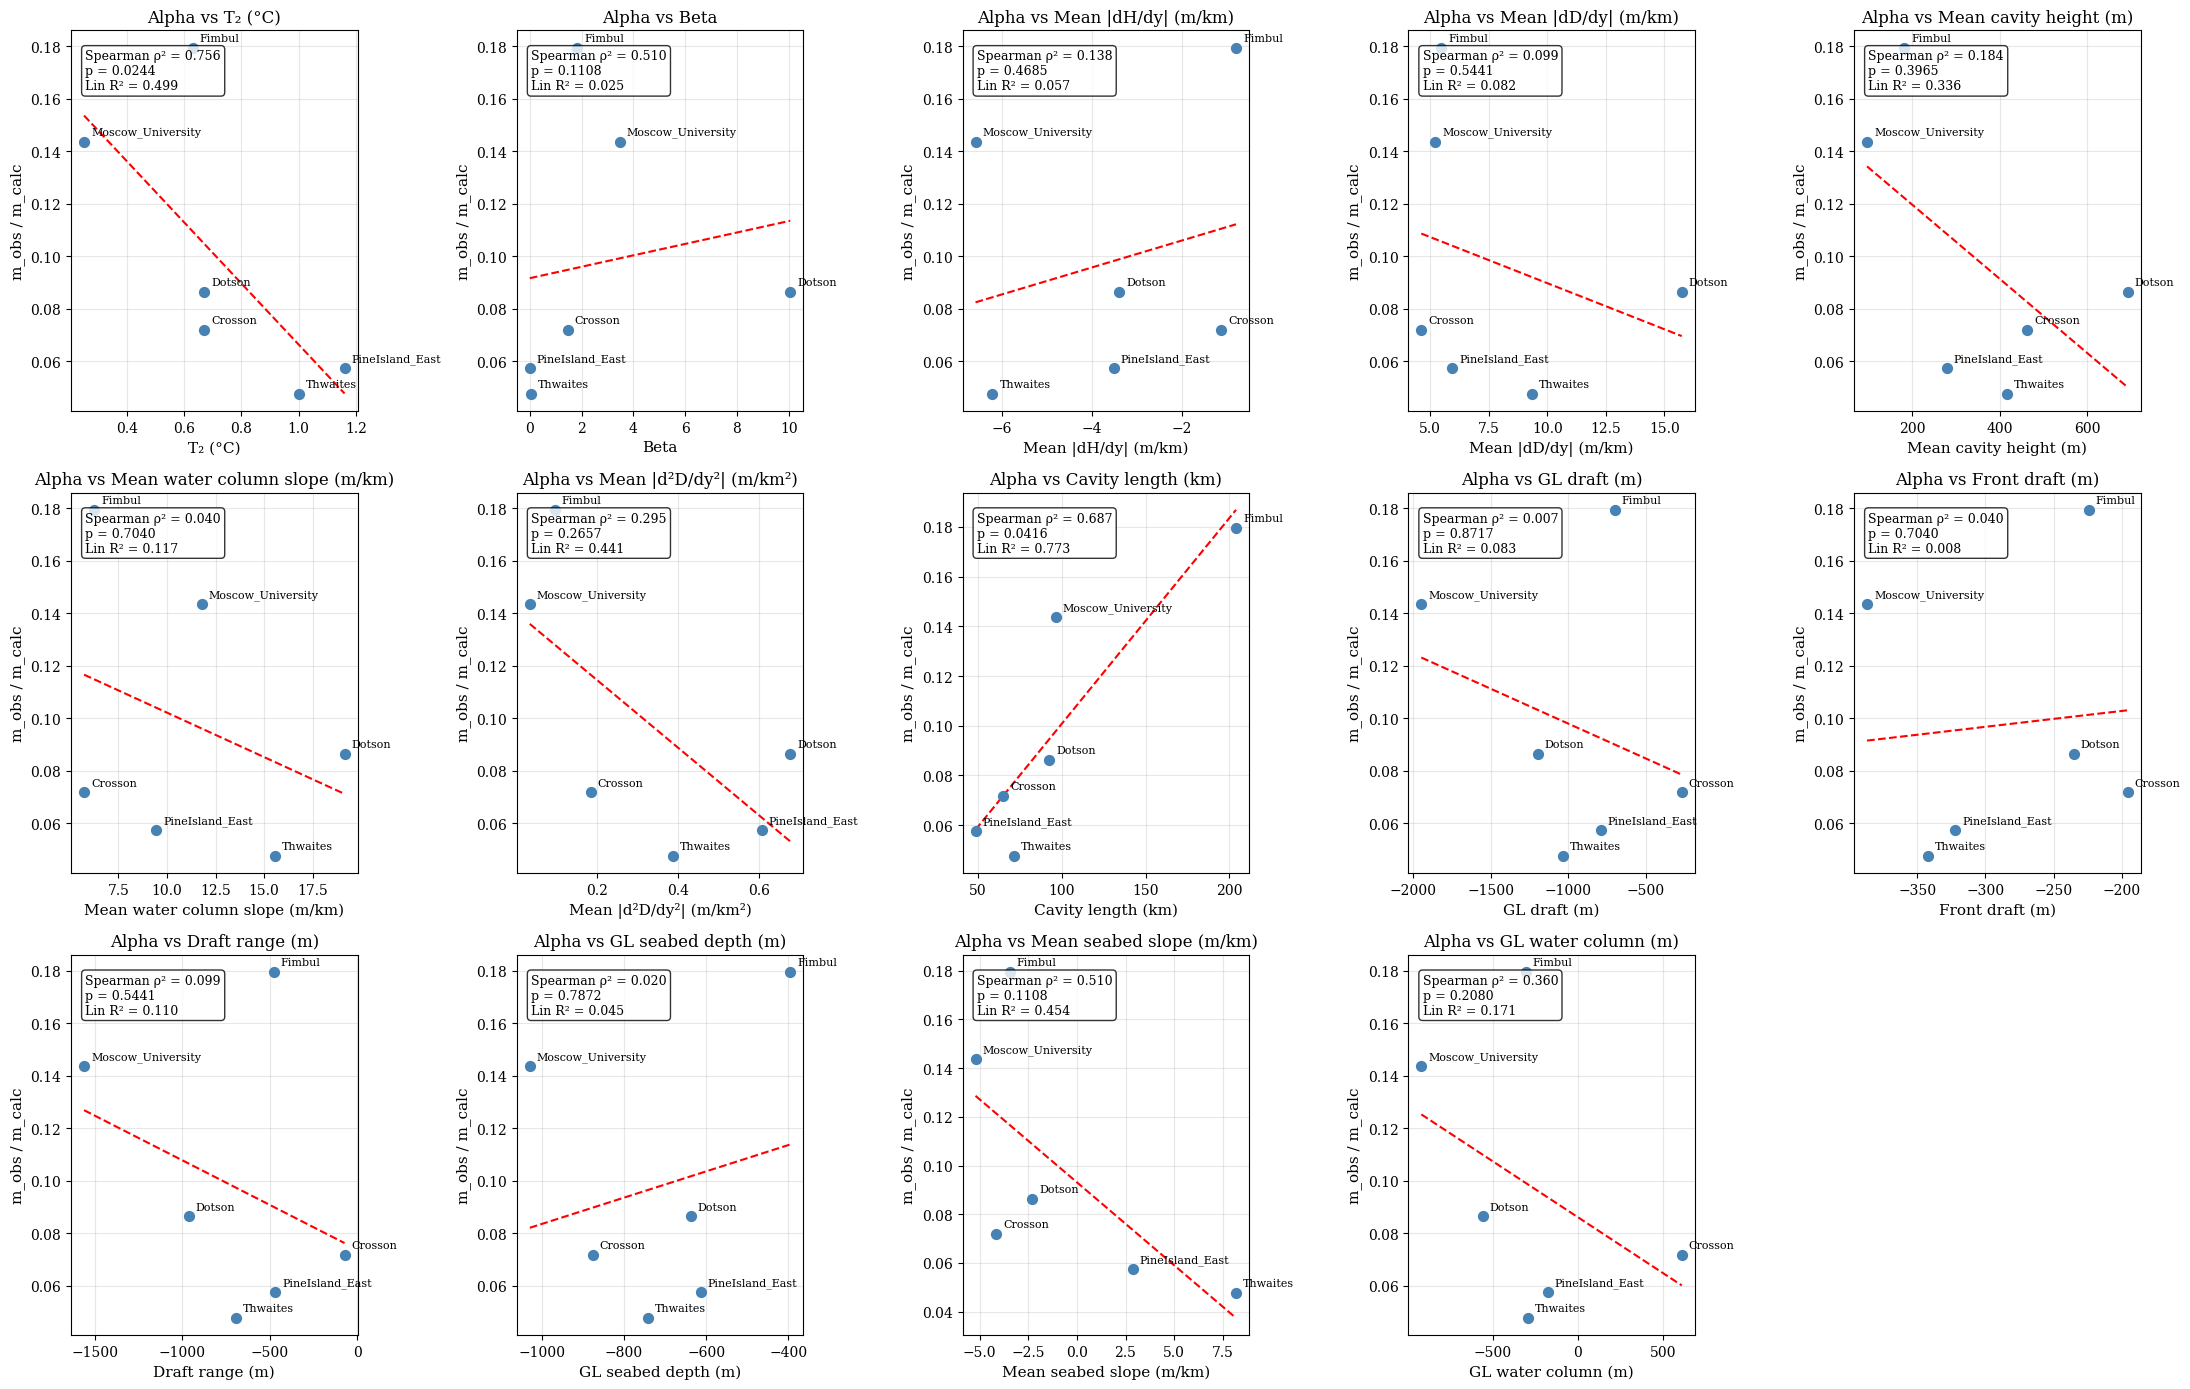

In [30]:

from scipy.stats import spearmanr, linregress 
param_keys = [
    'T2', 'beta',
    'avg_Hprime', 'avg_Dprime', 'avg_wc', 'avg_water_prime', 'avg_D_double_prime',
    # geometry
    'cavity_length', 'H_at_GL', 'H_at_front', 'delta_draft',
    'D_at_GL', 'seabed_slope', 'wc_at_GL',
]
param_labels = [
    'T₂ (°C)', 'Beta',
    'Mean |dH/dy| (m/km)', 'Mean |dD/dy| (m/km)', 'Mean cavity height (m)',
    'Mean water column slope (m/km)', 'Mean |d²D/dy²| (m/km²)',
    # geometry
    'Cavity length (km)', 'GL draft (m)', 'Front draft (m)', 'Draft range (m)',
    'GL seabed depth (m)', 'Mean seabed slope (m/km)', 'GL water column (m)',
]
# Average PineIsland_East and PineIsland_West cavity length into Pine Island
if 'PineIsland_East' in plot_results and 'PineIsland_West' in plot_results:
    east_len = plot_results['PineIsland_East'].get('cavity_length') or melt_parameters['PineIsland_East'].get('cavity_length')
    west_len = plot_results['PineIsland_West'].get('cavity_length') or melt_parameters['PineIsland_West'].get('cavity_length')
    if east_len is not None and west_len is not None:
        avg_len = (east_len + west_len) / 2
        if 'Pine Island' in plot_results:
            plot_results['Pine Island']['cavity_length'] = avg_len
        elif 'PineIsland' in plot_results:
            plot_results['PineIsland']['cavity_length'] = avg_len
fig, axes = plt.subplots(3, 5, figsize=(22, 14))
axes = axes.flatten()
for ax, key, label in zip(axes, param_keys, param_labels):
    x_data, y_data = [], []
    
    for name, res in plot_results.items():
        if name =='Ross':
            continue
        if name =='Cook':
            continue
        # ── Compute ratio directly ────────────────────────────────────────────
        m_calc = res.get('m_calc')
        m_obs  = melt_parameters[name].get('obs_m')
        if m_calc is None or m_obs is None or m_obs == 0:
            continue
        alpha_calc = m_obs / m_calc*0.094
        print(alpha_calc)
        # ─────────────────────────────────────────────────────────────────────
        val = res.get(key) if key in res else melt_parameters[name].get(key)
        if val is None:
            continue
            
        x_data.append(val)
        y_data.append(alpha_calc)
        
        ax.scatter(val, alpha_calc, color='steelblue', s=50, zorder=3)
        ax.annotate(name, (val, alpha_calc), xytext=(5, 5), textcoords='offset points', fontsize=8)
    if len(x_data) > 2:
        x_arr = np.array(x_data)
        y_arr = np.array(y_data)
        rho, p = spearmanr(x_arr, y_arr)
        slope, intercept, r_value, p_lin, se = stats.linregress(x_arr, y_arr)
        x_line = np.linspace(x_arr.min(), x_arr.max(), 100)
        ax.plot(x_line, slope * x_line + intercept, 'r--', lw=1.5, zorder=2)
        stats_text = (f"Spearman ρ² = {rho**2:.3f}\n"
                      f"p = {p:.4f}\n"
                      f"Lin R² = {r_value**2:.3f}")
        ax.text(0.05, 0.95, stats_text, transform=ax.transAxes, verticalalignment='top',
                bbox=dict(boxstyle='round', facecolor='white', alpha=0.8), fontsize=9)
    ax.set_xlabel(label, fontsize=11)
    ax.set_ylabel('m_obs / m_calc', fontsize=11)
    ax.set_title(f'Alpha vs {label}', fontsize=12)
    ax.grid(True, alpha=0.3)
axes[-1].set_visible(False)
plt.tight_layout()
plt.show()

0.05749390467836737
0.04762739745643109
0.08632142018032898
0.07177128595485903
0.23737603553029302
0.17946770980138033
0.14368857080514222
0.05749390467836737
0.04762739745643109
0.08632142018032898
0.07177128595485903
0.23737603553029302
0.17946770980138033
0.14368857080514222
0.05749390467836737
0.04762739745643109
0.08632142018032898
0.07177128595485903
0.23737603553029302
0.17946770980138033
0.14368857080514222
0.05749390467836737
0.04762739745643109
0.08632142018032898
0.07177128595485903
0.23737603553029302
0.17946770980138033
0.14368857080514222
0.05749390467836737
0.04762739745643109
0.08632142018032898
0.07177128595485903
0.23737603553029302
0.17946770980138033
0.14368857080514222
0.05749390467836737
0.04762739745643109
0.08632142018032898
0.07177128595485903
0.23737603553029302
0.17946770980138033
0.14368857080514222
0.05749390467836737
0.04762739745643109
0.08632142018032898
0.07177128595485903
0.23737603553029302
0.17946770980138033
0.14368857080514222
0.05749390467836737


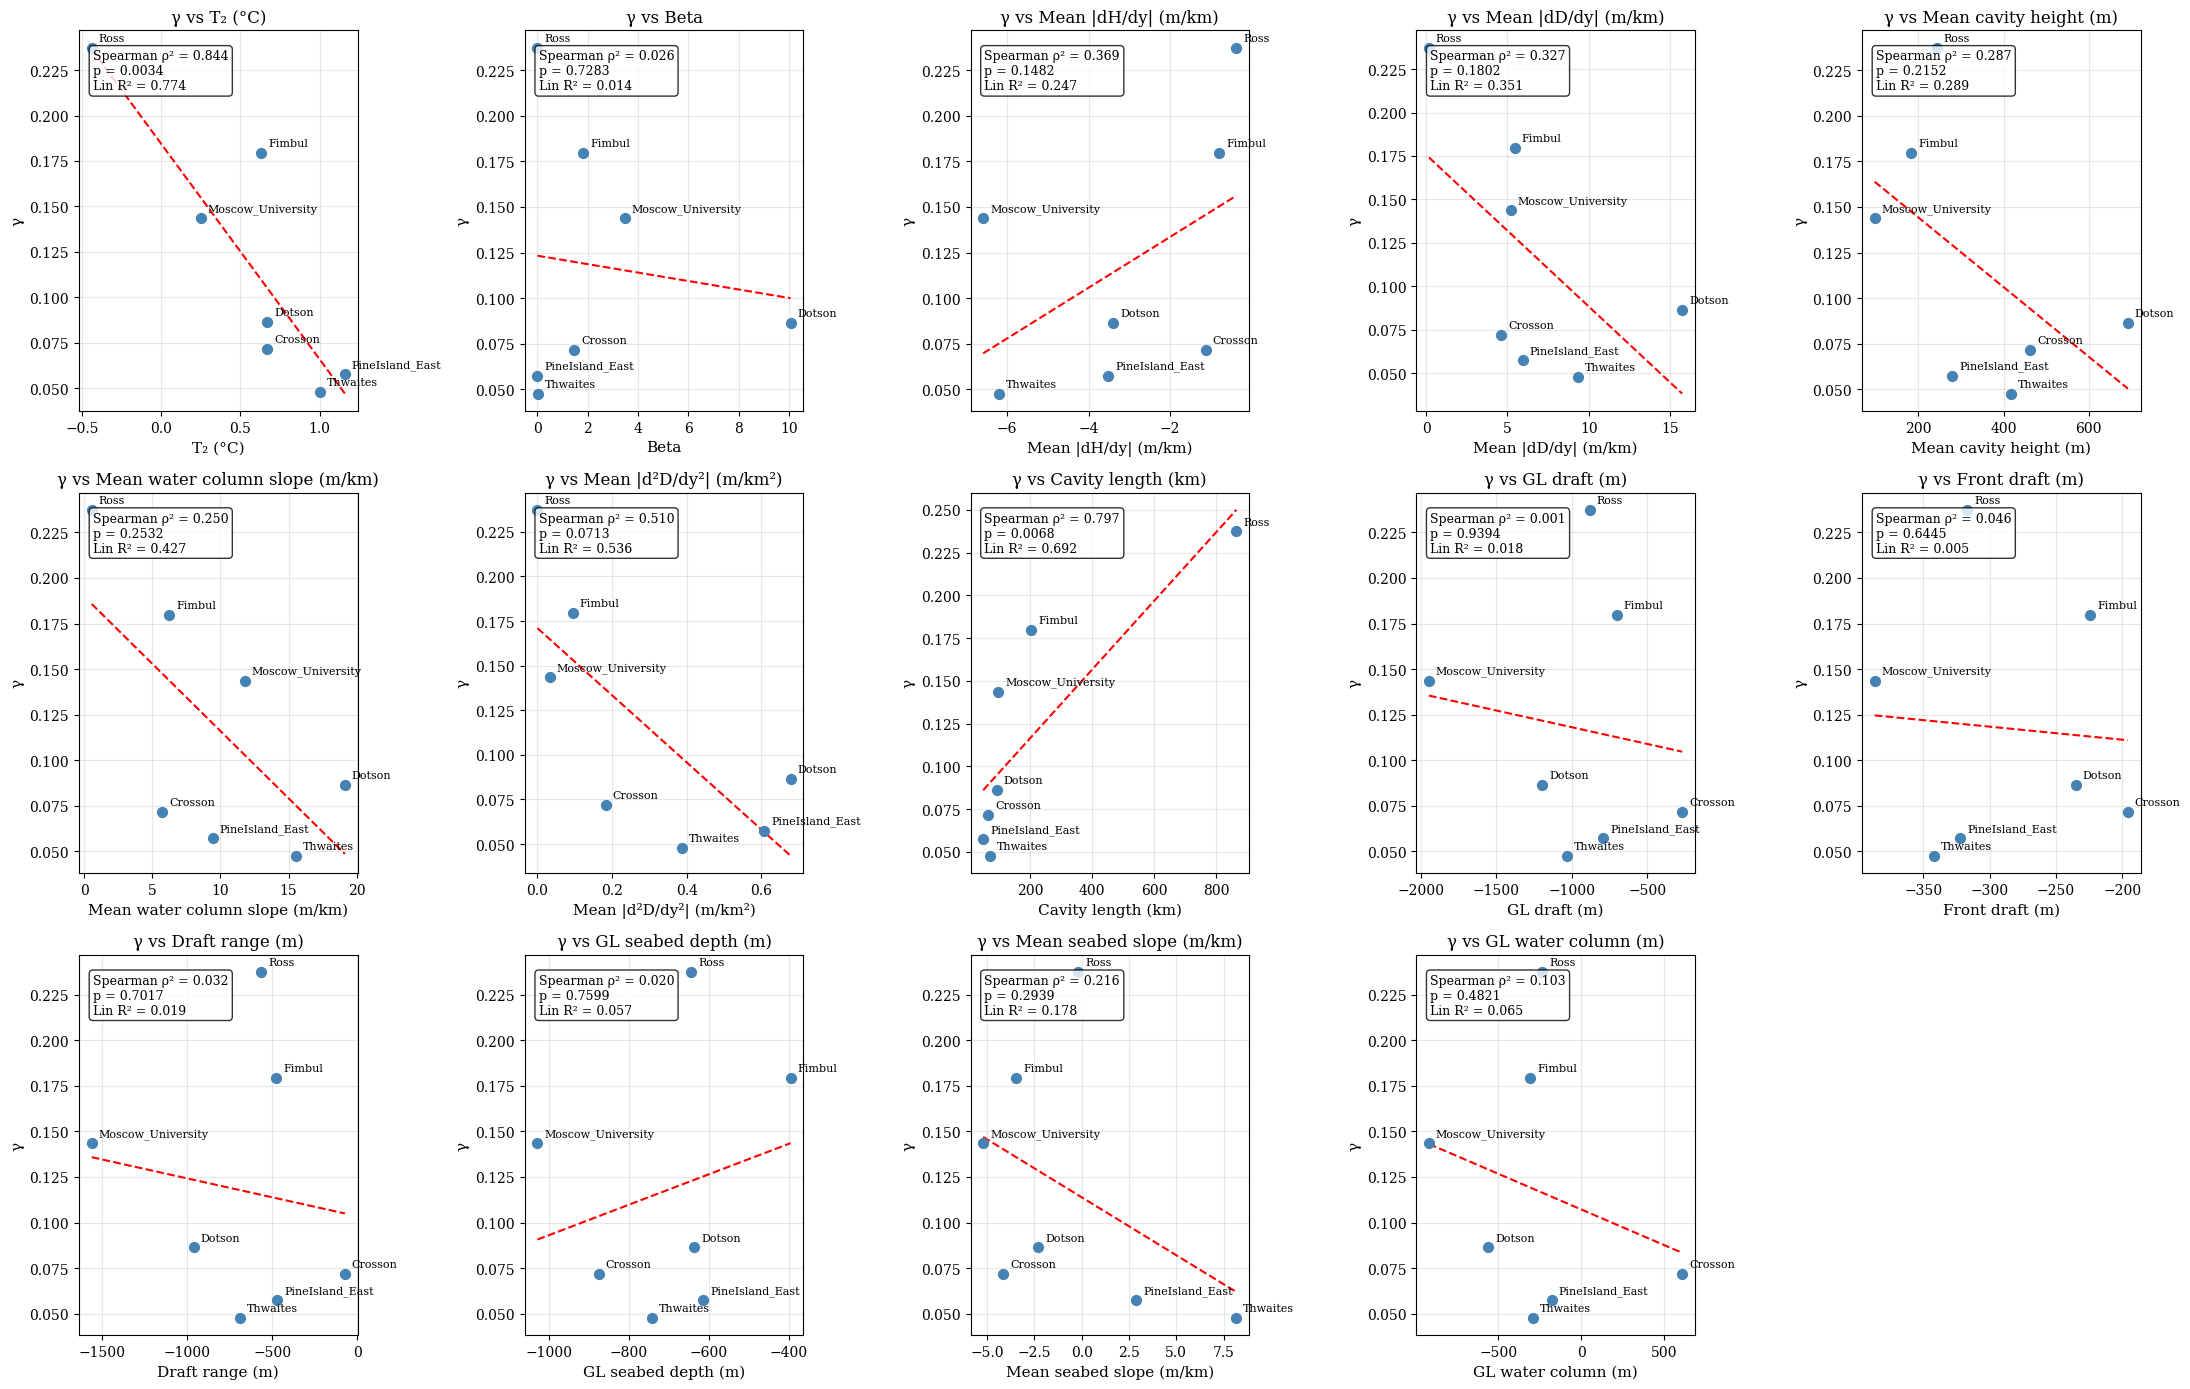

In [31]:

param_keys = [
    'T2', 'beta',
    'avg_Hprime', 'avg_Dprime', 'avg_wc', 'avg_water_prime', 'avg_D_double_prime',
    # geometry
    'cavity_length', 'H_at_GL', 'H_at_front', 'delta_draft',
    'D_at_GL', 'seabed_slope', 'wc_at_GL',
]
param_labels = [
    'T₂ (°C)', 'Beta',
    'Mean |dH/dy| (m/km)', 'Mean |dD/dy| (m/km)', 'Mean cavity height (m)',
    'Mean water column slope (m/km)', 'Mean |d²D/dy²| (m/km²)',
    # geometry
    'Cavity length (km)', 'GL draft (m)', 'Front draft (m)', 'Draft range (m)',
    'GL seabed depth (m)', 'Mean seabed slope (m/km)', 'GL water column (m)',
]
# Average PineIsland_East and PineIsland_West cavity length into Pine Island
if 'PineIsland_East' in plot_results and 'PineIsland_West' in plot_results:
    east_len = plot_results['PineIsland_East'].get('cavity_length') or melt_parameters['PineIsland_East'].get('cavity_length')
    west_len = plot_results['PineIsland_West'].get('cavity_length') or melt_parameters['PineIsland_West'].get('cavity_length')
    if east_len is not None and west_len is not None:
        avg_len = (east_len + west_len) / 2
        if 'Pine Island' in plot_results:
            plot_results['Pine Island']['cavity_length'] = avg_len
        elif 'PineIsland' in plot_results:
            plot_results['PineIsland']['cavity_length'] = avg_len
fig, axes = plt.subplots(3, 5, figsize=(22, 14))
axes = axes.flatten()
for ax, key, label in zip(axes, param_keys, param_labels):
    x_data, y_data = [], []
    
    for name, res in plot_results.items():
        
        if name =='Cook':
            continue
        # ── Compute ratio directly ────────────────────────────────────────────
        m_calc = res.get('m_calc')
        m_obs  = melt_parameters[name].get('obs_m')
        if m_calc is None or m_obs is None or m_obs == 0:
            continue
        alpha_calc = m_obs / m_calc*0.094
        print(alpha_calc)
        # ─────────────────────────────────────────────────────────────────────
        val = res.get(key) if key in res else melt_parameters[name].get(key)
        if val is None:
            continue
            
        x_data.append(val)
        y_data.append(alpha_calc)
        
        ax.scatter(val, alpha_calc, color='steelblue', s=50, zorder=3)
        ax.annotate(name, (val, alpha_calc), xytext=(5, 5), textcoords='offset points', fontsize=8)
    if len(x_data) > 2:
        x_arr = np.array(x_data)
        y_arr = np.array(y_data)
        rho, p = spearmanr(x_arr, y_arr)
        slope, intercept, r_value, p_lin, se = stats.linregress(x_arr, y_arr)
        x_line = np.linspace(x_arr.min(), x_arr.max(), 100)
        ax.plot(x_line, slope * x_line + intercept, 'r--', lw=1.5, zorder=2)
        stats_text = (f"Spearman ρ² = {rho**2:.3f}\n"
                      f"p = {p:.4f}\n"
                      f"Lin R² = {r_value**2:.3f}")
        ax.text(0.05, 0.95, stats_text, transform=ax.transAxes, verticalalignment='top',
                bbox=dict(boxstyle='round', facecolor='white', alpha=0.8), fontsize=9)
    ax.set_xlabel(label, fontsize=11)
    ax.set_ylabel('γ', fontsize=11)
    ax.set_title(f'γ vs {label}', fontsize=12)
    ax.grid(True, alpha=0.3)
axes[-1].set_visible(False)
plt.tight_layout()
plt.show()

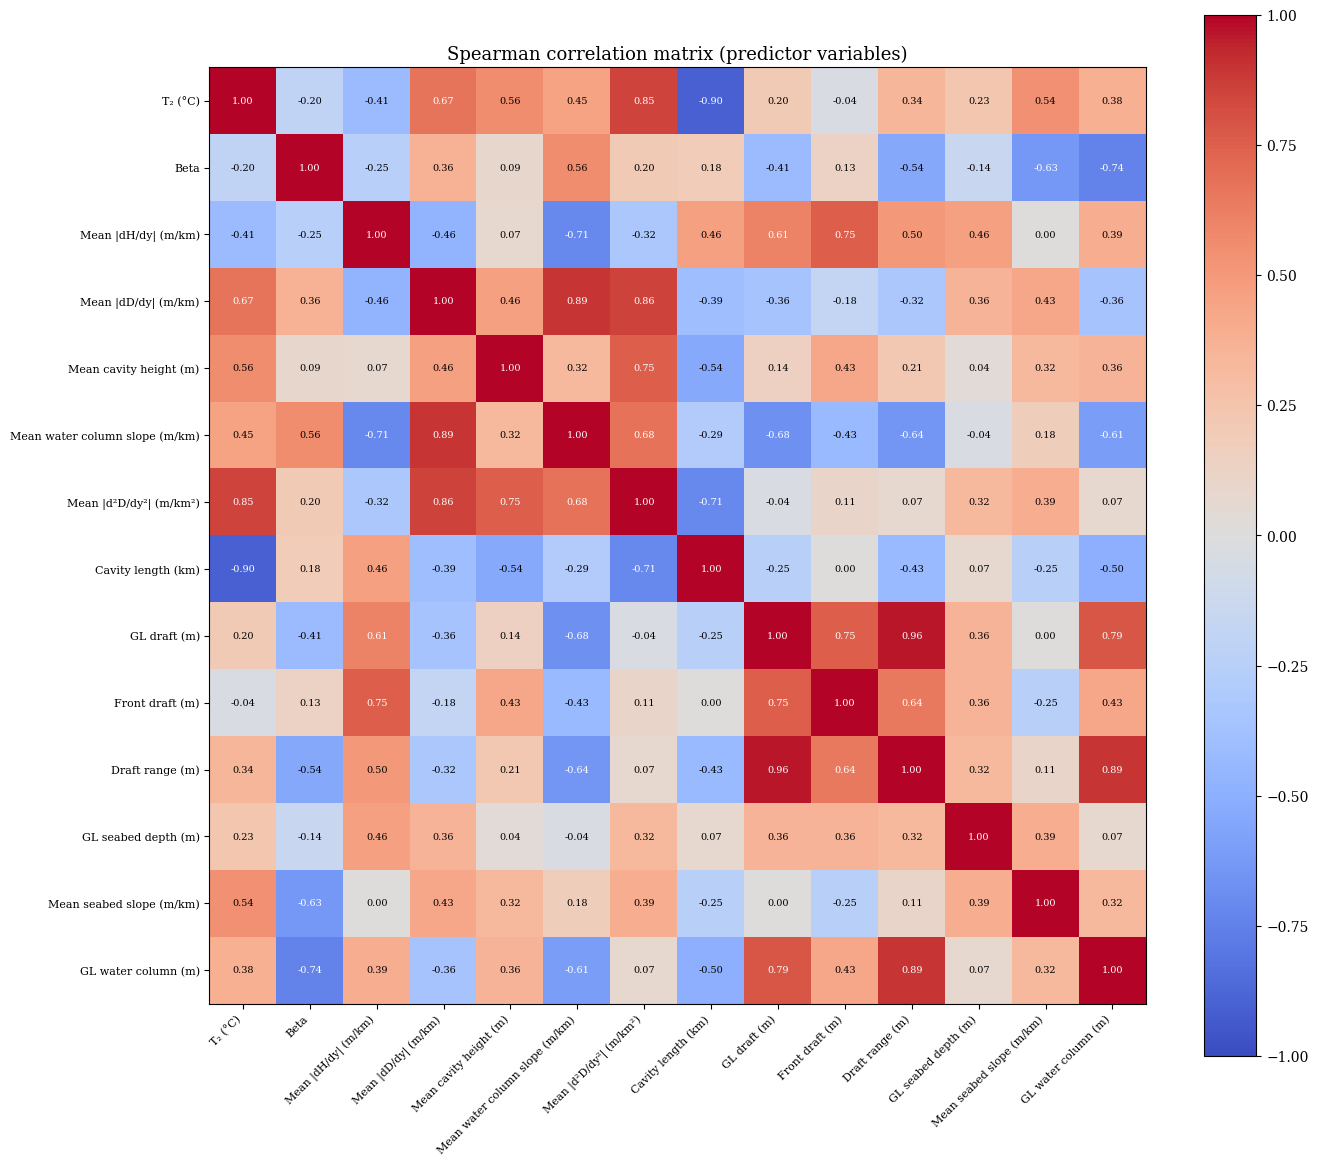


Correlations with cavity_length:
cavity_length         1.000000
avg_Hprime            0.464286
beta                  0.180187
D_at_GL               0.071429
H_at_front            0.000000
H_at_GL              -0.250000
seabed_slope         -0.250000
avg_water_prime      -0.285714
avg_Dprime           -0.392857
delta_draft          -0.428571
wc_at_GL             -0.500000
avg_wc               -0.535714
avg_D_double_prime   -0.714286
T2                   -0.900937
Name: cavity_length, dtype: float64


In [32]:
import pandas as pd

records = []
for name, res in plot_results.items():
    if name == 'Cook':
        continue
    row = {'shelf': name}
    for key in param_keys:
        val = res.get(key) if key in res else melt_parameters[name].get(key)
        row[key] = val
    records.append(row)

df = pd.DataFrame(records).set_index('shelf')
df = df[param_keys].dropna(axis=1, how='any')

# Spearman correlation matrix
corr_matrix = df.corr(method='spearman')

fig, ax = plt.subplots(figsize=(14, 12))
im = ax.imshow(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(im, ax=ax)

ax.set_xticks(range(len(corr_matrix.columns)))
ax.set_yticks(range(len(corr_matrix.columns)))
ax.set_xticklabels(param_labels[:len(corr_matrix.columns)], rotation=45, ha='right', fontsize=8)
ax.set_yticklabels(param_labels[:len(corr_matrix.columns)], fontsize=8)

for i in range(len(corr_matrix)):
    for j in range(len(corr_matrix.columns)):
        ax.text(j, i, f'{corr_matrix.iloc[i, j]:.2f}',
                ha='center', va='center', fontsize=7,
                color='white' if abs(corr_matrix.iloc[i, j]) > 0.6 else 'black')

ax.set_title('Spearman correlation matrix (predictor variables)', fontsize=13)
plt.tight_layout()
plt.show()

print("\nCorrelations with cavity_length:")
print(corr_matrix['cavity_length'].sort_values(ascending=False))

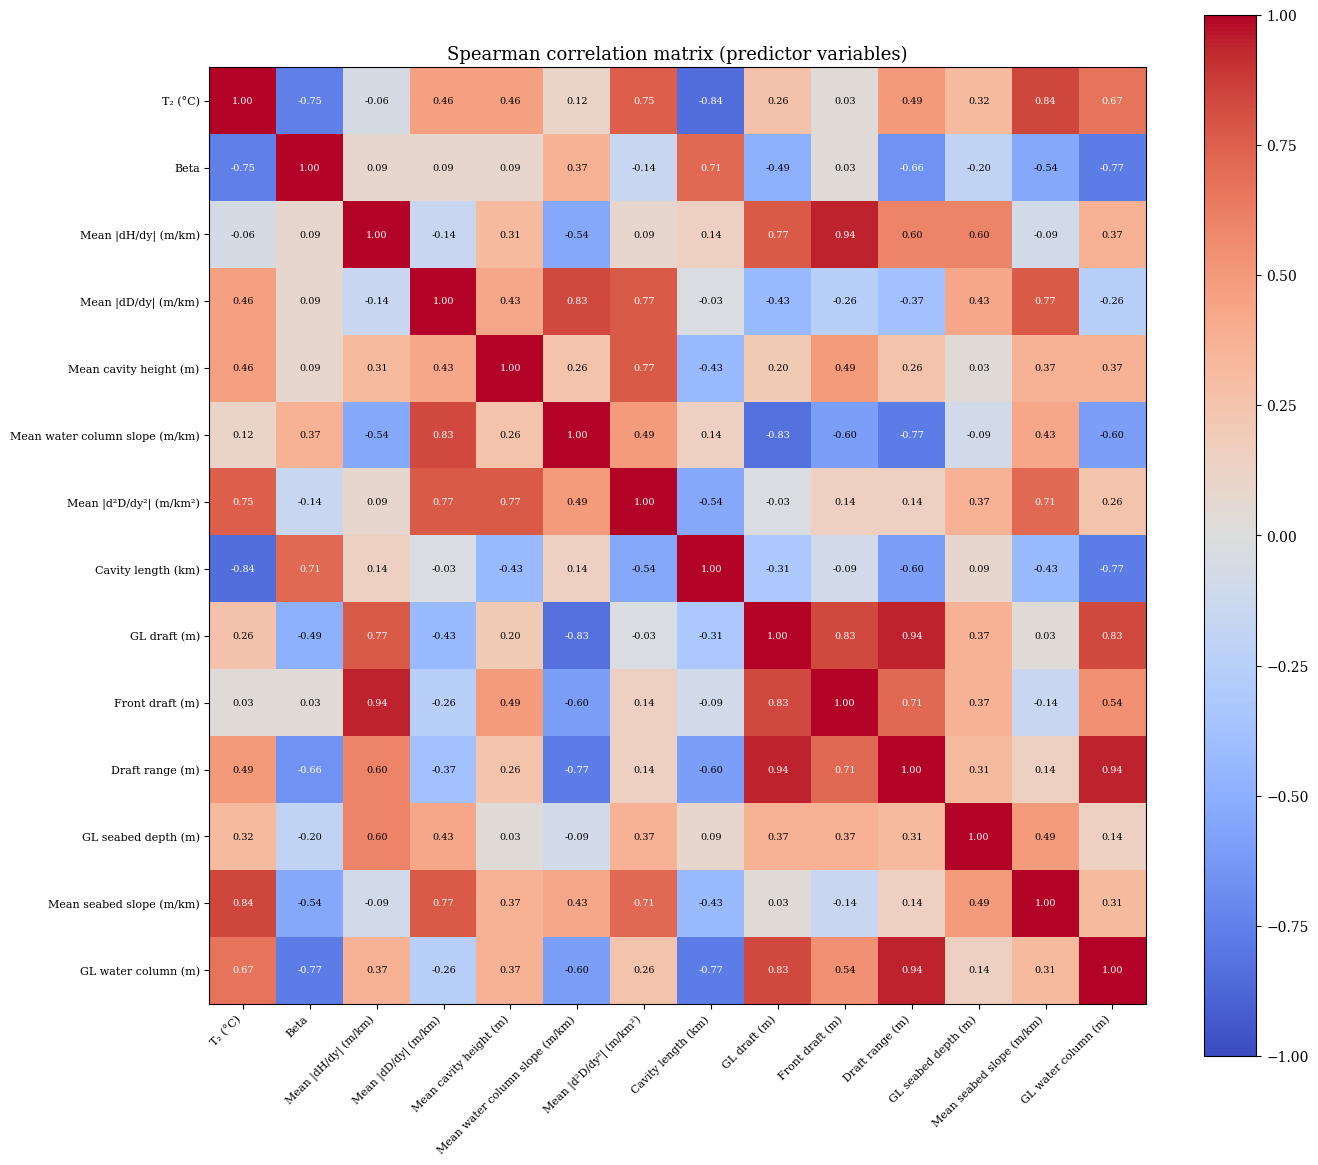


Correlations with cavity_length:
cavity_length         1.000000
beta                  0.714286
avg_Hprime            0.142857
avg_water_prime       0.142857
D_at_GL               0.085714
avg_Dprime           -0.028571
H_at_front           -0.085714
H_at_GL              -0.314286
avg_wc               -0.428571
seabed_slope         -0.428571
avg_D_double_prime   -0.542857
delta_draft          -0.600000
wc_at_GL             -0.771429
T2                   -0.840668
Name: cavity_length, dtype: float64


In [33]:
import pandas as pd

records = []
for name, res in plot_results.items():
    if name == 'Cook':
        continue
    if name == 'Ross':
        continue
    row = {'shelf': name}
    for key in param_keys:
        val = res.get(key) if key in res else melt_parameters[name].get(key)
        row[key] = val
    records.append(row)

df = pd.DataFrame(records).set_index('shelf')
df = df[param_keys].dropna(axis=1, how='any')

corr_matrix = df.corr(method='spearman')

fig, ax = plt.subplots(figsize=(14, 12))
im = ax.imshow(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(im, ax=ax)

ax.set_xticks(range(len(corr_matrix.columns)))
ax.set_yticks(range(len(corr_matrix.columns)))
ax.set_xticklabels(param_labels[:len(corr_matrix.columns)], rotation=45, ha='right', fontsize=8)
ax.set_yticklabels(param_labels[:len(corr_matrix.columns)], fontsize=8)

for i in range(len(corr_matrix)):
    for j in range(len(corr_matrix.columns)):
        ax.text(j, i, f'{corr_matrix.iloc[i, j]:.2f}',
                ha='center', va='center', fontsize=7,
                color='white' if abs(corr_matrix.iloc[i, j]) > 0.6 else 'black')

ax.set_title('Spearman correlation matrix (predictor variables)', fontsize=13)
plt.tight_layout()
plt.show()

print("\nCorrelations with cavity_length:")
print(corr_matrix['cavity_length'].sort_values(ascending=False))

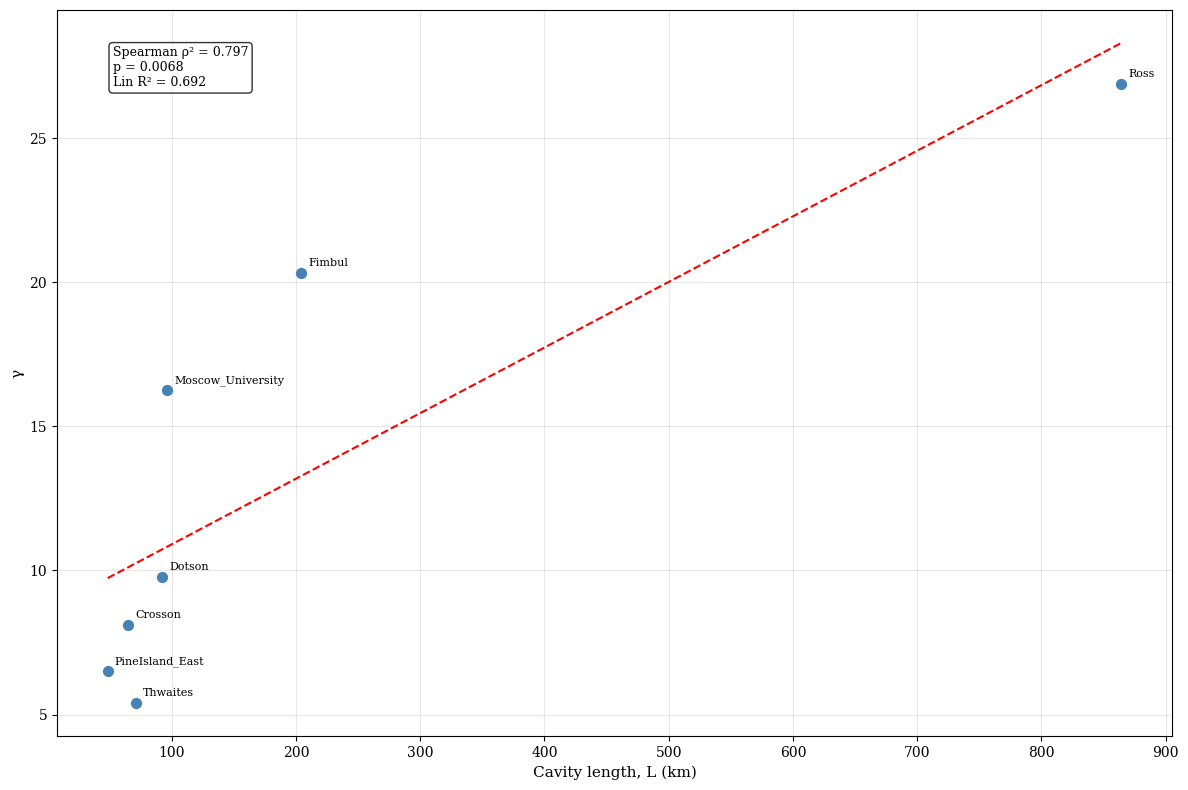

In [34]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import spearmanr, linregress 

param_keys = ['cavity_length']
param_labels = ['Cavity length, L (km)']

fig, ax_main = plt.subplots(1, 1, figsize=(12, 8)) 
axes_list = [ax_main]

for ax, key, label in zip(axes_list, param_keys, param_labels):
    x_data, y_data = [], []
    
    for name, res in plot_results.items():
        if name == 'Cook':
            continue
            
        # Compute ratio
        m_calc = res.get('m_calc')
        m_obs = melt_parameters[name].get('obs_m')
        
        if m_calc is None or m_obs is None or m_obs == 0:
            continue
            
        alpha_calc = m_obs / (m_calc * 0.094)
        
        val = res.get(key) if key in res else melt_parameters[name].get(key)
        if val is None:
            continue
            
        x_data.append(val)
        y_data.append(alpha_calc)
        
        ax.scatter(val, alpha_calc, color='steelblue', s=50, zorder=3)
        ax.annotate(name, (val, alpha_calc), xytext=(5, 5), 
                    textcoords='offset points', fontsize=8)

    if len(x_data) > 2:
        x_arr = np.array(x_data)
        y_arr = np.array(y_data)
        
        rho, p = spearmanr(x_arr, y_arr)

        slope, intercept, r_value, p_lin, se = linregress(x_arr, y_arr)
        
        x_line = np.linspace(x_arr.min(), x_arr.max(), 100)
        ax.plot(x_line, slope * x_line + intercept, 'r--', lw=1.5, zorder=2)
        
        stats_text = (f"Spearman ρ² = {rho**2:.3f}\n"
                      f"p = {p:.4f}\n"
                      f"Lin R² = {r_value**2:.3f}")
        ax.text(0.05, 0.95, stats_text, transform=ax.transAxes, verticalalignment='top',
                bbox=dict(boxstyle='round', facecolor='white', alpha=0.8), fontsize=9)
    
    ax.set_xlabel(label, fontsize=11)
    ax.set_ylabel('γ', fontsize=11)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

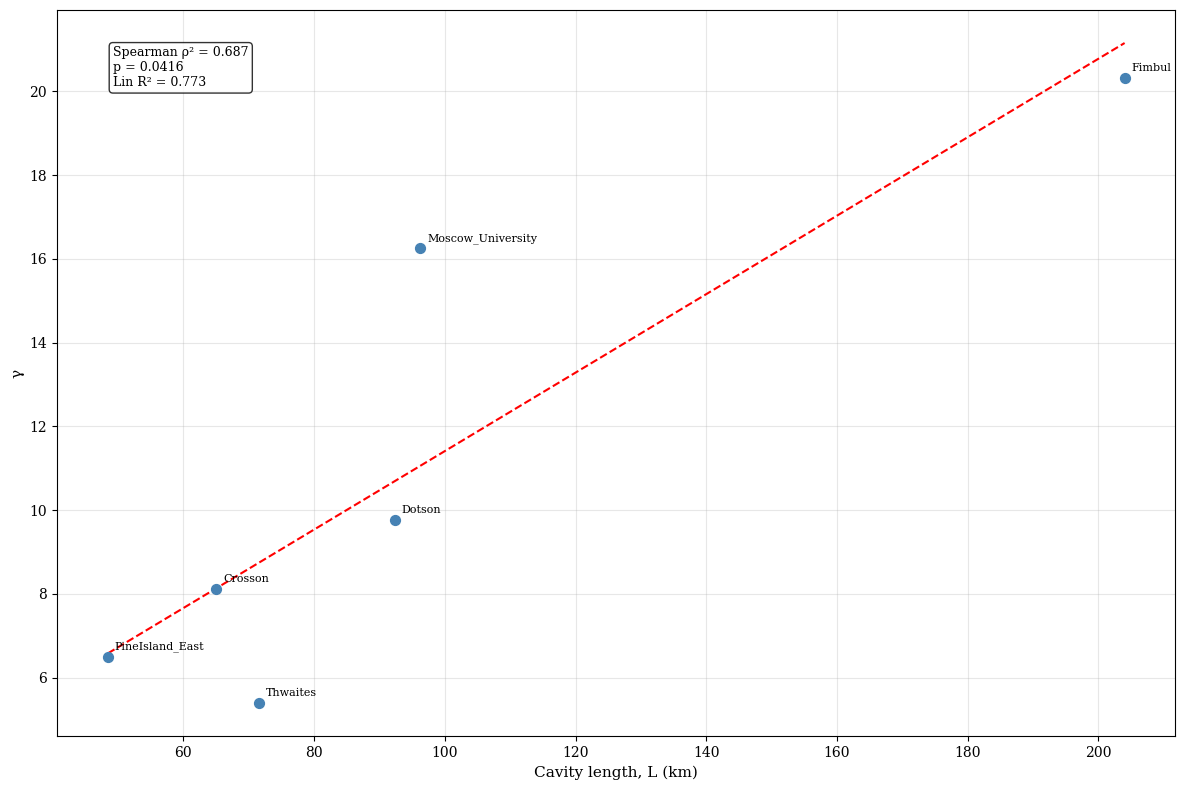

In [35]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import spearmanr, linregress 

param_keys = ['cavity_length']
param_labels = ['Cavity length, L (km)']

fig, ax_main = plt.subplots(1, 1, figsize=(12, 8)) 
axes_list = [ax_main]

for ax, key, label in zip(axes_list, param_keys, param_labels):
    x_data, y_data = [], []
    
    for name, res in plot_results.items():
        if name == 'Cook':
            continue
        if name == 'Ross':
            continue
            
        # Compute ratio
        m_calc = res.get('m_calc')
        m_obs = melt_parameters[name].get('obs_m')
        
        if m_calc is None or m_obs is None or m_obs == 0:
            continue
            
        alpha_calc = m_obs / (m_calc * 0.094)
        
        
        val = res.get(key) if key in res else melt_parameters[name].get(key)
        if val is None:
            continue
            
        x_data.append(val)
        y_data.append(alpha_calc)
        
        ax.scatter(val, alpha_calc, color='steelblue', s=50, zorder=3)
        ax.annotate(name, (val, alpha_calc), xytext=(5, 5), 
                    textcoords='offset points', fontsize=8)

    if len(x_data) > 2:
        x_arr = np.array(x_data)
        y_arr = np.array(y_data)
        
        rho, p = spearmanr(x_arr, y_arr)
        slope, intercept, r_value, p_lin, se = linregress(x_arr, y_arr)
        
        x_line = np.linspace(x_arr.min(), x_arr.max(), 100)
        ax.plot(x_line, slope * x_line + intercept, 'r--', lw=1.5, zorder=2)
        
        stats_text = (f"Spearman ρ² = {rho**2:.3f}\n"
                      f"p = {p:.4f}\n"
                      f"Lin R² = {r_value**2:.3f}")
        ax.text(0.05, 0.95, stats_text, transform=ax.transAxes, verticalalignment='top',
                bbox=dict(boxstyle='round', facecolor='white', alpha=0.8), fontsize=9)
    
    ax.set_xlabel(label, fontsize=11)
    ax.set_ylabel('γ', fontsize=11)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

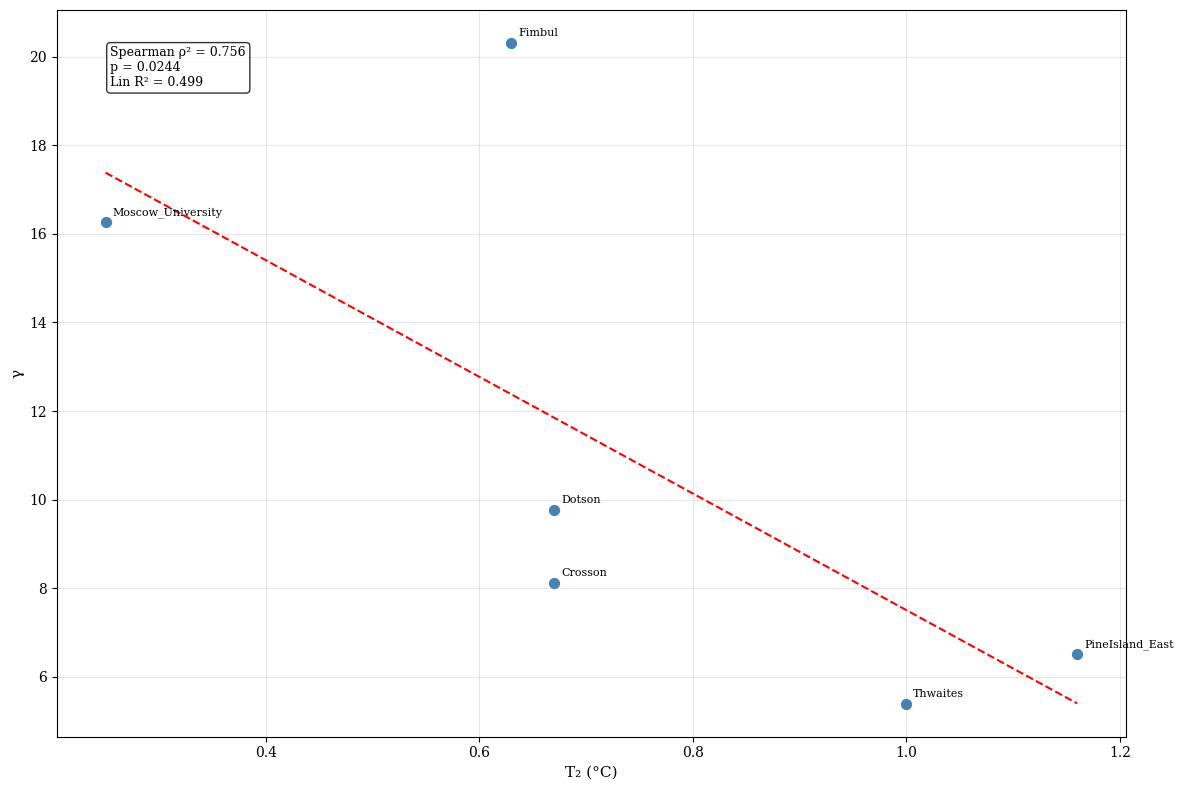

In [36]:


param_keys = ['T2']
param_labels = ['T₂ (°C)']

fig, ax_main = plt.subplots(1, 1, figsize=(12, 8)) 
axes_list = [ax_main]

for ax, key, label in zip(axes_list, param_keys, param_labels):
    x_data, y_data = [], []
    
    for name, res in plot_results.items():
        if name == 'Cook':
            continue
        if name == 'Ross':
            continue
            
        # Compute ratio
        m_calc = res.get('m_calc')
        m_obs = melt_parameters[name].get('obs_m')
        
        if m_calc is None or m_obs is None or m_obs == 0:
            continue
            
        alpha_calc = m_obs / (m_calc * 0.094)
        
        
        val = res.get(key) if key in res else melt_parameters[name].get(key)
        if val is None:
            continue
            
        x_data.append(val)
        y_data.append(alpha_calc)
        
        ax.scatter(val, alpha_calc, color='steelblue', s=50, zorder=3)
        ax.annotate(name, (val, alpha_calc), xytext=(5, 5), 
                    textcoords='offset points', fontsize=8)

    if len(x_data) > 2:
        x_arr = np.array(x_data)
        y_arr = np.array(y_data)
        
        rho, p = spearmanr(x_arr, y_arr)
        slope, intercept, r_value, p_lin, se = linregress(x_arr, y_arr)
        
        x_line = np.linspace(x_arr.min(), x_arr.max(), 100)
        ax.plot(x_line, slope * x_line + intercept, 'r--', lw=1.5, zorder=2)
        
        stats_text = (f"Spearman ρ² = {rho**2:.3f}\n"
                      f"p = {p:.4f}\n"
                      f"Lin R² = {r_value**2:.3f}")
        ax.text(0.05, 0.95, stats_text, transform=ax.transAxes, verticalalignment='top',
                bbox=dict(boxstyle='round', facecolor='white', alpha=0.8), fontsize=9)
    
    ax.set_xlabel(label, fontsize=11)
    ax.set_ylabel('γ', fontsize=11)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [37]:
import sys
!{sys.executable} -m pip install adjustText

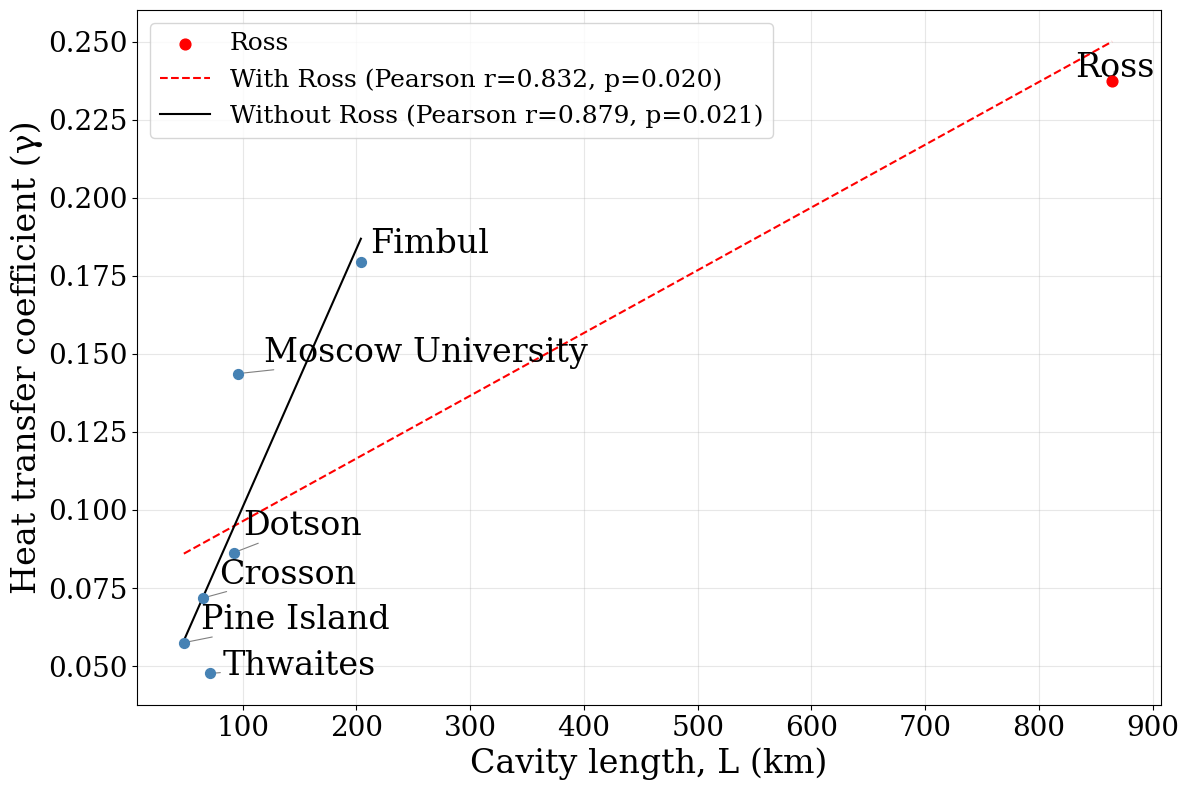

In [38]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import spearmanr, linregress 
from adjustText import adjust_text

param_keys = ['cavity_length']
param_labels = ['Cavity length, L (km)']

fig, ax_main = plt.subplots(1, 1, figsize=(12, 8)) 
axes_list = [ax_main]

for ax, key, label in zip(axes_list, param_keys, param_labels):
    x_data, y_data = [], []
    x_no_ross, y_no_ross = [], []
    texts =[]
    for name, res in plot_results.items():
        if name == 'Cook':
            continue
        plot_name = label_map.get(name, name)
        m_calc = res.get('m_calc')
        m_obs = melt_parameters[name].get('obs_m')
        
        if m_calc is None or m_obs is None or m_obs == 0:
            continue
            
        
        alpha_calc = m_obs / (m_calc )* 0.094
        val = res.get(key) if key in res else melt_parameters[name].get(key)
        
        if val is None:
            continue
            
        # Store full dataset
        x_data.append(val)
        y_data.append(alpha_calc)
        
        # Store dataset without Ross
        if name != 'Ross':
            x_no_ross.append(val)
            y_no_ross.append(alpha_calc)
        
        # Plot points
        if name == 'Ross':
            ax.scatter(val, alpha_calc, color='red', s=60, zorder=4, label='Ross')
        else:
            ax.scatter(val, alpha_calc, color='steelblue', s=50, zorder=3)
        
        offsets = {
            'Moscow University': (-70, 20),   # shift left and up
            'Pine Island':       (10, 5),   # shift left to avoid edge
            'Thwaites':          (10, 5),    # shift down
            'Ross':              (-15, -25), 
            'Crosson':            (10, 5),
            'Dotson':               (5,5) , 
            'Fimbul':                (10,5)    
        }

        texts.append(ax.annotate(plot_name, (val, alpha_calc),
                fontsize=24))
    
    adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle='-', color='gray', lw=0.8))
    if len(x_data) > 2:
        x_arr = np.array(x_data)
        y_arr = np.array(y_data)
        
        
        slope, intercept, r_value, p_lin, se = linregress(x_arr, y_arr)
        x_line = np.linspace(x_arr.min(), x_arr.max(), 100)
        ax.plot(x_line, slope * x_line + intercept, 'r--', lw=1.5,
                label=f'With Ross (Pearson r={r_value:.3f}, p={p_lin:.3f})')

    
    if len(x_no_ross) > 2:
        x_nr = np.array(x_no_ross)
        y_nr = np.array(y_no_ross)
        
        slope_nr, intercept_nr, r_nr, p_nr, _ = linregress(x_nr, y_nr)
        x_line_nr = np.linspace(x_nr.min(), x_nr.max(), 100)
        ax.plot(x_line_nr, slope_nr * x_line_nr + intercept_nr,
                'k-', lw=1.5, label=f'Without Ross (Pearson r={r_nr:.3f}, p={p_nr:.3f})')
    ax.set_xlabel(label, fontsize=24)
    ax.set_ylabel('Heat transfer coefficient (γ)', fontsize=24)
    ax.tick_params(axis='both', labelsize=20)
    ax.legend(fontsize=18)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('gamma_vs_cavity_length.pdf', bbox_inches='tight', pad_inches=0.1)
plt.show()

<>:2: SyntaxWarning: "\c" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\c"? A raw string is also an option.
<>:75: SyntaxWarning: "\c" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\c"? A raw string is also an option.
<>:76: SyntaxWarning: "\g" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\g"? A raw string is also an option.
<>:2: SyntaxWarning: "\c" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\c"? A raw string is also an option.
<>:75: SyntaxWarning: "\c" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\c"? A raw string is also an option.
<>:76: SyntaxWarning: "\g" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\g"? A raw string is also an option.
/var/folders/dp/bxjb_th907g0tlby49jsjkhr0000gn/T/ipykernel_45175/3320909741.py

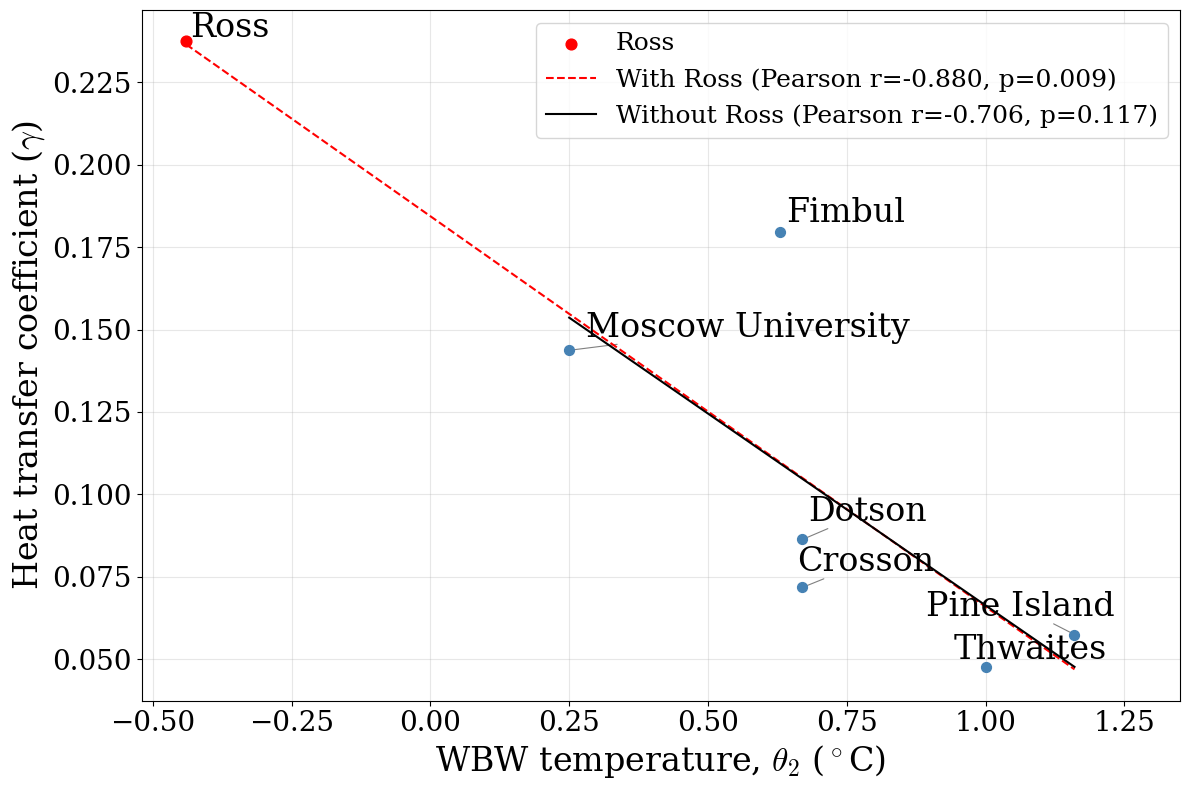

In [39]:


param_keys = ['T2']
param_labels = ['CDW temperature, $\\theta_2$ ($^\circ$C)']

fig, ax_main = plt.subplots(1, 1, figsize=(12, 8)) 
axes_list = [ax_main]

for ax, key, label in zip(axes_list, param_keys, param_labels):
    x_data, y_data = [], []
    x_no_ross, y_no_ross = [], []
    texts = []
    for name, res in plot_results.items():
        if name == 'Cook':
            continue
        plot_name = label_map.get(name, name)    
        m_calc = res.get('m_calc')
        m_obs = melt_parameters[name].get('obs_m')
        
        if m_calc is None or m_obs is None or m_obs == 0:
            continue
            
        alpha_calc = m_obs / (m_calc )* 0.094
        val = res.get(key) if key in res else melt_parameters[name].get(key)
        
        if val is None:
            continue
            
        
        x_data.append(val)
        y_data.append(alpha_calc)
        
        # Store dataset without Ross
        if name != 'Ross':
            x_no_ross.append(val)
            y_no_ross.append(alpha_calc)
        
        # Plot points
        if name == 'Ross':
            ax.scatter(val, alpha_calc, color='red', s=60, zorder=4, label='Ross')
        else:
            ax.scatter(val, alpha_calc, color='steelblue', s=50, zorder=3)
        
        offsets = {
            'Moscow University': (-100, -20),   # shift left and up
            'Pine Island':       (-40, 10),   # shift left to avoid edge
            'Thwaites':          (-50, 10),    # shift down
            'Ross':              (5, 5), 
            'Dotson':            (-20, 10)      
        }

        texts.append(ax.annotate(plot_name, (val, alpha_calc),
                fontsize=24))
    
    adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle='-', color='gray', lw=0.8))
    
    if len(x_data) > 2:
        x_arr = np.array(x_data)
        y_arr = np.array(y_data)
        
       
        slope, intercept, r_value, p_lin, se = linregress(x_arr, y_arr)
        x_line = np.linspace(x_arr.min(), x_arr.max(), 100)
        ax.plot(x_line, slope * x_line + intercept, 'r--', lw=1.5,
                label=f'With Ross (Pearson r={r_value:.3f}, p={p_lin:.3f})')

    # --- WITHOUT Ross ---
    if len(x_no_ross) > 2:
        x_nr = np.array(x_no_ross)
        y_nr = np.array(y_no_ross)
        
        slope_nr, intercept_nr, r_nr, p_nr, _ = linregress(x_nr, y_nr)
        x_line_nr = np.linspace(x_nr.min(), x_nr.max(), 100)
        ax.plot(x_line_nr, slope_nr * x_line_nr + intercept_nr,
                'k-', lw=1.5, label=f'Without Ross (Pearson r={r_nr:.3f}, p={p_nr:.3f})')
    ax.set_xlim(left=ax.get_xlim()[0], right=1.35)
    ax.set_xlabel('WBW temperature, $\\theta_2$ ($^\circ$C)', fontsize=24)
    ax.set_ylabel('Heat transfer coefficient ($\gamma$)', fontsize=24)
    ax.legend(fontsize=18)
    ax.tick_params(axis='both', labelsize=20)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('gamma_vs_T2.pdf', bbox_inches='tight', pad_inches=0.1)
plt.show()

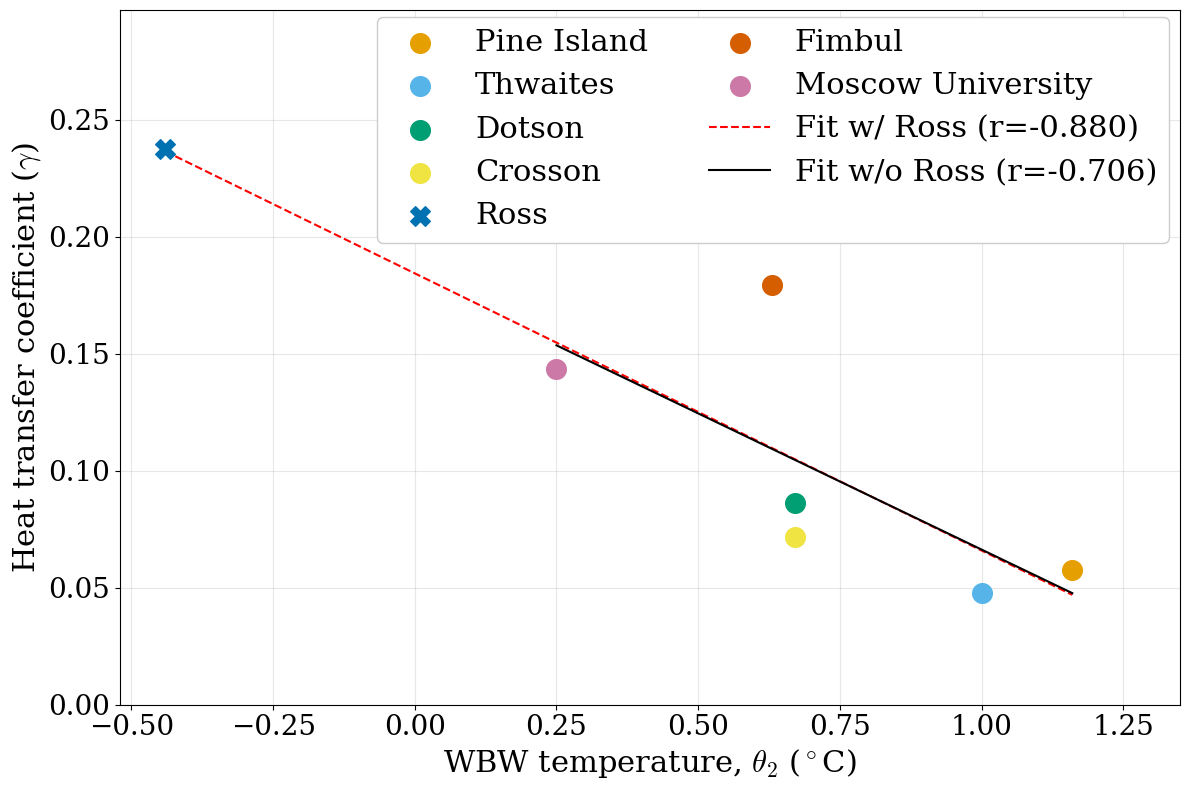

In [40]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import linregress 

param_keys = ['T2']
param_labels = [r'CDW temperature, $\theta_2$ ($^\circ$C)']

fig, ax_main = plt.subplots(1, 1, figsize=(12, 8)) 
axes_list = [ax_main]

okabe_ito = [
    '#E69F00', # Orange
    '#56B4E9', # Sky Blue
    '#009E73', # Bluish Green
    '#F0E442', # Yellow
    '#0072B2', # Blue
    '#D55E00', # Vermillion
    '#CC79A7', # Reddish Purple
    '#000000'  # Black
]

shelf_colors = {name: okabe_ito[i % len(okabe_ito)] for i, name in enumerate(plot_results.keys())}

label_map = {
    'Moscow_University': 'Moscow University',
    'PineIsland_East': 'Pine Island'
}

for ax, key, label in zip(axes_list, param_keys, param_labels):
    x_data, y_data = [], []
    x_no_ross, y_no_ross = [], []
    
    for name, res in plot_results.items():
        if name == 'Cook':
            continue
            
        plot_name = label_map.get(name, name)    
        m_calc = res.get('m_calc')
        m_obs = melt_parameters[name].get('obs_m')
        
        if m_calc is None or m_obs is None or m_obs == 0:
            continue
            
        alpha_calc = m_obs / (m_calc ) * 0.094
        val = res.get(key) if key in res else melt_parameters[name].get(key)
        
        if val is None:
            continue
            
        # Store full dataset
        x_data.append(val)
        y_data.append(alpha_calc)
        
        # Store dataset without Ross
        if name != 'Ross':
            x_no_ross.append(val)
            y_no_ross.append(alpha_calc)

        marker_shape = 'X' if name == 'Ross' else 'o'
        
        c = shelf_colors[name]
        ax.scatter(val, alpha_calc, color=c, marker=marker_shape, s=200, zorder=4, label=plot_name)
    
    if len(x_data) > 2:
        x_arr = np.array(x_data)
        y_arr = np.array(y_data)
        
        # --- WITH Ross ---
        slope, intercept, r_value, p_lin, se = linregress(x_arr, y_arr)
        x_line = np.linspace(x_arr.min(), x_arr.max(), 100)
        ax.plot(x_line, slope * x_line + intercept, 'r--', lw=1.5,
                label=f'Fit w/ Ross (r={r_value:.3f})')

    # --- WITHOUT Ross ---
    if len(x_no_ross) > 2:
        x_nr = np.array(x_no_ross)
        y_nr = np.array(y_no_ross)
        
        slope_nr, intercept_nr, r_nr, p_nr, _ = linregress(x_nr, y_nr)
        x_line_nr = np.linspace(x_nr.min(), x_nr.max(), 100)
        # Solid black line
        ax.plot(x_line_nr, slope_nr * x_line_nr + intercept_nr,
                'k-', lw=1.5, label=f'Fit w/o Ross (r={r_nr:.3f})')
                
    ax.set_xlim(left=ax.get_xlim()[0], right=1.35)
    ax.set_ylim(bottom=0, top=ax.get_ylim()[1]+0.05)
    ax.set_xlabel(r'WBW temperature, $\theta_2$ ($^\circ$C)', fontsize=22)
    ax.set_ylabel(r'Heat transfer coefficient ($\gamma$)', fontsize=22)
    
    ax.legend(fontsize=22, loc='upper right', ncol=2,
          bbox_to_anchor=(0.99, 0.99), framealpha=1.0,
          borderaxespad=0)
    ax.tick_params(axis='both', labelsize=20)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('gamma_vs_T2_colorblind.pdf', bbox_inches='tight', pad_inches=0.1)
plt.show()

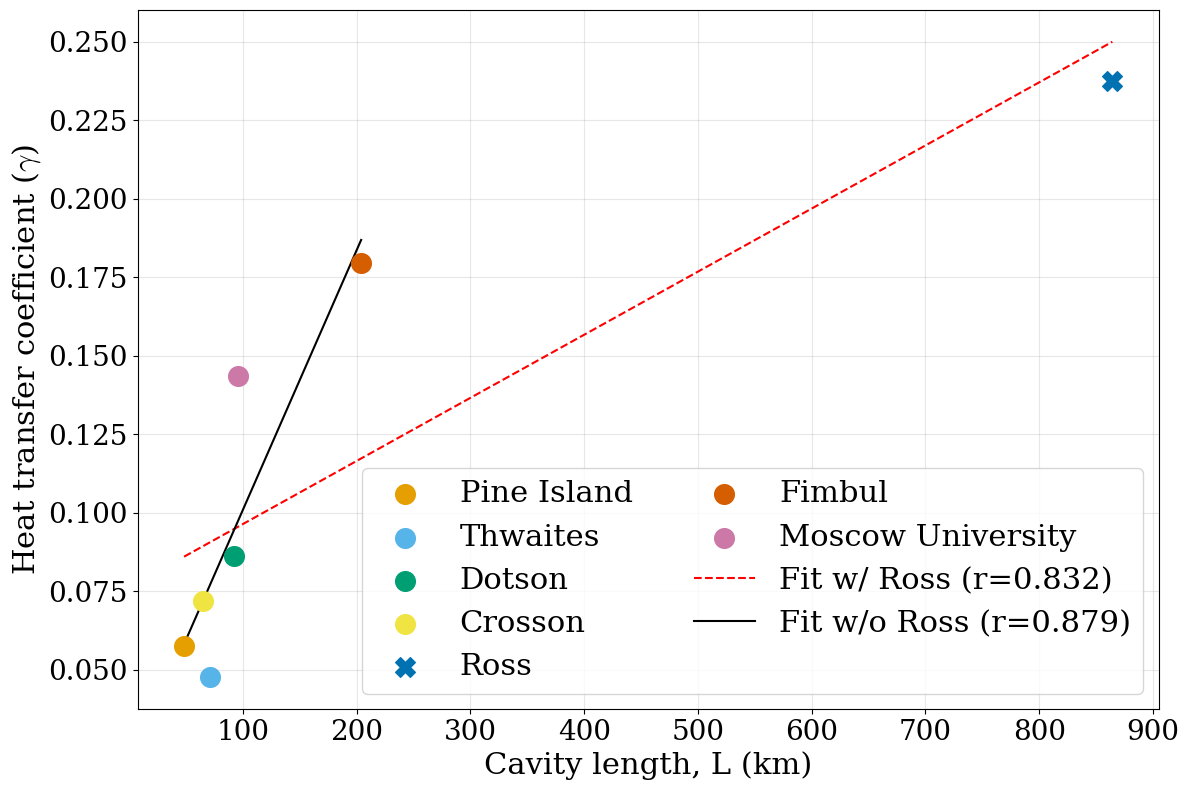

In [41]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import linregress

param_keys = ['cavity_length']
param_labels = ['Cavity length, L (km)']

fig, ax_main = plt.subplots(1, 1, figsize=(12, 8))
axes_list = [ax_main]

okabe_ito = [
    '#E69F00', '#56B4E9', '#009E73', '#F0E442', 
    '#0072B2', '#D55E00', '#CC79A7', '#000000'
]

shelf_colors = {name: okabe_ito[i % len(okabe_ito)] for i, name in enumerate(plot_results.keys())}

label_map = {
    'Moscow_University': 'Moscow University',
    'PineIsland_East': 'Pine Island'
}

for ax, key, label in zip(axes_list, param_keys, param_labels):
    x_data, y_data = [], []
    x_no_ross, y_no_ross = [], []
    
    for name, res in plot_results.items():
        if name == 'Cook':
            continue
            
        plot_name = label_map.get(name, name)
        m_calc = res.get('m_calc')
        m_obs = melt_parameters[name].get('obs_m')
        
        if m_calc is None or m_obs is None or m_obs == 0:
            continue
            
        alpha_calc = m_obs / (m_calc) * 0.094
        val = res.get(key) if key in res else melt_parameters[name].get(key)
        
        if val is None:
            continue
            
        # Store full dataset
        x_data.append(val)
        y_data.append(alpha_calc)
        
        # Store dataset without Ross
        if name != 'Ross':
            x_no_ross.append(val)
            y_no_ross.append(alpha_calc)
        marker_shape = 'X' if name == 'Ross' else 'o'

        c = shelf_colors[name]
        ax.scatter(val, alpha_calc, color=c, marker=marker_shape, s=200, zorder=4, label=plot_name)

    if len(x_data) > 2:
        x_arr = np.array(x_data)
        y_arr = np.array(y_data)
        
        # --- WITH Ross ---
        slope, intercept, r_value, p_lin, se = linregress(x_arr, y_arr)
        x_line = np.linspace(x_arr.min(), x_arr.max(), 100)
        ax.plot(x_line, slope * x_line + intercept, 'r--', lw=1.5,
                label=f'Fit w/ Ross (r={r_value:.3f})')

    # --- WITHOUT Ross ---
    if len(x_no_ross) > 2:
        x_nr = np.array(x_no_ross)
        y_nr = np.array(y_no_ross)
        
        slope_nr, intercept_nr, r_nr, p_nr, _ = linregress(x_nr, y_nr)
        x_line_nr = np.linspace(x_nr.min(), x_nr.max(), 100)
        ax.plot(x_line_nr, slope_nr * x_line_nr + intercept_nr,
                'k-', lw=1.5, label=f'Fit w/o Ross (r={r_nr:.3f})')

    ax.set_xlabel(label, fontsize=22)
    ax.set_ylabel(r'Heat transfer coefficient ($\gamma$)', fontsize=22)
    ax.tick_params(axis='both', labelsize=20)

    ax.legend(fontsize=22, loc='best', ncol=2)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('gamma_vs_cavity_length_colorblind.pdf', bbox_inches='tight', pad_inches=0.1)
plt.show()

── Including Ross ───────────────────────────────────────
Mean alpha = 0.1177,  std = 0.0659

Shelf                        alpha  z-score
PineIsland_East             0.0575    -0.91σ
Thwaites                    0.0476    -1.06σ
Dotson                      0.0863    -0.48σ
Crosson                     0.0718    -0.70σ
Ross                        0.2374     1.82σ
Fimbul                      0.1795     0.94σ
Moscow_University           0.1437     0.39σ

── Excluding Ross ───────────────────────────────────────
Mean alpha = 0.0977,  std = 0.0478

Shelf                        alpha  z-score
PineIsland_East             0.0575    -0.84σ
Thwaites                    0.0476    -1.05σ
Dotson                      0.0863    -0.24σ
Crosson                     0.0718    -0.54σ
Fimbul                      0.1795     1.71σ
Moscow_University           0.1437     0.96σ

Ross z-score (vs no-Ross distribution): 2.92σ


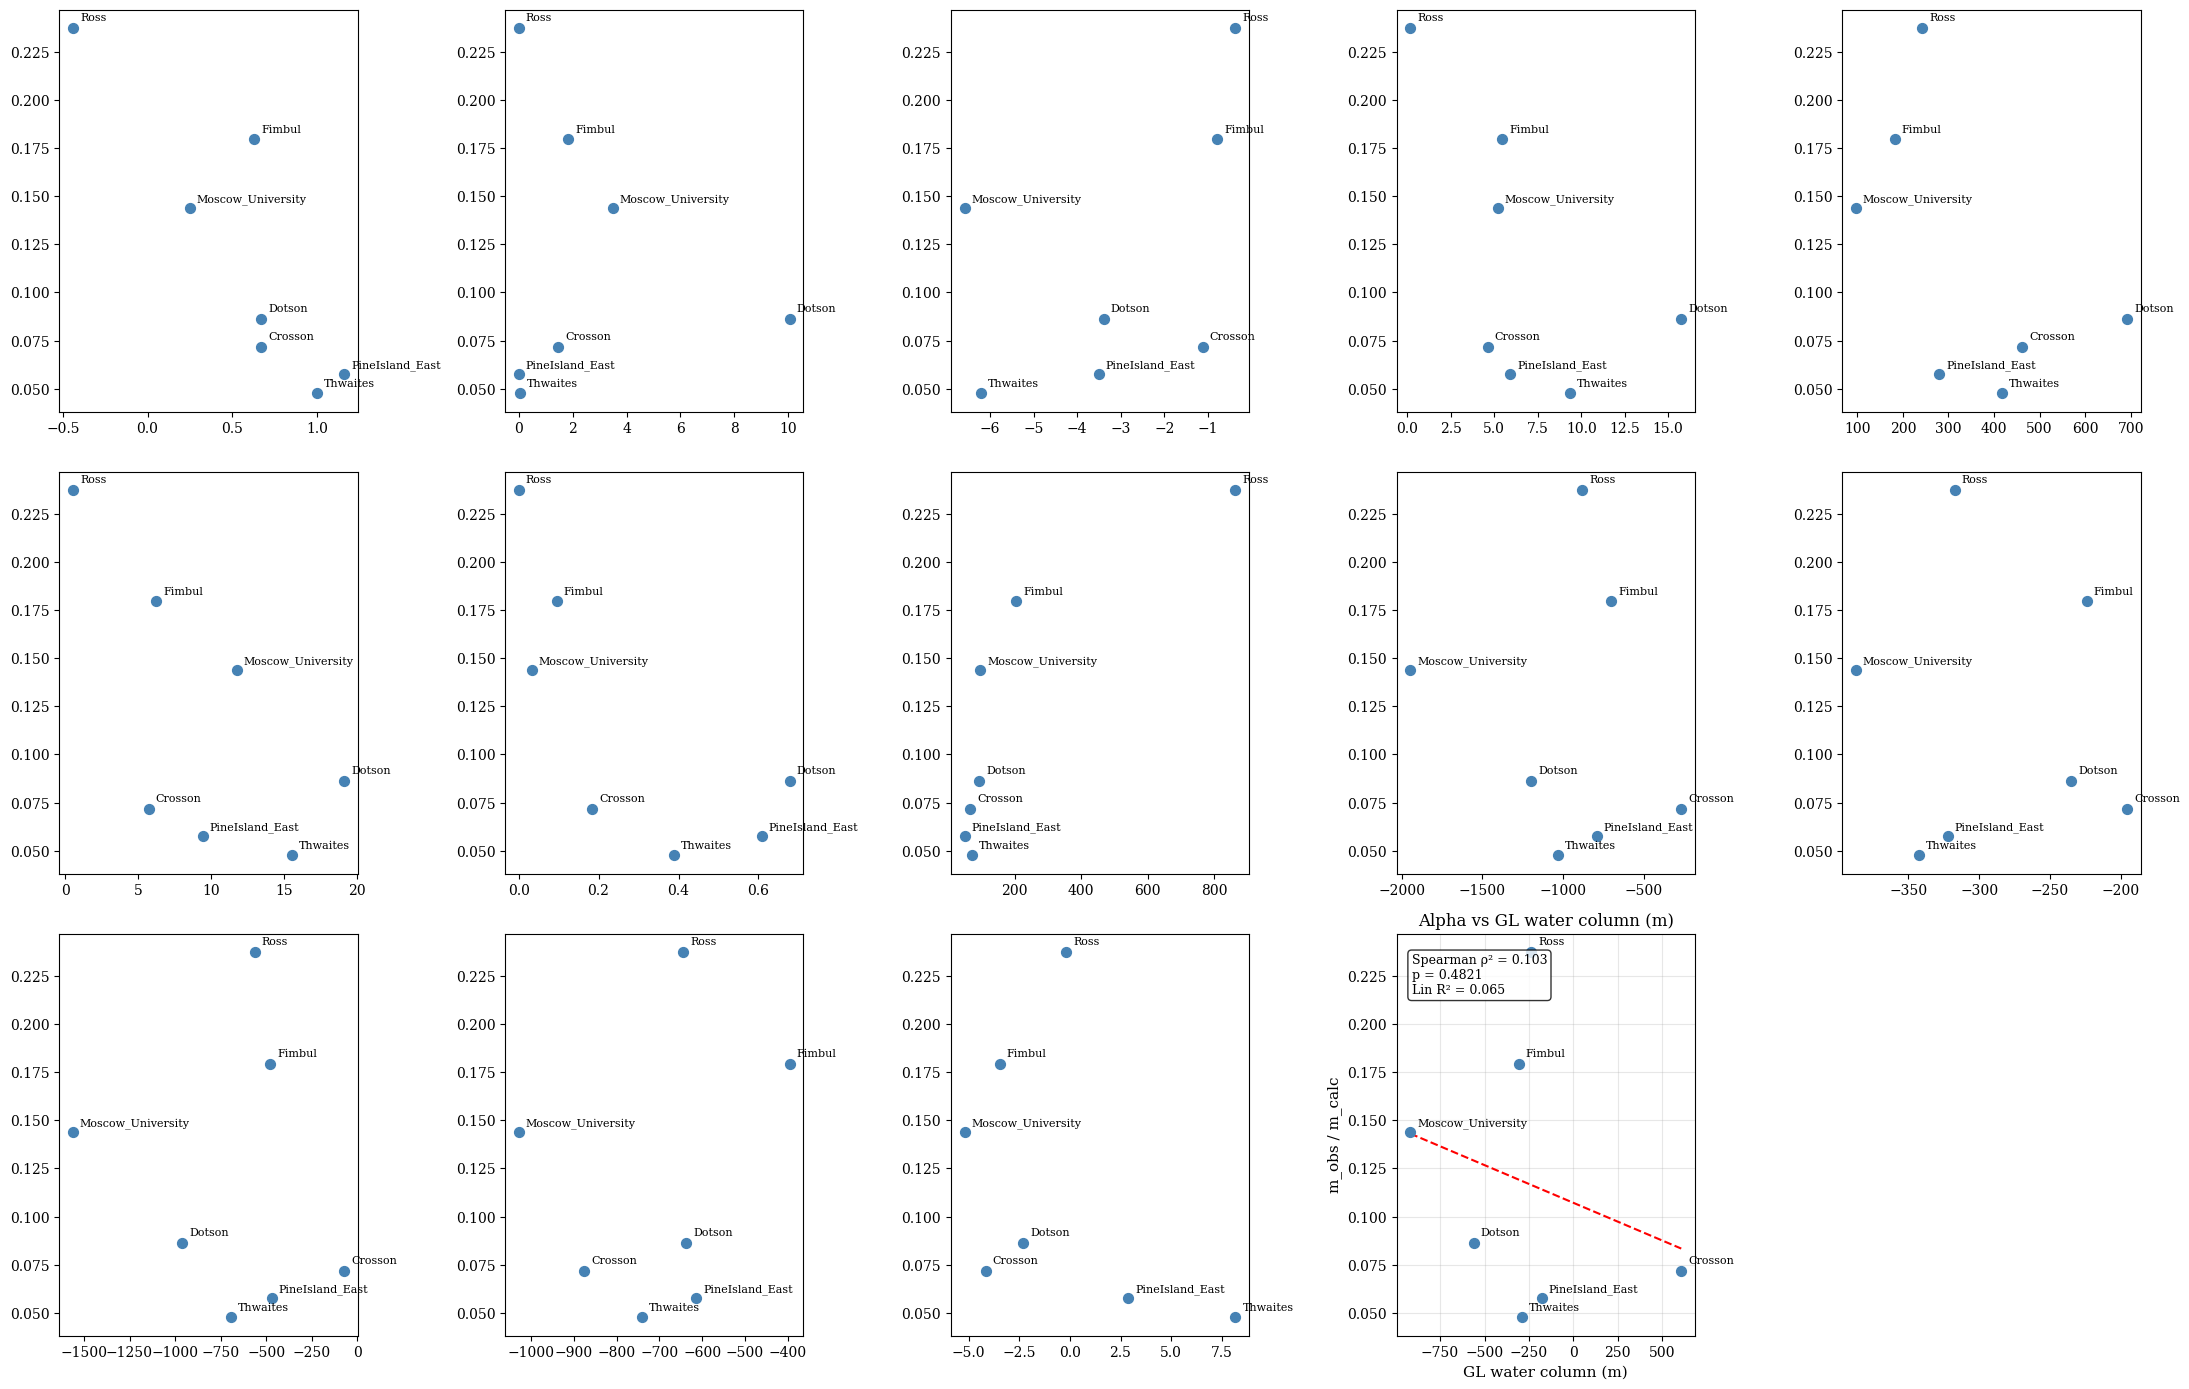

In [42]:
from scipy import stats
from scipy.stats import spearmanr

param_keys = [
    'T2', 'beta',
    'avg_Hprime', 'avg_Dprime', 'avg_wc', 'avg_water_prime', 'avg_D_double_prime',
    # geometry
    'cavity_length', 'H_at_GL', 'H_at_front', 'delta_draft',
    'D_at_GL', 'seabed_slope', 'wc_at_GL',
]

param_labels = [
    'T₂ (°C)', 'Beta',
    'Mean |dH/dy| (m/km)', 'Mean |dD/dy| (m/km)', 'Mean cavity height (m)',
    'Mean water column slope (m/km)', 'Mean |d²D/dy²| (m/km²)',
    # geometry
    'Cavity length (km)', 'GL draft (m)', 'Front draft (m)', 'Draft range (m)',
    'GL seabed depth (m)', 'Mean seabed slope (m/km)', 'GL water column (m)',
]
fig, axes = plt.subplots(3, 5, figsize=(22, 14))
axes = axes.flatten()

for ax, key, label in zip(axes, param_keys, param_labels):
    x_data, y_data = [], []
    
    for name, res in plot_results.items():
        

        if name =='Cook':
            continue
        m_calc = res.get('m_calc')
        m_obs  = melt_parameters[name].get('obs_m')
        if m_calc is None or m_obs is None or m_obs == 0:
            continue
        alpha_calc = m_obs / (m_calc )* 0.094

        val = res.get(key) if key in res else melt_parameters[name].get(key)
        if val is None:
            continue
            
        x_data.append(val)
        y_data.append(alpha_calc)
        
        ax.scatter(val, alpha_calc, color='steelblue', s=50, zorder=3)
        ax.annotate(name, (val, alpha_calc), xytext=(5, 5), textcoords='offset points', fontsize=8)
    # ── Alpha for all shelves including Ross ──────────────────────────────────────
alpha_all = {}
for name, res in plot_results.items():
    if name == 'Cook':
        continue
    m_calc = res.get('m_calc')
    m_obs  = melt_parameters[name].get('obs_m')
    if m_calc is None or m_obs is None or m_obs == 0:
        continue
    alpha_all[name] = m_obs / m_calc * 0.094

# ── Stats including Ross ──────────────────────────────────────────────────────
alpha_vals_all = np.array(list(alpha_all.values()))
mean_all  = np.mean(alpha_vals_all)
std_all   = np.std(alpha_vals_all)

print("── Including Ross ───────────────────────────────────────")
print(f"Mean alpha = {mean_all:.4f},  std = {std_all:.4f}")
print(f"\n{'Shelf':<25} {'alpha':>8} {'z-score':>8}")
for name, a in alpha_all.items():
    z = (a - mean_all) / std_all
    print(f"{name:<25} {a:>8.4f} {z:>8.2f}σ")

# ── Stats excluding Ross ──────────────────────────────────────────────────────
alpha_no_ross = {k: v for k, v in alpha_all.items() if k != 'Ross'}
alpha_vals_nr = np.array(list(alpha_no_ross.values()))
mean_nr = np.mean(alpha_vals_nr)
std_nr  = np.std(alpha_vals_nr)

print("\n── Excluding Ross ───────────────────────────────────────")
print(f"Mean alpha = {mean_nr:.4f},  std = {std_nr:.4f}")
print(f"\n{'Shelf':<25} {'alpha':>8} {'z-score':>8}")
for name, a in alpha_no_ross.items():
    z = (a - mean_nr) / std_nr
    print(f"{name:<25} {a:>8.4f} {z:>8.2f}σ")

# ── Ross z-score within the no-Ross distribution ─────────────────────────────
if 'Ross' in alpha_all:
    ross_z = (alpha_all['Ross'] - mean_nr) / std_nr
    print(f"\nRoss z-score (vs no-Ross distribution): {ross_z:.2f}σ")
    if len(x_data) > 2:
        x_arr = np.array(x_data)
        y_arr = np.array(y_data)

        rho, p = spearmanr(x_arr, y_arr)
        slope, intercept, r_value, p_lin, se = stats.linregress(x_arr, y_arr)
        x_line = np.linspace(x_arr.min(), x_arr.max(), 100)
        ax.plot(x_line, slope * x_line + intercept, 'r--', lw=1.5, zorder=2)

        stats_text = (f"Spearman ρ² = {rho**2:.3f}\n"
                      f"p = {p:.4f}\n"
                      f"Lin R² = {r_value**2:.3f}")
        ax.text(0.05, 0.95, stats_text, transform=ax.transAxes, verticalalignment='top',
                bbox=dict(boxstyle='round', facecolor='white', alpha=0.8), fontsize=9)

    ax.set_xlabel(label, fontsize=11)
    ax.set_ylabel('m_obs / m_calc', fontsize=11)
    ax.set_title(f'Alpha vs {label}', fontsize=12)
    ax.grid(True, alpha=0.3)

axes[-1].set_visible(False)
plt.tight_layout()
plt.show()

In [43]:


shelf_points = {}

for name, res in results.items():
    l_km = res['l']  
    
    if res['best_coeffs'] is not None:
        b_seabed = res['best_coeffs'][-2]  
    else:
        continue
    
    D_at_front = np.polyval(res['best_coeffs'], res['cavity_extent'] - res['d_cavity_start'])
    H_gl_val = -res['z_ice_at_start']   # convert to positive depth
    D_f_val  = -D_at_front              # convert to positive depth
    delta_D_shelf = H_gl_val - D_f_val  
    
    shelf_points[name] = {
        'l': l_km,
        'delta_D': delta_D_shelf,
    }
    print(f"{name:20s}  l={l_km:.1f} km   delta_D={delta_D_shelf:.0f} m")

Thwaites              l=19.6 km   delta_D=-253 m
Dotson                l=29.9 km   delta_D=-638 m
Crosson               l=18.8 km   delta_D=-328 m
PineIsland_East       l=9.1 km   delta_D=-200 m
PineIsland_West       l=317831.3 km   delta_D=-114 m
Ross                  l=63.1 km   delta_D=138 m
Fimbul                l=32.6 km   delta_D=279 m
Moscow_University     l=105.4 km   delta_D=10 m
Cook                  l=730867.3 km   delta_D=-380 m


In [44]:
import json
shelf_export = {}
for name, res in results.items():
    if res['best_coeffs'] is None:
        continue
    
    H_gl_shelf = -res['z_ice_at_start']          
    D_f_shelf  = -np.polyval(res['best_coeffs'], res['cavity_extent'])  # bed at ice front
    L_shelf    = res['cavity_extent']            
    
    shelf_export[name] = {
        'l': res['l'],                                        
        'cavity_length': res['d_front'],                      
        'H_gl_minus_Df_over_L': float((H_gl_shelf - D_f_shelf) / L_shelf),  # m/km
    }

print(json.dumps(shelf_export, indent=2))

{
  "Thwaites": {
    "l": 19.636431235773028,
    "cavity_length": 80.0,
    "H_gl_minus_Df_over_L": -6.222230419354177
  },
  "Dotson": {
    "l": 29.93230650933973,
    "cavity_length": 125.0,
    "H_gl_minus_Df_over_L": 0.511515380201067
  },
  "Crosson": {
    "l": 18.834636414301894,
    "cavity_length": 65.0,
    "H_gl_minus_Df_over_L": -5.050918225432025
  },
  "PineIsland_East": {
    "l": 9.097746789670655,
    "cavity_length": 60.0,
    "H_gl_minus_Df_over_L": -8.705695295531498
  },
  "PineIsland_West": {
    "l": 317831.3283477534,
    "cavity_length": 60.0,
    "H_gl_minus_Df_over_L": -3.4167140224110293
  },
  "Ross": {
    "l": 63.08031563265784,
    "cavity_length": 900.0,
    "H_gl_minus_Df_over_L": 0.16309672062621025
  },
  "Fimbul": {
    "l": 32.559606139869096,
    "cavity_length": 239.5,
    "H_gl_minus_Df_over_L": 3.3582759422490542
  },
  "Moscow_University": {
    "l": 105.3708003983872,
    "cavity_length": 162.5,
    "H_gl_minus_Df_over_L": 5.53009307436448

In [46]:
def spatial_m_bedmap(y, coeffs, H_f, delta_H, y_start, y_f, A, T2, l, beta):
    """
    Returns local melt rate (m/yr) at position y (scalar or array).
    """
    Tf    = -1.9
    g     = 9.8
    rho_1 = 1027.55
    rho_2 = 1027.75
    rho_i = 917
    L     = 3.34e5
    f     = 1e-4
    alpha = 0.0509 # optimal alpha from before        
    C_p   = 3974          

    k = alpha * (T2 - Tf) * g * (rho_2 - rho_1) * C_p / (rho_i * L * f * (beta + 1))

    y = np.asarray(y)
    cavity_length = y_f - y_start
    W_km = A / cavity_length

    H     = H_f + delta_H * np.exp(-y / l)
    dHdy  = -(delta_H / l) * np.exp(-y / l)          # m/km
    p2    = np.polyval(coeffs, y - y_start)            # seabed in m

    wc    = np.maximum(H - p2, 0.0)                    # water column (m)
    slope = np.abs(dHdy)                               # |dH/dy| (m/km)

    seconds_per_yr = 60 * 60 * 24 * 365

    # local melt rate in m/yr  (units: k [m/s per (m * m/km)] * wc [m] * slope [m/km])
    # k has implicit /km from the overturning integral, so we multiply by 1 km here
    m_local = wc * slope /1e6/W_km* k * seconds_per_yr          # m/yr at each y

    return m_local

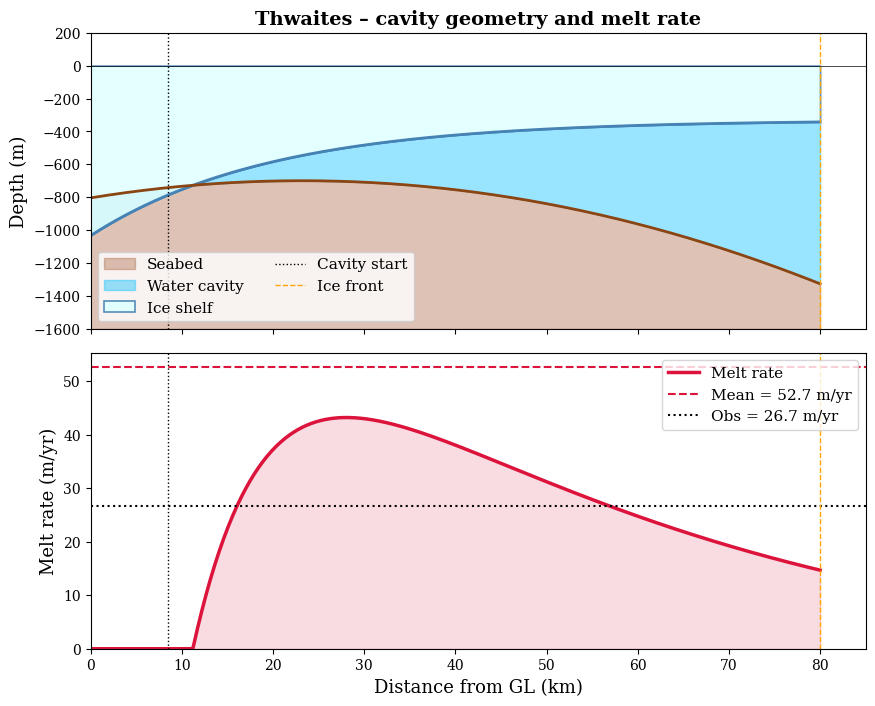

In [47]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True,
                                gridspec_kw={'hspace': 0.08})

name   = "Thwaites"
res    = results[name]
params = melt_parameters[name]

y_start = res['d_cavity_start']
y_f     = res['d_front']
y_arr   = np.linspace(0, y_f, 500)

H_arr  = res['H_f'] + res['delta_H'] * np.exp(-y_arr / res['l'])
p2_arr = np.polyval(res['best_coeffs'], y_arr - y_start)

# ── Top: geometry ─────────────────────────────────────────────────────────────
ax1.fill_between(y_arr, p2_arr, -1600, color='sienna',       alpha=0.35, label='Seabed')
ax1.fill_between(y_arr, H_arr,  p2_arr, color='deepskyblue', alpha=0.4,  label='Water cavity')
ax1.fill_between(y_arr, H_arr,  0,      color='lightcyan',   alpha=0.9,
                 edgecolor='steelblue', lw=1.2,               label='Ice shelf')
ax1.plot(y_arr, H_arr,  color='steelblue',   lw=2)
ax1.plot(y_arr, p2_arr, color='saddlebrown', lw=2)
ax1.axhline(0, color='k', lw=0.5)
ax1.axvline(y_start, color='k', lw=1, ls=':',  label='Cavity start')
ax1.axvline(y_f,     color='orange', lw=1, ls='--', label='Ice front')
ax1.set_ylim(-1600, 200)
ax1.set_xlim(0, y_f + 5)
ax1.set_ylabel('Depth (m)', fontsize=13)
ax1.set_title('Thwaites – cavity geometry and melt rate', fontsize=14, fontweight='bold')
ax1.legend(loc='lower left', fontsize=11, ncol=2)
ax1.tick_params(axis='x', labelbottom=False)

# ── Bottom: melt rate ─────────────────────────────────────────────────────────
m_local = spatial_m_bedmap(
    y=y_arr, coeffs=res['best_coeffs'], H_f=res['H_f'], delta_H=res['delta_H'],
    y_start=y_start, y_f=y_f, A=params['A'], T2=params['T2'],
    l=res['l'], beta=params['beta']
)

ax2.plot(y_arr, m_local, color='crimson', lw=2.5, label='Melt rate')
ax2.fill_between(y_arr, m_local, alpha=0.15, color='crimson')
ax2.axhline(res['m_calc'], color='crimson', ls='--', lw=1.5,
            label=f"Mean = {res['m_calc']:.1f} m/yr")
ax2.axhline(params['obs_m'], color='k', ls=':', lw=1.5,
            label=f"Obs = {params['obs_m']:.1f} m/yr")
ax2.axvline(y_start, color='k',      lw=1,   ls=':')
ax2.axvline(y_f,     color='orange', lw=1,   ls='--')
ax2.set_ylim(0, None)
ax2.set_xlim(0, y_f + 5)
ax2.set_xlabel('Distance from GL (km)', fontsize=13)
ax2.set_ylabel('Melt rate (m/yr)', fontsize=13)
ax2.legend(loc='upper right', fontsize=11)

plt.savefig('thwaites_melt_stacked.pdf', bbox_inches='tight')
plt.show()

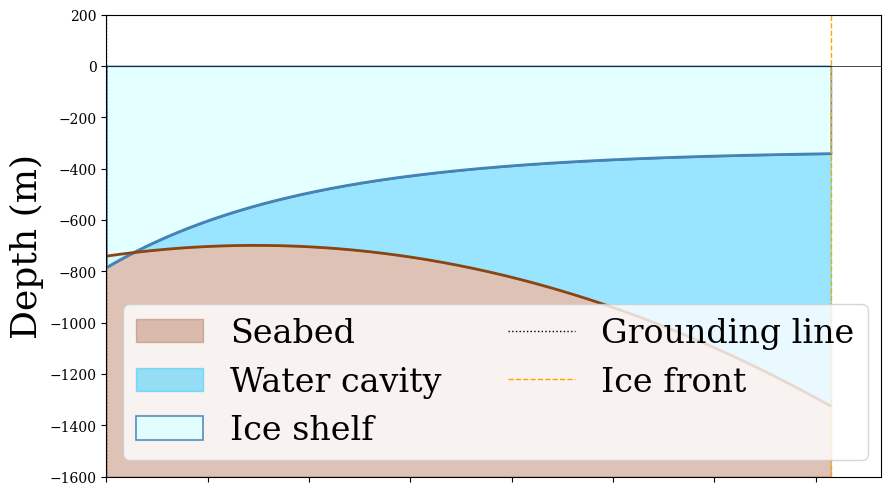

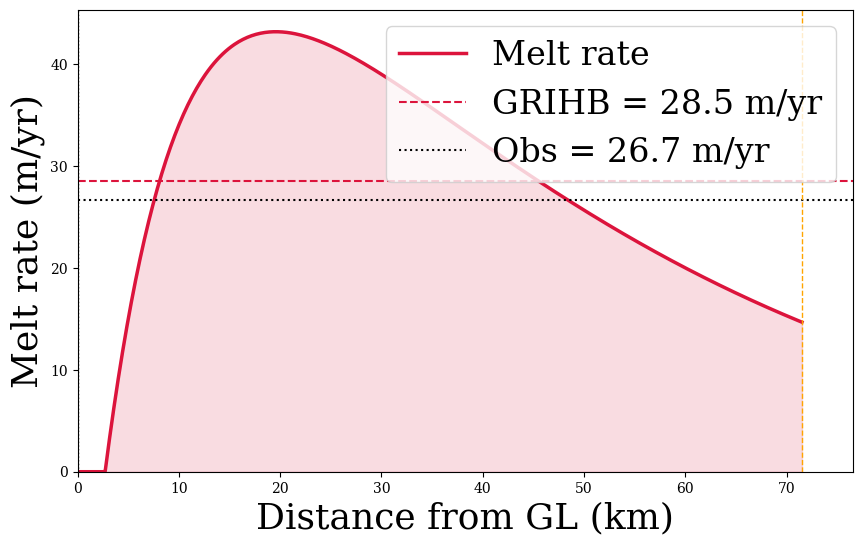

In [48]:
# ---------------- Top figure ----------------
fig1, ax1 = plt.subplots(figsize=(10, 6))


name   = "Thwaites"
res    = results[name]
params = melt_parameters[name]

y_start = res['d_cavity_start']
y_f     = res['d_front']
y_arr   = np.linspace(y_start, y_f, 500)
y_arr_plot = y_arr - y_start          # GL = 0

H_arr  = res['H_f'] + res['delta_H'] * np.exp(-y_arr / res['l'])
p2_arr = np.polyval(res['best_coeffs'], y_arr - y_start)

# ── Top: geometry ─────────────────────────────────────────────────────────────
ax1.fill_between(y_arr_plot, p2_arr, -1600, color='sienna',       alpha=0.35, label='Seabed')
ax1.fill_between(y_arr_plot, H_arr,  p2_arr, color='deepskyblue', alpha=0.4,  label='Water cavity')
ax1.fill_between(y_arr_plot, H_arr,  0,      color='lightcyan',   alpha=0.9,
                 edgecolor='steelblue', lw=1.2,                    label='Ice shelf')
ax1.plot(y_arr_plot, H_arr,  color='steelblue',   lw=2)
ax1.plot(y_arr_plot, p2_arr, color='saddlebrown', lw=2)
ax1.axhline(0, color='k', lw=0.5)
ax1.axvline(0,               color='k',      lw=1, ls=':',  label='Grounding line')
ax1.axvline(y_f - y_start,   color='orange', lw=1, ls='--', label='Ice front')
ax1.set_ylim(-1600, 200)
ax1.set_xlim(0, y_f - y_start + 5)
ax1.set_ylabel('Depth (m)', fontsize=26)
ax1.legend(loc='lower left', fontsize=24, ncol=2)
ax1.tick_params(axis='x', labelbottom=False)

fig1.savefig("thwaites_geometry.pdf", bbox_inches="tight", pad_inches=0.1)


# ---------------- Bottom figure ----------------
fig2, ax2 = plt.subplots(figsize=(10, 6))


# ── Bottom: melt rate ─────────────────────────────────────────────────────────
m_local = spatial_m_bedmap(
    y=y_arr, coeffs=res['best_coeffs'], H_f=res['H_f'], delta_H=res['delta_H'],
    y_start=y_start, y_f=y_f, A=params['A'], T2=params['T2'],
    l=res['l'], beta=params['beta']
)

ax2.plot(y_arr_plot, m_local, color='crimson', lw=2.5, label='Melt rate')
ax2.fill_between(y_arr_plot, m_local, alpha=0.15, color='crimson')
ax2.axhline(res['m_calc']*0.0509/0.094, color='crimson', ls='--', lw=1.5,
            label=f"GRIHB = {res['m_calc']*0.0509/0.094:.1f} m/yr")
ax2.axhline(params['obs_m'], color='k', ls=':', lw=1.5,
            label=f"Obs = {params['obs_m']:.1f} m/yr")
ax2.axvline(0,             color='k',      lw=1, ls=':')
ax2.axvline(y_f - y_start, color='orange', lw=1, ls='--')
ax2.set_ylim(0, None)
ax2.set_xlim(0, y_f - y_start + 5)
ax2.set_xlabel('Distance from GL (km)', fontsize=26)
ax2.set_ylabel('Melt rate (m/yr)', fontsize=26)
ax2.legend(loc='upper right', fontsize=24)

fig2.savefig("thwaites_melt_rate.pdf", bbox_inches="tight", pad_inches=0.1)

plt.show()


plt.show()

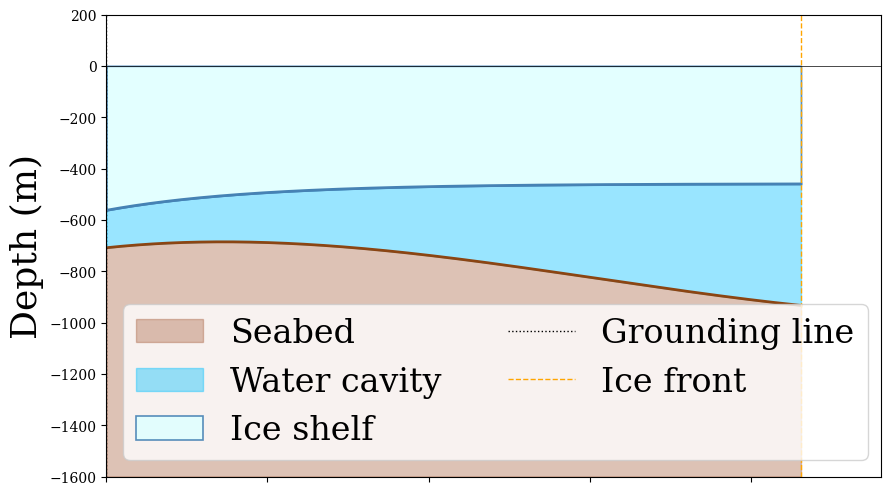

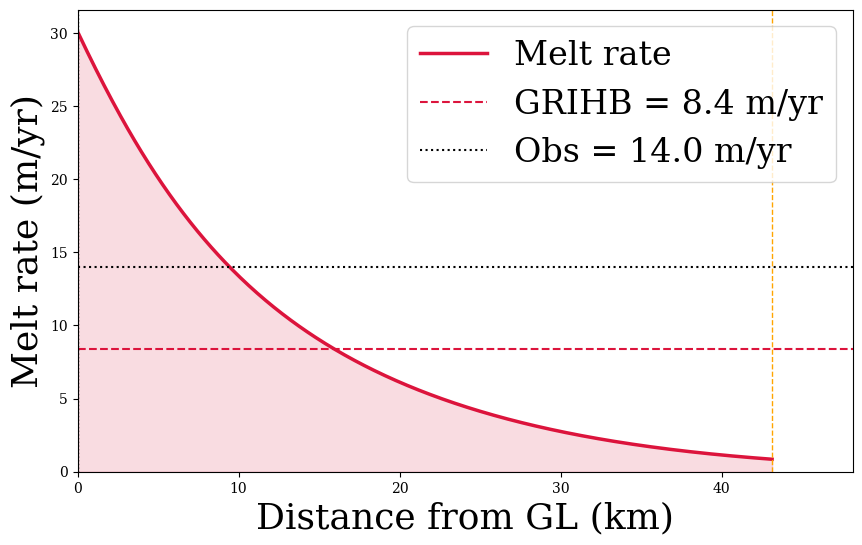

In [49]:
# ---------------- Top figure ----------------
fig1, ax1 = plt.subplots(figsize=(10, 6))


name   = "PineIsland_East"
res    = results[name]
params = melt_parameters[name]

y_start = res['d_cavity_start']
y_f     = res['d_front']
y_arr   = np.linspace(y_start, y_f, 500)
y_arr_plot = y_arr - y_start          # GL = 0

H_arr  = res['H_f'] + res['delta_H'] * np.exp(-y_arr / res['l'])
p2_arr = np.polyval(res['best_coeffs'], y_arr - y_start)

# ── Top: geometry ─────────────────────────────────────────────────────────────
ax1.fill_between(y_arr_plot, p2_arr, -1600, color='sienna',       alpha=0.35, label='Seabed')
ax1.fill_between(y_arr_plot, H_arr,  p2_arr, color='deepskyblue', alpha=0.4,  label='Water cavity')
ax1.fill_between(y_arr_plot, H_arr,  0,      color='lightcyan',   alpha=0.9,
                 edgecolor='steelblue', lw=1.2,                    label='Ice shelf')
ax1.plot(y_arr_plot, H_arr,  color='steelblue',   lw=2)
ax1.plot(y_arr_plot, p2_arr, color='saddlebrown', lw=2)
ax1.axhline(0, color='k', lw=0.5)
ax1.axvline(0,               color='k',      lw=1, ls=':',  label='Grounding line')
ax1.axvline(y_f - y_start,   color='orange', lw=1, ls='--', label='Ice front')
ax1.set_ylim(-1600, 200)
ax1.set_xlim(0, y_f - y_start + 5)
ax1.set_ylabel('Depth (m)', fontsize=26)
ax1.legend(loc='lower left', fontsize=24, ncol=2)
ax1.tick_params(axis='x', labelbottom=False)

fig1.savefig("pine_island_east_geometry.pdf", bbox_inches="tight", pad_inches=0.1)


# ---------------- Bottom figure ----------------
fig2, ax2 = plt.subplots(figsize=(10, 6))


# ── Bottom: melt rate ─────────────────────────────────────────────────────────
m_local = spatial_m_bedmap(
    y=y_arr, coeffs=res['best_coeffs'], H_f=res['H_f'], delta_H=res['delta_H'],
    y_start=y_start, y_f=y_f, A=params['A'], T2=params['T2'],
    l=res['l'], beta=params['beta']
)

ax2.plot(y_arr_plot, m_local, color='crimson', lw=2.5, label='Melt rate')
ax2.fill_between(y_arr_plot, m_local, alpha=0.15, color='crimson')
ax2.axhline(res['m_calc']*0.0509/0.094, color='crimson', ls='--', lw=1.5,
            label=f"GRIHB = {res['m_calc']*0.0509/0.094:.1f} m/yr")
ax2.axhline(params['obs_m'], color='k', ls=':', lw=1.5,
            label=f"Obs = {params['obs_m']:.1f} m/yr")
ax2.axvline(0,             color='k',      lw=1, ls=':')
ax2.axvline(y_f - y_start, color='orange', lw=1, ls='--')
ax2.set_ylim(0, None)
ax2.set_xlim(0, y_f - y_start + 5)
ax2.set_xlabel('Distance from GL (km)', fontsize=26)
ax2.set_ylabel('Melt rate (m/yr)', fontsize=26)
ax2.legend(loc='upper right', fontsize=24)

fig2.savefig("pine_island_eastmelt_rate.pdf", bbox_inches="tight", pad_inches=0.1)

plt.show()


plt.show()